# AI-Driven Cybersecurity Risk Assessment and Privacy-Preserving Threat Detection for Organisational Resilience and Business Continuity

**Implementation Notebook**





| Proposal element | Where it is addressed in this notebook |
|---|---|
| **O1** — Design an AI/ML cyber risk-assessment framework for threat detection and risk prioritisation | Sections 3, 9 |
| **O2** — Implement a privacy-preserving prototype using federated learning + differential privacy | Sections 5, 6 |
| **O3** — Evaluate with quantitative and qualitative measures against defined success thresholds | Sections 4–10 |
| **RQ1** — Can a federated, differentially private IDS match a centralised baseline? | Sections 4, 5, 6, 10 |
| **RQ2** — What is the measurable privacy–utility trade-off as ε tightens? | Section 6 |
| **RQ3** — How can private detection outputs become interpretable risk scores supporting continuity decisions? | Section 9 |
| **Success criterion — Detection** (federated F1 within 5% of centralised) | Section 10 |
| **Success criterion — Privacy** (accuracy loss ≤ 5 pp at ε ≤ 1.0) | Sections 6, 10 |
| **Success criterion — Robustness** (resistance to membership-inference attack) | Sections 7, 10 |
| **Success criterion — Practicality** (communication overhead and training time) | Sections 8, 10 |

### Before you run

1. **Runtime → Change runtime type → T4 GPU**, then **Runtime → Run all**.
2. Allow the Google Drive mount prompt when it appears (Section 0.4).
3. All outputs are written to `MyDrive/fed_ids_project/` under a timestamped run folder.

### Ethical statement

This work uses only public, anonymised benchmark intrusion-detection datasets. No human participants and no
personal or proprietary organisational data are involved. All techniques implemented here are **defensive**:
the membership-inference component in Section 7 is a standard privacy-audit measurement used to quantify how
much protection differential privacy provides, in line with the proposal's evaluation criteria.

## Section 0 — Environment setup

We prepare the runtime before touching any data: confirm the GPU, install the libraries, mount Google Drive,
create the folder structure, and fix the random seeds so results are reproducible.

### 0.1 Confirm the GPU is available

In [1]:
# Show which GPU Colab has allocated to this session.
# Expected: a Tesla T4 with ~15GB of memory.
!nvidia-smi

Fri Aug 14 13:56:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

> **If you see `command not found` or no GPU listed**, go to *Runtime → Change runtime type → Hardware
> accelerator → T4 GPU*, then re-run this cell. The notebook will still run on CPU but will be much slower.

### 0.2 Install the project libraries

In [2]:
!pip install -q --force-reinstall "numpy==2.0.2" "numba>=0.60,<0.61" "shap>=0.46,<0.47"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 kB 3.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 6.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.2/19.2 MB 102.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 123.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 543.9/543.9 kB 46.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.9/43.9 MB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 129.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 95.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35

In [3]:
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "--force-reinstall",
    "numpy==2.0.2",
    "numba==0.60.0",
    "shap==0.46.0"
])

print("Packages installed successfully.")
print("IMPORTANT: Restart the runtime/kernel now, then run Cell 2.")

Packages installed successfully.
IMPORTANT: Restart the runtime/kernel now, then run Cell 2.


### 0.3 Import libraries and record versions

In [4]:
!pip install -q --no-deps opacus --progress-bar off
print("Installation step finished.")

Installation step finished.


In [5]:
import sys
import subprocess

# 1. Inject a runtime patch to trick NumPy 2.x into bypassing the removed warning attribute
import numpy as np
if not hasattr(np, '_no_nep50_warning'):
    def dummy_npwarn_decorator_factory():
        def npwarn_decorator(x):
            return x
        return npwarn_decorator
    np._no_nep50_warning = dummy_npwarn_decorator_factory

# 2. Standard Imports (Will now successfully bypass the internal AttributeError)
import os
import json
import time
import math
import copy
import random
import hashlib
import zipfile
import warnings
import platform
from datetime import datetime

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from IPython.display import display

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report, average_precision_score)

import xgboost as xgb
import shap
import opacus
from opacus import PrivacyEngine
from opacus.accountants import RDPAccountant
from opacus.accountants.utils import get_noise_multiplier

warnings.filterwarnings("ignore")

VERSIONS = {
    "python": sys.version.split()[0],
    "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__,
    "torch": torch.__version__, "xgboost": xgb.__version__, "shap": shap.__version__,
    "opacus": opacus.__version__, "matplotlib": matplotlib.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only",
}
for k, v in VERSIONS.items():
    print(f"{k:>16}: {v}")


          python: 3.12.13
           numpy: 2.0.2
          pandas: 3.0.5
         sklearn: 1.9.0
           torch: 2.11.0+cu128
         xgboost: 3.3.0
            shap: 0.46.0
          opacus: 1.6.0
      matplotlib: 3.10.0
  cuda_available: True
        gpu_name: Tesla T4


### 0.4 Mount Google Drive

In [6]:
# Mounting Drive means every figure, table, model and log survives after the Colab session ends.
from google.colab import drive
drive.mount('/content/drive')
print("Drive mounted.")

Mounted at /content/drive
Drive mounted.


> **Not running in Google Colab?** Replace the two lines above with
> `DRIVE_ROOT = '/some/local/folder'` and skip to the next cell — everything else works unchanged.

### 0.5 Create the project folder structure on Drive

In [7]:
DRIVE_ROOT   = "/content/drive/MyDrive"
PROJECT_NAME = "fed_ids_project"
PROJECT_DIR  = os.path.join(DRIVE_ROOT, PROJECT_NAME)

# A timestamped run folder keeps each experiment's evidence separate and traceable.
RUN_ID  = datetime.now().strftime("run_%Y%m%d_%H%M%S")
RUN_DIR = os.path.join(PROJECT_DIR, "runs", RUN_ID)

PATHS = {
    "project":   PROJECT_DIR,
    "data_raw":  os.path.join(PROJECT_DIR, "data", "raw"),        # shared across runs (downloaded once)
    "data_proc": os.path.join(RUN_DIR, "data_processed"),
    "figures":   os.path.join(RUN_DIR, "figures"),
    "tables":    os.path.join(RUN_DIR, "tables"),
    "models":    os.path.join(RUN_DIR, "models"),
    "logs":      os.path.join(RUN_DIR, "logs"),
    "results":   os.path.join(RUN_DIR, "results"),
    "evidence":  os.path.join(RUN_DIR, "evidence"),
    "run":       RUN_DIR,
}
for p in PATHS.values():
    os.makedirs(p, exist_ok=True)

print("Run ID:", RUN_ID)
for k, v in PATHS.items():
    print(f"  {k:>10} -> {v}")

Run ID: run_20260814_135842
     project -> /content/drive/MyDrive/fed_ids_project
    data_raw -> /content/drive/MyDrive/fed_ids_project/data/raw
   data_proc -> /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/data_processed
     figures -> /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures
      tables -> /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables
      models -> /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/models
        logs -> /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/logs
     results -> /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/results
    evidence -> /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/evidence
         run -> /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842


### 0.6 Verify the folders were actually created

In [8]:
# Never assume a step worked - check it.
all_ok = True
for k, v in PATHS.items():
    exists = os.path.isdir(v)
    all_ok &= exists
    print(f"{'OK ' if exists else 'MISSING'}  {k:>10}  {v}")
print("\nAll folders present." if all_ok else "\nPROBLEM: some folders are missing.")

OK      project  /content/drive/MyDrive/fed_ids_project
OK     data_raw  /content/drive/MyDrive/fed_ids_project/data/raw
OK    data_proc  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/data_processed
OK      figures  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures
OK       tables  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables
OK       models  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/models
OK         logs  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/logs
OK      results  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/results
OK     evidence  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/evidence
OK          run  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842

All folders present.


### 0.7 Master experiment configuration

Every parameter that controls the experiment lives in one place. This is the only cell you need to edit to
change the scale, the dataset or the privacy budgets being swept.

`SAMPLE_FRACTION` sets the proportion of the dataset used, drawn with **stratified sampling** so every attack
class keeps its relative representation. Lowering it produces a faster pilot run; setting it to `1.0` runs the
full dataset for the final reported results.

In [9]:
CONFIG = {
    # ---------------- Experiment identity ----------------
    "run_id": RUN_ID,
    "researcher": "anonymous",
    "seed": 42,

    # ---------------- Dataset ----------------
    "dataset": "NSL_KDD",          # "NSL_KDD" | "UNSW_NB15" | "CICIDS2017"
    "sample_fraction": 1.0,       # 0.05 = pilot scale | 1.0 = full dataset
    "test_size_internal": 0.20,    # held-out split taken from the training file
    "min_rows_per_class": 5,       # protects rare classes (U2R) during stratified sampling

    # ---------------- Neural detector ----------------
    "hidden_1": 128,
    "hidden_2": 64,
    "dropout": 0.2,
    "batch_size": 256,
    "learning_rate": 1e-3,

    # ---------------- Centralised baseline ----------------
    "central_epochs": 15,

    # ---------------- Federated learning ----------------
    "n_clients": 5,                # simulated partner organisations
    "fl_rounds": 15,
    "local_epochs": 2,
    "dirichlet_alpha": 0.5,        # lower = more non-IID (more realistic heterogeneity)

    # ---------------- Differential privacy ----------------
    "epsilons": [0.5, 1.0, 3.0, 5.0, 10.0],   # privacy budgets to sweep for RQ2
    "max_grad_norm": 1.0,          # per-sample gradient clipping bound C
    "delta_mode": "1/n",           # delta = 1 / (client training set size)

    # ---------------- Privacy audit ----------------
    "audit_canaries": 250,         # mislabelled records inserted to measure worst-case memorisation
    "audit_rounds": 30,            # dedicated audit run: more rounds so memorisation can appear
    "audit_local_epochs": 6,       # heavy repetition over a small client set drives memorisation
    "audit_dropout": 0.0,          # regularisation disabled: the audit is a worst-case test

    # ---------------- Risk / continuity layer ----------------
    "xgb_estimators": 300,
    "xgb_max_depth": 6,
    "xgb_learning_rate": 0.15,
    "shap_sample_size": 500,       # rows explained by SHAP (kept modest: SHAP is compute-heavy)
    "containment_factor": 0.25,    # residual disruption once an attack is detected early
    "annualisation_factor": 12,    # observation window assumed to represent one month of telemetry

    # ---------------- Statistical rigour ----------------
    "n_seeds": 3,                  # independent replications for mean +/- std and significance tests

    # ---------------- Ablation studies ----------------
    "fedprox_mu_values": [0.0, 0.01, 0.1],       # mu=0 is exactly FedAvg
    "sensitivity_client_counts": [3, 5, 10],
    "sensitivity_alphas": [0.1, 0.5, 5.0],

    # ---------------- Success thresholds (from proposal Section 2.4) ----------------
    "threshold_f1_relative_drop": 0.05,   # federated F1 within 5% of centralised
    "threshold_acc_drop_pp": 5.0,         # <= 5 percentage points accuracy loss at eps <= 1.0
    "threshold_epsilon": 1.0,
}

print(json.dumps(CONFIG, indent=2))

{
  "run_id": "run_20260814_135842",
  "researcher": "anonymous",
  "seed": 42,
  "dataset": "NSL_KDD",
  "sample_fraction": 1.0,
  "test_size_internal": 0.2,
  "min_rows_per_class": 5,
  "hidden_1": 128,
  "hidden_2": 64,
  "dropout": 0.2,
  "batch_size": 256,
  "learning_rate": 0.001,
  "central_epochs": 15,
  "n_clients": 5,
  "fl_rounds": 15,
  "local_epochs": 2,
  "dirichlet_alpha": 0.5,
  "epsilons": [
    0.5,
    1.0,
    3.0,
    5.0,
    10.0
  ],
  "max_grad_norm": 1.0,
  "delta_mode": "1/n",
  "audit_canaries": 250,
  "audit_rounds": 30,
  "audit_local_epochs": 6,
  "audit_dropout": 0.0,
  "xgb_estimators": 300,
  "xgb_max_depth": 6,
  "xgb_learning_rate": 0.15,
  "shap_sample_size": 500,
  "containment_factor": 0.25,
  "annualisation_factor": 12,
  "n_seeds": 3,
  "fedprox_mu_values": [
    0.0,
    0.01,
    0.1
  ],
  "sensitivity_client_counts": [
    3,
    5,
    10
  ],
  "sensitivity_alphas": [
    0.1,
    0.5,
    5.0
  ],
  "threshold_f1_relative_drop": 0.05,
  "

### 0.8 Fix random seeds and select the compute device

In [10]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(CONFIG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Seed fixed at:", CONFIG["seed"])
print("Compute device:", DEVICE)

Seed fixed at: 42
Compute device: cuda


### 0.9 Evidence helpers

Two small helper functions do the housekeeping for the whole notebook: `save_fig()` writes every figure to
Drive as both PNG (for the dissertation body) and PDF (vector, for print), and `save_table()` writes every
table as CSV and LaTeX. Both register the artefact in an **evidence manifest** so Section 10 can produce a
complete, auditable list of everything the run produced.

In [11]:
EVIDENCE = []   # running manifest of every artefact produced

# Force the inline backend so every figure renders in the notebook itself.
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
    "figure.autolayout": False,
})
PALETTE = {"central": "#2E5A88", "federated": "#E08A2B", "dp": "#5B8C5A",
           "accent": "#A4433B", "grey": "#6C757D"}


def _sha1(path, blocks=8192):
    h = hashlib.sha1()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(blocks), b""):
            h.update(chunk)
    return h.hexdigest()[:12]


def save_fig(fig, name, caption, section):
    # Save a figure to Drive in PNG + PDF and register it as evidence.
    png = os.path.join(PATHS["figures"], f"{name}.png")
    pdf = os.path.join(PATHS["figures"], f"{name}.pdf")
    fig.savefig(png, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")

    # Render the figure inline in the notebook as well as writing it to Drive, so the
    # evidence is visible while reading and the saved copy is available for the write-up.
    try:
        display(fig)
    except Exception:
        pass
    plt.close(fig)

    EVIDENCE.append({"type": "figure", "name": name, "section": section,
                     "caption": caption, "path": png, "sha1": _sha1(png)})
    print(f"[SAVED] {name}.png / .pdf  ->  {PATHS['figures']}")
    return png


def save_table(df, name, caption, section, index=False):
    # Save a DataFrame to Drive in CSV + LaTeX and register it as evidence.
    csv = os.path.join(PATHS["tables"], f"{name}.csv")
    tex = os.path.join(PATHS["tables"], f"{name}.tex")
    df.to_csv(csv, index=index)
    try:
        df.to_latex(tex, index=index, float_format="%.4f", caption=caption, label=f"tab:{name}")
    except Exception as e:
        print("  (LaTeX export skipped:", e, ")")
    EVIDENCE.append({"type": "table", "name": name, "section": section,
                     "caption": caption, "path": csv, "sha1": _sha1(csv),
                     "rows": int(len(df)), "cols": int(df.shape[1])})
    print(f"[TABLE SAVED ] {name}.csv / .tex  ({len(df)} rows x {df.shape[1]} cols)")
    return csv


def stratified_subsample(df, col, frac, seed, min_n):
    # Sample a fraction of each class independently, with a floor so rare attack
    # families (U2R, Heartbleed) are never sampled out of existence entirely.
    if frac >= 1.0:
        return df.reset_index(drop=True)
    parts = []
    for value, group in df.groupby(col):
        n = min(len(group), max(min_n, int(round(len(group) * frac))))
        parts.append(group.sample(n=n, random_state=seed))
    return pd.concat(parts).sample(frac=1.0, random_state=seed).reset_index(drop=True)


def log_line(msg):
    stamp = datetime.now().strftime("%H:%M:%S")
    line = f"[{stamp}] {msg}"
    print(line)
    with open(os.path.join(PATHS["logs"], "run_log.txt"), "a") as f:
        f.write(line + "\n")


RESULTS = {"config": CONFIG, "versions": VERSIONS}   # everything numeric ends up here
log_line(f"Run {RUN_ID} initialised on {VERSIONS['gpu_name']}")

[13:58:44] Run run_20260814_135842 initialised on Tesla T4


### 0.10 Save the environment record

In [12]:
env_df = pd.DataFrame(list(VERSIONS.items()) + [("run_id", RUN_ID), ("device", str(DEVICE))],
                      columns=["component", "value"])
display(env_df)
save_table(env_df, "table_00_environment", "Software environment and hardware used for the experiments", "0")

,component,value
0,python,3.12.13
1,numpy,2.0.2
2,pandas,3.0.5
3,sklearn,1.9.0
4,torch,2.11.0+cu128
5,xgboost,3.3.0
6,shap,0.46.0
7,opacus,1.6.0
8,matplotlib,3.10.0
9,cuda_available,True


[TABLE SAVED ] table_00_environment.csv / .tex  (13 rows x 2 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_00_environment.csv'

---
## Section 1 — Data acquisition and first inspection

The proposal (Appendix 1) identifies three public benchmark intrusion-detection datasets. Two of them are
implemented here as fully working, interchangeable loaders selected by `CONFIG["dataset"]`:

| Dataset | Records (train / test) | Attack families | Role in this study |
|---|---|---|---|
| **NSL-KDD** | 125,973 / 22,544 | 4 (DoS, Probe, R2L, U2R) | Primary dataset; the most widely used IDS benchmark, so results are directly comparable with the published literature |
| **UNSW-NB15** | 175,341 / 82,332 | 9 (Exploits, Fuzzers, Generic, DoS, Reconnaissance, Analysis, Backdoor, Shellcode, Worms) | Cross-dataset validation; modern synthetic traffic with richer flow features |

Using both matters for the credibility of the conclusions. NSL-KDD derives from traffic captured in 1998–99
and is routinely criticised as unrepresentative of contemporary networks; a finding that holds *only* on
NSL-KDD is weak evidence about privacy-preserving detection in general. UNSW-NB15 was generated in 2015 with
a different feature schema, different attack taxonomy and a harder class balance, so replicating the
privacy–utility behaviour across both (Section 11) tests whether the conclusions are properties of the method
or artefacts of one dataset.

CICIDS2017 is not auto-downloaded because it is distributed as multi-gigabyte files behind an
authenticated portal. A manual path is provided in Section 1.2 for anyone who has obtained it.

### 1.1 Define the dataset registry

In [13]:
# Each dataset is described by a self-contained specification: where to get it, how to
# read it, which columns are categorical, and how its native labels map onto a common
# schema. Everything downstream consumes the standardised output, so adding a dataset
# means adding an entry here rather than editing the pipeline.

NSL_KDD_COLUMNS = [
    'duration','protocol_type','service','flag','src_bytes','dst_bytes','land',
    'wrong_fragment','urgent','hot','num_failed_logins','logged_in','num_compromised',
    'root_shell','su_attempted','num_root','num_file_creations','num_shells',
    'num_access_files','num_outbound_cmds','is_host_login','is_guest_login','count',
    'srv_count','serror_rate','srv_serror_rate','rerror_rate','srv_rerror_rate',
    'same_srv_rate','diff_srv_rate','srv_diff_host_rate','dst_host_count',
    'dst_host_srv_count','dst_host_same_srv_rate','dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate','dst_host_srv_diff_host_rate','dst_host_serror_rate',
    'dst_host_srv_serror_rate','dst_host_rerror_rate','dst_host_srv_rerror_rate',
    'label','difficulty'
]

# NSL-KDD ships one label per attack signature; the literature groups them into four families.
NSL_KDD_CATEGORY_MAP = {
    'normal': 'Normal',
    'neptune':'DoS','back':'DoS','land':'DoS','pod':'DoS','smurf':'DoS','teardrop':'DoS',
    'mailbomb':'DoS','apache2':'DoS','processtable':'DoS','udpstorm':'DoS','worm':'DoS',
    'ipsweep':'Probe','nmap':'Probe','portsweep':'Probe','satan':'Probe','mscan':'Probe','saint':'Probe',
    'ftp_write':'R2L','guess_passwd':'R2L','imap':'R2L','multihop':'R2L','phf':'R2L','spy':'R2L',
    'warezclient':'R2L','warezmaster':'R2L','sendmail':'R2L','named':'R2L','snmpgetattack':'R2L',
    'snmpguess':'R2L','xlock':'R2L','xsnoop':'R2L','httptunnel':'R2L',
    'buffer_overflow':'U2R','loadmodule':'U2R','perl':'U2R','rootkit':'U2R','ps':'U2R',
    'sqlattack':'U2R','xterm':'U2R',
}

DATASET_REGISTRY = {
    "NSL_KDD": {
        "display_name": "NSL-KDD",
        "citation": "Tavallaee et al. (2009), Canadian Institute for Cybersecurity",
        "format": "csv_no_header",
        "columns": NSL_KDD_COLUMNS,
        "categorical": ['protocol_type', 'service', 'flag'],
        "drop_columns": ['difficulty'],       # metadata annotation, not a network feature
        "label_column": "label",
        "category_map": NSL_KDD_CATEGORY_MAP,
        "normal_label": "Normal",
        "expected_rows": {"train": 125973, "test": 22544},
        "files": {
            "train": {
                "filename": "KDDTrain+.txt",
                "urls": [
                    "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
                    "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt",
                    "https://raw.githubusercontent.com/HoaNP/NSL-KDD-DataSet/master/KDDTrain%2B.txt",
                ]},
            "test": {
                "filename": "KDDTest+.txt",
                "urls": [
                    "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt",
                    "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt",
                    "https://raw.githubusercontent.com/HoaNP/NSL-KDD-DataSet/master/KDDTest%2B.txt",
                ]},
        },
    },
    "UNSW_NB15": {
        "display_name": "UNSW-NB15",
        "citation": "Moustafa and Slay (2015), Cyber Range Lab, UNSW Canberra",
        "format": "parquet",
        "columns": None,                      # header is present in the file
        "categorical": ['proto', 'service', 'state'],
        "drop_columns": [],
        "label_column": "attack_cat",         # already a family-level label
        "category_map": None,                 # native categories used directly
        "normal_label": "Normal",
        "expected_rows": {"train": 175341, "test": 82332},
        "files": {
            "train": {
                "filename": "UNSW_NB15_training-set.parquet",
                "urls": ["https://raw.githubusercontent.com/mutio18/ML-based-IDS/main/"
                         "data/UNSW/UNSW_NB15_training-set.parquet"]},
            "test": {
                "filename": "UNSW_NB15_testing-set.parquet",
                "urls": ["https://raw.githubusercontent.com/mutio18/ML-based-IDS/main/"
                         "data/UNSW/UNSW_NB15_testing-set.parquet"]},
        },
    },
    "CICIDS2017": {
        "display_name": "CICIDS2017",
        "citation": "Sharafaldin, Lashkari and Ghorbani (2018), Canadian Institute for Cybersecurity",
        "format": "kaggle_multi_csv",
        "kaggle_slug": "chethuhn/network-intrusion-dataset",
        "columns": None,                      # headers present in each CSV
        "categorical": [],                    # all CICFlowMeter features are numeric
        "drop_columns": [],
        "label_column": "Label",
        "category_map": None,                 # mapped by normalised prefix (see below)
        "normal_label": "Normal",
        "expected_rows": None,                # no single published figure; varies by release
        "split_strategy": "stratified_holdout",   # no official train/test split exists
        "holdout_fraction": 0.30,
        "sample_on_load": True,               # 2.8M rows: subsample during load to fit in RAM
        "files": None,
    },
}

ACTIVE = DATASET_REGISTRY[CONFIG["dataset"]]
print(f"Active dataset : {ACTIVE['display_name']}")
print(f"Source         : {ACTIVE['citation']}")
print(f"Categorical    : {ACTIVE['categorical']}")
print(f"Expected rows  : {ACTIVE['expected_rows']}")
print(f"Split strategy : {ACTIVE.get('split_strategy', 'provided')}")
print(f"\nAvailable in the registry: {list(DATASET_REGISTRY)}")

Active dataset : NSL-KDD
Source         : Tavallaee et al. (2009), Canadian Institute for Cybersecurity
Categorical    : ['protocol_type', 'service', 'flag']
Expected rows  : {'train': 125973, 'test': 22544}
Split strategy : provided

Available in the registry: ['NSL_KDD', 'UNSW_NB15', 'CICIDS2017']


> **On provenance.** The URLs above are convenience mirrors that allow the notebook to run unattended. Both
> datasets are verified against their published record counts and class distributions in Section 1.3, so a
> corrupted or substituted mirror is detected rather than silently used. Cite the original sources listed in
> the `citation` field, not the mirrors.

### 1.2 Download the active dataset (cached on Drive after the first run)

In [14]:
import urllib.request

def download_with_fallback(filename, urls, dest_dir, min_bytes=100_000):
    # Try each mirror in turn; skip entirely if a valid copy is already cached on Drive.
    dest = os.path.join(dest_dir, filename)
    if os.path.exists(dest) and os.path.getsize(dest) > min_bytes:
        print(f"  cached   {filename}  ({os.path.getsize(dest):,} bytes)")
        return dest
    for i, url in enumerate(urls, 1):
        try:
            print(f"  trying mirror {i}: {url[:72]}...")
            urllib.request.urlretrieve(url, dest)
            size = os.path.getsize(dest)
            if size > min_bytes:
                print(f"  DOWNLOADED {filename}  ({size:,} bytes)")
                return dest
            print(f"  file too small ({size} bytes), trying next mirror")
        except Exception as e:
            print(f"  mirror {i} failed: {type(e).__name__}")
    raise RuntimeError(
        f"All mirrors failed for {filename}.\n"
        f"Place the file manually at: {dest}\n"
        f"then re-run this cell. Original source: {ACTIVE['citation']}")


def acquire_kaggle(spec):
    # CICIDS2017 is distributed as a Kaggle dataset of per-day CSV files. kagglehub
    # handles authentication and caching; the first call prompts for Kaggle credentials.
    try:
        import kagglehub
    except ImportError:
        print("  installing kagglehub...")
        import subprocess, sys as _sys
        subprocess.run([_sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub

    print(f"  downloading {spec['kaggle_slug']} (large: expect several minutes on first run)")
    root = kagglehub.dataset_download(spec["kaggle_slug"])
    print("  kagglehub cache path:", root)

    csvs = []
    for dirpath, _, filenames in os.walk(root):
        for fn in sorted(filenames):
            if fn.lower().endswith(".csv"):
                csvs.append(os.path.join(dirpath, fn))
    if not csvs:
        raise RuntimeError(f"No CSV files found under {root}")

    print(f"  found {len(csvs)} CSV file(s):")
    for c in csvs:
        print(f"    {os.path.basename(c)}  ({os.path.getsize(c)/1e6:.1f} MB)")
    return csvs


def acquire_dataset(spec, dest_dir):
    if spec["format"] == "kaggle_multi_csv":
        return {"csvs": acquire_kaggle(spec)}
    paths = {}
    for split in ("train", "test"):
        f = spec["files"][split]
        paths[split] = download_with_fallback(f["filename"], f["urls"], dest_dir)
    return paths

log_line(f"Acquiring {ACTIVE['display_name']}")
DATA_PATHS = acquire_dataset(ACTIVE, PATHS["data_raw"])
if ACTIVE["format"] == "kaggle_multi_csv":
    TRAIN_PATH = TEST_PATH = None
    print(f"\n{len(DATA_PATHS['csvs'])} source files ready; they are merged and split in Section 1.3.")
else:
    TRAIN_PATH, TEST_PATH = DATA_PATHS["train"], DATA_PATHS["test"]

[13:58:44] Acquiring NSL-KDD
  cached   KDDTrain+.txt  (19,109,424 bytes)
  cached   KDDTest+.txt  (3,441,513 bytes)


### 1.3 Load the data (merging and splitting where no official split exists)

In [15]:
# CICIDS2017 attack labels vary in spelling and whitespace between releases (some carry a
# non-ASCII dash in the Web Attack labels), so matching is done on a normalised string.
CICIDS_FAMILY_RULES = [
    ("benign",        "Normal"),
    ("ddos",          "DDoS"),
    ("dos",           "DoS"),
    ("portscan",      "PortScan"),
    ("port scan",     "PortScan"),
    ("bot",           "Bot"),
    ("ftp-patator",   "BruteForce"),
    ("ssh-patator",   "BruteForce"),
    ("patator",       "BruteForce"),
    ("brute force",   "WebAttack"),
    ("web attack",    "WebAttack"),
    ("xss",           "WebAttack"),
    ("sql injection", "WebAttack"),
    ("infiltration",  "Infiltration"),
    ("heartbleed",    "Heartbleed"),
]

def normalise_label(value):
    t = str(value).strip().lower()
    for ch in ("\u2013", "\u2014", "\u2011", "\ufffd"):     # dash variants and replacement chars
        t = t.replace(ch, "-")
    return " ".join(t.split())

def map_cicids_family(value):
    t = normalise_label(value)
    # 'ddos' must be tested before 'dos', hence the ordered rule list.
    for needle, family in CICIDS_FAMILY_RULES:
        if needle in t:
            return family
    return "Unknown"


def read_kaggle_csvs(spec, csv_paths, config):
    # Files are read one at a time, cleaned and (optionally) subsampled before being
    # concatenated. CICIDS2017 holds roughly 2.8 million flows; loading every row at full
    # precision would exhaust Colab's memory, so each file is downcast to float32 and
    # stratified-subsampled on the way in.
    frames = []
    for path in csv_paths:
        df = pd.read_csv(path, low_memory=False, encoding="latin-1")
        df.columns = [c.strip() for c in df.columns]

        label_col = next((c for c in df.columns if c.strip().lower() == "label"), None)
        if label_col is None:
            print(f"    skipping {os.path.basename(path)} - no Label column")
            continue

        df = df.rename(columns={label_col: "Label"})
        df = df.loc[:, ~df.columns.duplicated()]        # drops 'Fwd Header Length.1'

        num = df.columns.drop("Label")
        df[num] = df[num].apply(pd.to_numeric, errors="coerce").astype(np.float32)
        df["category"] = df["Label"].map(map_cicids_family)

        if spec.get("sample_on_load") and config["sample_fraction"] < 1.0:
            df = stratified_subsample(df, "category", config["sample_fraction"],
                                      config["seed"], config["min_rows_per_class"])

        print(f"    {os.path.basename(path):<58} {len(df):>8,} rows")
        frames.append(df)

    merged = pd.concat(frames, ignore_index=True)
    del frames
    print(f"\n  merged total: {len(merged):,} rows x {merged.shape[1]} columns")
    return merged


def read_split(spec, path):
    # One reader per declared format keeps the loader honest about what it supports.
    if spec["format"] == "csv_no_header":
        return pd.read_csv(path, names=spec["columns"])
    if spec["format"] == "parquet":
        return pd.read_parquet(path)
    if spec["format"] == "csv":
        return pd.read_csv(path)
    raise ValueError(f"Unsupported format: {spec['format']}")


log_line("Loading raw files into DataFrames")

if ACTIVE["format"] == "kaggle_multi_csv":
    merged = read_kaggle_csvs(ACTIVE, DATA_PATHS["csvs"], CONFIG)
    SAMPLING_APPLIED_AT_LOAD = bool(ACTIVE.get("sample_on_load")) and CONFIG["sample_fraction"] < 1.0

    # No official train/test partition is published for CICIDS2017, so a stratified
    # holdout is carved out here. This is declared explicitly because it means the
    # 'official test' results for this dataset are NOT comparable with published
    # figures in the way the NSL-KDD and UNSW-NB15 results are.
    tr_idx, te_idx = train_test_split(
        np.arange(len(merged)), test_size=ACTIVE["holdout_fraction"],
        random_state=CONFIG["seed"], stratify=merged["category"])
    df_train_raw = merged.iloc[tr_idx].reset_index(drop=True)
    df_test_raw  = merged.iloc[te_idx].reset_index(drop=True)
    del merged
    print(f"\n  stratified split applied ({1-ACTIVE['holdout_fraction']:.0%} / "
          f"{ACTIVE['holdout_fraction']:.0%}) - no published split exists for this dataset")
else:
    SAMPLING_APPLIED_AT_LOAD = False
    df_train_raw = read_split(ACTIVE, TRAIN_PATH)
    df_test_raw  = read_split(ACTIVE, TEST_PATH)

print(f"\nLoaded {ACTIVE['display_name']}: train {df_train_raw.shape} | test {df_test_raw.shape}")

[13:58:44] Loading raw files into DataFrames

Loaded NSL-KDD: train (125973, 43) | test (22544, 43)


### 1.3b Verify the loaded data against the published specification

In [16]:
integrity = []
for split, df in [("train", df_train_raw), ("test", df_test_raw)]:
    expected = (ACTIVE["expected_rows"] or {}).get(split)
    integrity.append({
        "dataset": ACTIVE["display_name"], "split": split,
        "rows_loaded": len(df), "columns": df.shape[1],
        "rows_published": expected if expected else "n/a (no published split)",
        "matches_published": (len(df) == expected) if expected else "n/a",
    })

integrity_df = pd.DataFrame(integrity)
display(integrity_df)

if ACTIVE["expected_rows"]:
    ok = all(len(d) == ACTIVE["expected_rows"][s]
             for s, d in [("train", df_train_raw), ("test", df_test_raw)])
    print("\nBoth splits match the published record counts exactly - integrity confirmed."
          if ok else
          "\nWARNING: record counts differ from the published specification. The mirror may be "
          "a modified copy; verify before reporting results.")
else:
    print(f"\n{ACTIVE['display_name']} has no single published record count "
          f"(release-dependent), so the count above is reported rather than checked.")
    if CONFIG["sample_fraction"] < 1.0 and SAMPLING_APPLIED_AT_LOAD:
        print(f"Note: sample_fraction={CONFIG['sample_fraction']} was applied during loading "
              f"to keep memory within Colab limits.")

save_table(integrity_df, "table_01_data_integrity",
           "Loaded dataset partitions verified against published specifications", "1")

,dataset,split,rows_loaded,columns,rows_published,matches_published
0,NSL-KDD,train,125973,43,125973,True
1,NSL-KDD,test,22544,43,22544,True



Both splits match the published record counts exactly - integrity confirmed.
[TABLE SAVED ] table_01_data_integrity.csv / .tex  (2 rows x 6 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_01_data_integrity.csv'

### 1.4 Standardise the labels into a common schema

In [17]:
# Every dataset is reduced to the same three-column contract so the rest of the
# notebook never needs to know which dataset it is working on:
#   'category' - attack family as a string ('Normal' for benign traffic)
#   'y'        - binary detection target (0 = benign, 1 = attack)
#   'label'    - the original native label, retained for traceability

def standardise_labels(df, spec):
    df = df.copy()
    if spec["drop_columns"]:
        df = df.drop(columns=[c for c in spec["drop_columns"] if c in df.columns])

    raw = df[spec["label_column"]].astype(str).str.strip()
    if "category" in df.columns:
        pass                                   # already mapped by the loader (CICIDS2017)
    elif spec["category_map"] is not None:
        df["category"] = raw.str.lower().map(spec["category_map"]).fillna("Unknown")
    else:
        df["category"] = raw.replace({"": spec["normal_label"], "nan": spec["normal_label"]})

    df["y"] = (df["category"] != spec["normal_label"]).astype(int)

    # Anything that encodes the answer must be removed explicitly, not left to chance.
    # UNSW-NB15 ships BOTH 'attack_cat' (the family) and 'label' (the binary target);
    # either one reaching the feature matrix would make the task trivial and every
    # result meaningless, so both are dropped and rebuilt from the standard schema.
    dropped = []
    for col in {spec["label_column"], "attack_cat", "Label", "class", "id", "difficulty"}:
        if col in df.columns and col not in ("category", "y"):
            df = df.drop(columns=[col])
            dropped.append(col)

    df["label"] = raw          # native label, retained for traceability only
    if dropped:
        print(f"  removed label-bearing / metadata columns: {sorted(dropped)}")
    return df


df_train_raw = standardise_labels(df_train_raw, ACTIVE)
df_test_raw  = standardise_labels(df_test_raw, ACTIVE)

CATEGORICAL_COLS = [c for c in ACTIVE["categorical"] if c in df_train_raw.columns]

print("Standardised schema applied.")
print("  train:", df_train_raw.shape, "| test:", df_test_raw.shape)
print("  categorical columns:", CATEGORICAL_COLS)
print("  attack families    :", sorted(df_train_raw['category'].unique()))

  removed label-bearing / metadata columns: ['label']
  removed label-bearing / metadata columns: ['label']
Standardised schema applied.
  train: (125973, 44) | test: (22544, 44)
  categorical columns: ['protocol_type', 'service', 'flag']
  attack families    : ['DoS', 'Normal', 'Probe', 'R2L', 'U2R']


### 1.5 Verify the standardisation

In [18]:
checks = {
    "'category' column created": "category" in df_train_raw.columns,
    "'y' column created": "y" in df_train_raw.columns,
    "y is strictly binary": set(df_train_raw['y'].unique()).issubset({0, 1}),
    "both classes present in train": df_train_raw['y'].nunique() == 2,
    "both classes present in test": df_test_raw['y'].nunique() == 2,
    "train and test share the same columns": set(df_train_raw.columns) == set(df_test_raw.columns),
    "no residual label leakage column": ACTIVE["label_column"] not in df_train_raw.columns
                                        or ACTIVE["label_column"] == "label",
}
for k, v in checks.items():
    print(f"{'PASS' if v else 'FAIL'}  {k}")
assert all(checks.values()), "Label standardisation failed - inspect the cells above."

unmapped = int((df_train_raw['category'] == 'Unknown').sum())
print(f"\nRecords with an unmapped signature in train: {unmapped:,}")
print("Attack rate - train: %.2f%% | test: %.2f%%"
      % (df_train_raw['y'].mean()*100, df_test_raw['y'].mean()*100))

PASS  'category' column created
PASS  'y' column created
PASS  y is strictly binary
PASS  both classes present in train
PASS  both classes present in test
PASS  train and test share the same columns
PASS  no residual label leakage column

Records with an unmapped signature in train: 0
Attack rate - train: 46.54% | test: 56.92%


### 1.6 View the first rows of the training data

In [19]:
display(df_train_raw.head(10))

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,category,y,label
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.03,0.17,0.00,0.00,0.00,0.05,0.00,Normal,0,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,0.60,0.88,0.00,0.00,0.00,0.00,0.00,Normal,0,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.05,0.00,0.00,1.00,1.00,0.00,0.00,DoS,1,neptune
3,0,tcp,http,SF,232,8153,0,0,0,0,...,0.00,0.03,0.04,0.03,0.01,0.00,0.01,Normal,0,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,Normal,0,normal
5,0,tcp,private,REJ,0,0,0,0,0,0,...,0.07,0.00,0.00,0.00,0.00,1.00,1.00,DoS,1,neptune
6,0,tcp,private,S0,0,0,0,0,0,0,...,0.05,0.00,0.00,1.00,1.00,0.00,0.00,DoS,1,neptune
7,0,tcp,private,S0,0,0,0,0,0,0,...,0.07,0.00,0.00,1.00,1.00,0.00,0.00,DoS,1,neptune
8,0,tcp,remote_job,S0,0,0,0,0,0,0,...,0.05,0.00,0.00,1.00,1.00,0.00,0.00,DoS,1,neptune
9,0,tcp,private,S0,0,0,0,0,0,0,...,0.06,0.00,0.00,1.00,1.00,0.00,0.00,DoS,1,neptune


### 1.7 Inspect column data types and memory usage

In [20]:
df_train_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 44 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  int64  
 1   protocol_type                125973 non-null  str    
 2   service                      125973 non-null  str    
 3   flag                         125973 non-null  str    
 4   src_bytes                    125973 non-null  int64  
 5   dst_bytes                    125973 non-null  int64  
 6   land                         125973 non-null  int64  
 7   wrong_fragment               125973 non-null  int64  
 8   urgent                       125973 non-null  int64  
 9   hot                          125973 non-null  int64  
 10  num_failed_logins            125973 non-null  int64  
 11  logged_in                    125973 non-null  int64  
 12  num_compromised              125973 non-null  int64  
 13  root_shell

### 1.8 Statistical summary of the numeric features

In [21]:
display(df_train_raw.describe().T.head(20))

,count,mean,std,min,25%,50%,75%,max
duration,125973.0,287.144650,2.604515e+03,0.0,0.0,0.0,0.0,4.290800e+04
src_bytes,125973.0,45566.743000,5.870331e+06,0.0,0.0,44.0,276.0,1.379964e+09
dst_bytes,125973.0,19779.114421,4.021269e+06,0.0,0.0,0.0,516.0,1.309937e+09
land,125973.0,0.000198,1.408607e-02,0.0,0.0,0.0,0.0,1.000000e+00
wrong_fragment,125973.0,0.022687,2.535300e-01,0.0,0.0,0.0,0.0,3.000000e+00
urgent,125973.0,0.000111,1.436603e-02,0.0,0.0,0.0,0.0,3.000000e+00
hot,125973.0,0.204409,2.149968e+00,0.0,0.0,0.0,0.0,7.700000e+01
num_failed_logins,125973.0,0.001222,4.523914e-02,0.0,0.0,0.0,0.0,5.000000e+00
logged_in,125973.0,0.395736,4.890101e-01,0.0,0.0,0.0,1.0,1.000000e+00
num_compromised,125973.0,0.279250,2.394204e+01,0.0,0.0,0.0,0.0,7.479000e+03


### 1.9 Check for missing values

In [22]:
missing_train = df_train_raw.isnull().sum().sum()
missing_test  = df_test_raw.isnull().sum().sum()
print(f"Missing values in training set: {missing_train}")
print(f"Missing values in test set    : {missing_test}")
print("\nNo imputation required." if missing_train == 0 and missing_test == 0
      else "\nImputation will be required - handled in Section 2.")

Missing values in training set: 0
Missing values in test set    : 0

No imputation required.


### 1.10 Check for duplicate records

In [23]:
dup_train = int(df_train_raw.duplicated().sum())
dup_test  = int(df_test_raw.duplicated().sum())
print(f"Exact duplicate rows in training set: {dup_train:,}  ({dup_train/len(df_train_raw)*100:.2f}%)")
print(f"Exact duplicate rows in test set    : {dup_test:,}  ({dup_test/len(df_test_raw)*100:.2f}%)")
print("\nThese will be removed in Section 2.2 to prevent the model memorising repeated records.")

Exact duplicate rows in training set: 0  (0.00%)
Exact duplicate rows in test set    : 0  (0.00%)

These will be removed in Section 2.2 to prevent the model memorising repeated records.


### 1.11 Examine the attack family distribution

In [24]:
print(f"Attack families in {ACTIVE['display_name']}:\n")
fam = pd.DataFrame({
    "train_count": df_train_raw['category'].value_counts(),
    "train_pct": (df_train_raw['category'].value_counts(normalize=True)*100).round(2),
    "test_count": df_test_raw['category'].value_counts(),
    "test_pct": (df_test_raw['category'].value_counts(normalize=True)*100).round(2),
}).fillna(0)
display(fam)

rarest = fam["train_count"].idxmin()
print(f"Rarest family in training: '{rarest}' with {int(fam.loc[rarest,'train_count']):,} records "
      f"({fam.loc[rarest,'train_pct']:.3f}% of the data).")
print("Severe class imbalance across families is characteristic of intrusion data and is why the")
print("stratified sampling in Section 2.10 enforces a floor on rare classes.")

Attack families in NSL-KDD:



,train_count,train_pct,test_count,test_pct
category,,,,
DoS,45927,36.46,7460,33.09
Normal,67343,53.46,9711,43.08
Probe,11656,9.25,2421,10.74
R2L,995,0.79,2885,12.80
U2R,52,0.04,67,0.30


Rarest family in training: 'U2R' with 52 records (0.040% of the data).
Severe class imbalance across families is characteristic of intrusion data and is why the
stratified sampling in Section 2.10 enforces a floor on rare classes.


### 1.12 Note on unseen attack signatures

Some datasets include attack types in the published test split that never appear in training. NSL-KDD does
this deliberately, and those records are labelled `Unknown` by the standardisation step. This is not a defect
to be cleaned away: it is the closest a static benchmark comes to representing zero-day traffic, and retaining
it means the official test-set results in Section 4 measure generalisation to genuinely unseen attacks rather
than just interpolation.

In [25]:
train_families = set(df_train_raw['category'].unique())
test_families  = set(df_test_raw['category'].unique())

only_in_test = sorted(test_families - train_families)
print("Families present in test but absent from training:", only_in_test if only_in_test else "none")

unknown_test = int((df_test_raw['category'] == 'Unknown').sum())
print(f"Test records carrying an unmapped ('Unknown') signature: {unknown_test:,} "
      f"({unknown_test/len(df_test_raw)*100:.2f}% of the test split)")
print("\nThese records are retained deliberately as a proxy for previously unseen attacks.")

Families present in test but absent from training: none
Test records carrying an unmapped ('Unknown') signature: 0 (0.00% of the test split)

These records are retained deliberately as a proxy for previously unseen attacks.


### 1.13 Confirm the detection target

In [26]:
# The binary target was created during standardisation in Section 1.4; this cell confirms
# it and records the balance that every later result is measured against.
print("Training set - attack rate: %.2f%%  (%d attack / %d benign)"
      % (df_train_raw['y'].mean()*100, df_train_raw['y'].sum(), (1-df_train_raw['y']).sum()))
print("Test set     - attack rate: %.2f%%  (%d attack / %d benign)"
      % (df_test_raw['y'].mean()*100, df_test_raw['y'].sum(), (1-df_test_raw['y']).sum()))

majority_train = max(df_train_raw['y'].mean(), 1-df_train_raw['y'].mean())
print(f"\nA trivial majority-class classifier would score {majority_train*100:.2f}% accuracy on training.")
print("Every model in this notebook must beat that to be doing anything useful.")

Training set - attack rate: 46.54%  (58630 attack / 67343 benign)
Test set     - attack rate: 56.92%  (12833 attack / 9711 benign)

A trivial majority-class classifier would score 53.46% accuracy on training.
Every model in this notebook must beat that to be doing anything useful.


### 1.14 Figure — class balance and attack family distribution

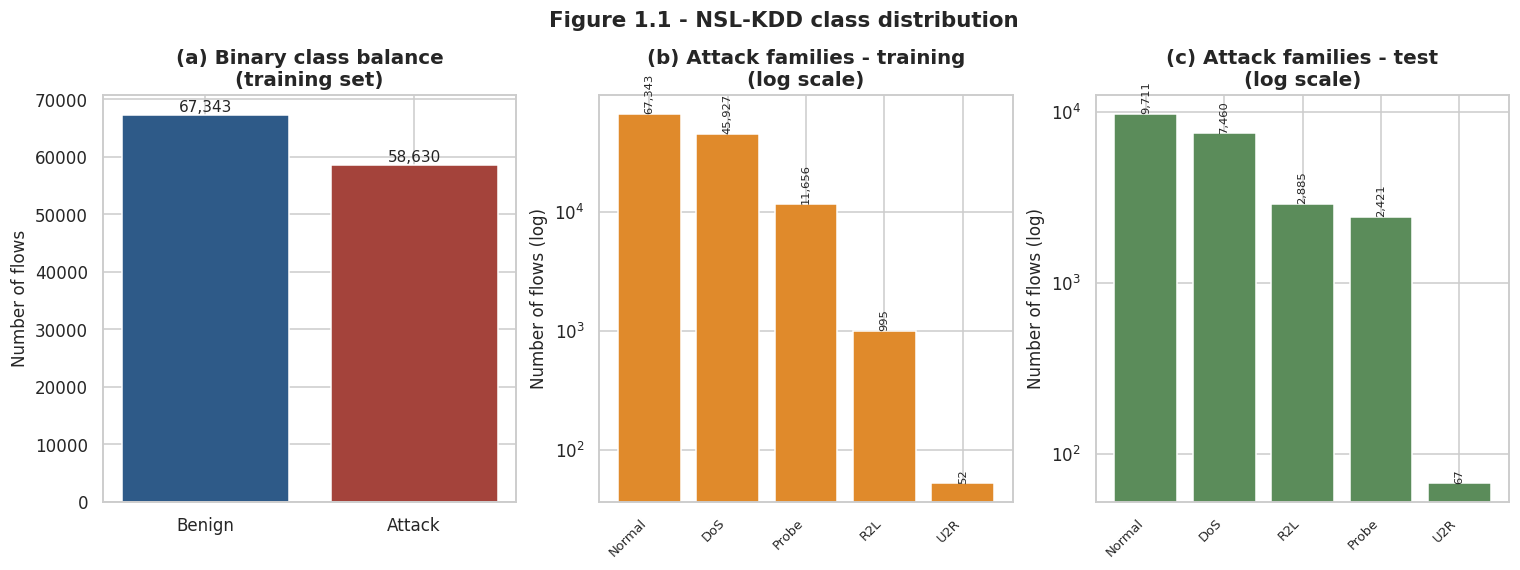

[SAVED] fig_01_class_distribution.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_01_class_distribution.png'

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# (a) binary balance
bin_counts = df_train_raw['y'].value_counts().sort_index()
axes[0].bar(["Benign", "Attack"], bin_counts.values, color=[PALETTE["central"], PALETTE["accent"]])
axes[0].set_title("(a) Binary class balance\n(training set)")
axes[0].set_ylabel("Number of flows")
for i, v in enumerate(bin_counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=10)

# (b, c) attack families, training and test
for ax, d, name, colour in [(axes[1], df_train_raw, "training", PALETTE["federated"]),
                            (axes[2], df_test_raw, "test", PALETTE["dp"])]:
    counts = d['category'].value_counts()
    ax.bar(range(len(counts)), counts.values, color=colour)
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels(counts.index, rotation=45, ha="right", fontsize=8.5)
    ax.set_yscale("log")
    ax.set_title(f"({'b' if name=='training' else 'c'}) Attack families - {name}\n(log scale)")
    ax.set_ylabel("Number of flows (log)")
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=7.5, rotation=90)

fig.suptitle(f"Figure 1.1 - {ACTIVE['display_name']} class distribution",
             y=1.04, fontsize=14, fontweight="bold")
save_fig(fig, "fig_01_class_distribution",
         f"{ACTIVE['display_name']} class balance and attack-family distribution "
         f"for the training and test partitions", "1")

### 1.15 Record the dataset characteristics as a table

In [28]:
ds_rows = []
families = sorted(set(df_train_raw['category']) | set(df_test_raw['category']))
for name, d in [("train", df_train_raw), ("test", df_test_raw)]:
    row = {"dataset": ACTIVE["display_name"], "partition": name, "records": len(d),
           "features": d.shape[1] - 3,          # excludes label, category, y
           "attack_rate_pct": round(d['y'].mean()*100, 2),
           "duplicate_rows": int(d.duplicated().sum()),
           "distinct_native_labels": d['label'].nunique()}
    for c in families:
        row[c] = int((d['category'] == c).sum())
    ds_rows.append(row)

dataset_df = pd.DataFrame(ds_rows)
display(dataset_df)
save_table(dataset_df, "table_02_dataset_characteristics",
           f"Characteristics of the {ACTIVE['display_name']} training and test partitions", "1")
RESULTS["dataset"] = dataset_df.to_dict("records")

,dataset,partition,records,features,attack_rate_pct,duplicate_rows,distinct_native_labels,DoS,Normal,Probe,R2L,U2R
0,NSL-KDD,train,125973,41,46.54,0,23,45927,67343,11656,995,52
1,NSL-KDD,test,22544,41,56.92,0,38,7460,9711,2421,2885,67


[TABLE SAVED ] table_02_dataset_characteristics.csv / .tex  (2 rows x 12 cols)


---
## Section 2 — Data cleaning and preprocessing

Each cleaning operation is performed in its own cell and immediately followed by a verification cell, so the
effect of every transformation on the data is visible and auditable.

### 2.1 Work on copies so the raw data stays untouched

In [29]:
df_train = df_train_raw.copy()
df_test  = df_test_raw.copy()
print("Working copies created.")
print("  train:", df_train.shape, " test:", df_test.shape)

Working copies created.
  train: (125973, 44)  test: (22544, 44)


### 2.2 Confirm no label-derived columns remain in the feature space

In [30]:
# Section 1.4 already removed dataset-specific metadata that would leak the answer
# (NSL-KDD's 'difficulty' annotation, UNSW-NB15's row 'id'). This cell proves it,
# because a single leaked column silently invalidates every result that follows.
LABEL_COLS = ['label', 'category', 'y']
leak_candidates = ['difficulty', 'id', 'attack_cat', 'Label', 'class']

found = [c for c in leak_candidates if c in df_train.columns and c not in LABEL_COLS]
print("Potential leakage columns still present:", found if found else "none")

feature_space = [c for c in df_train.columns if c not in LABEL_COLS]
print(f"Columns carried forward as candidate features: {len(feature_space)}")
print(f"Columns reserved as targets/metadata        : {LABEL_COLS}")
assert not found, f"Leakage columns must be removed before modelling: {found}"
print("\nFeature space is clean.")

Potential leakage columns still present: none
Columns carried forward as candidate features: 41
Columns reserved as targets/metadata        : ['label', 'category', 'y']

Feature space is clean.


### 2.3 Verify the train and test partitions are structurally identical

In [31]:
same_cols = list(df_train.columns) == list(df_test.columns)
print("Identical column order in train and test:", same_cols)
if not same_cols:
    print("  train-only:", sorted(set(df_train.columns) - set(df_test.columns)))
    print("  test-only :", sorted(set(df_test.columns) - set(df_train.columns)))
    df_test = df_test[df_train.columns]
    print("  -> test partition reordered to match train")
print("\nColumns:", len(df_train.columns))

Identical column order in train and test: True

Columns: 44


### 2.4 Remove duplicate rows from the training set

In [32]:
# Duplicates inflate apparent accuracy and, more importantly for this project, they
# make membership-inference attacks look artificially strong. They are removed from
# the training partition only - the published test partition is left intact so results
# remain comparable with the literature.
rows_before = len(df_train)
df_train = df_train.drop_duplicates().reset_index(drop=True)
rows_after = len(df_train)
print(f"Rows before : {rows_before:,}")
print(f"Rows after  : {rows_after:,}")
print(f"Removed     : {rows_before - rows_after:,}  ({(rows_before-rows_after)/rows_before*100:.2f}%)")

Rows before : 125,973
Rows after  : 125,973
Removed     : 0  (0.00%)


### 2.5 Verify no duplicates remain

In [33]:
remaining = int(df_train.duplicated().sum())
print("Duplicate rows remaining in training set:", remaining)
print("Verification passed." if remaining == 0 else "Verification FAILED.")

Duplicate rows remaining in training set: 0
Verification passed.


### 2.6 Replace infinite values and check for NaN

In [34]:
# Flow-based datasets frequently contain inf values produced by rate calculations
# dividing by zero. NSL-KDD is usually clean, but this guard means the same pipeline
# works unchanged on CICIDS2017, which is not.
num_cols_all = df_train.select_dtypes(include=[np.number]).columns.tolist()

inf_before = int(np.isinf(df_train[num_cols_all].to_numpy()).sum())
df_train[num_cols_all] = df_train[num_cols_all].replace([np.inf, -np.inf], np.nan)
df_test[num_cols_all]  = df_test[num_cols_all].replace([np.inf, -np.inf], np.nan)

nan_train = int(df_train[num_cols_all].isnull().sum().sum())
nan_test  = int(df_test[num_cols_all].isnull().sum().sum())
print(f"Infinite values found and converted: {inf_before}")
print(f"NaN values now present - train: {nan_train}, test: {nan_test}")

Infinite values found and converted: 0
NaN values now present - train: 0, test: 0


### 2.7 Fill any NaN with the column median and verify

In [35]:
if nan_train or nan_test:
    medians = df_train[num_cols_all].median()
    df_train[num_cols_all] = df_train[num_cols_all].fillna(medians)
    df_test[num_cols_all]  = df_test[num_cols_all].fillna(medians)   # train medians only - no leakage
    print("Median imputation applied using training-set medians.")
else:
    print("No imputation needed.")

print("NaN remaining - train:", int(df_train[num_cols_all].isnull().sum().sum()),
      "| test:", int(df_test[num_cols_all].isnull().sum().sum()))

No imputation needed.
NaN remaining - train: 0 | test: 0


### 2.8 Identify and drop constant (zero-variance) features

In [36]:
# A feature with a single value across the whole training set carries no information
# and only adds parameters (and therefore privacy cost under DP-SGD).
numeric_features = [c for c in df_train.columns if c not in CATEGORICAL_COLS + ['label', 'category', 'y']]
constant_features = [c for c in numeric_features if df_train[c].nunique() <= 1]

print("Numeric features examined:", len(numeric_features))
print("Constant features found  :", len(constant_features), constant_features)

numeric_features = [c for c in numeric_features if c not in constant_features]
print("Numeric features retained:", len(numeric_features))

Numeric features examined: 38
Constant features found  : 1 ['num_outbound_cmds']
Numeric features retained: 37


### 2.9 Verify the retained features all vary

In [37]:
variance_check = df_train[numeric_features].nunique().sort_values()
print("Five features with the fewest distinct values:")
display(variance_check.head(5).to_frame("distinct_values"))
print("Minimum distinct values across retained features:", int(variance_check.min()))
print("Verification passed." if variance_check.min() > 1 else "Verification FAILED.")

Five features with the fewest distinct values:


,distinct_values
land,2
logged_in,2
root_shell,2
is_host_login,2
is_guest_login,2


Minimum distinct values across retained features: 2
Verification passed.


### 2.10 Apply the stratified sample defined in `CONFIG`

The sampling is stratified by attack category and enforces a floor of
`CONFIG["min_rows_per_class"]` records per class, which protects the very rare U2R family from disappearing
entirely. Set `sample_fraction` to `1.0` in Section 0.7 to use every record.

In [38]:
n_train_before, n_test_before = len(df_train), len(df_test)

if SAMPLING_APPLIED_AT_LOAD:
    # Large datasets are subsampled while loading to stay within memory; applying the
    # fraction a second time here would silently shrink the data by frac squared.
    effective_fraction = 1.0
    print(f"Sampling was already applied during loading at fraction "
          f"{CONFIG['sample_fraction']}; skipping to avoid double-sampling.")
else:
    effective_fraction = CONFIG["sample_fraction"]

df_train = stratified_subsample(df_train, 'category', effective_fraction,
                                CONFIG["seed"], CONFIG["min_rows_per_class"])
df_test  = stratified_subsample(df_test,  'category', effective_fraction,
                                CONFIG["seed"], CONFIG["min_rows_per_class"])

print(f"Sample fraction in use: {CONFIG['sample_fraction']}")
print(f"Training records: {n_train_before:,} -> {len(df_train):,}")
print(f"Test records    : {n_test_before:,} -> {len(df_test):,}")

Sample fraction in use: 1.0
Training records: 125,973 -> 125,973
Test records    : 22,544 -> 22,544


### 2.11 Verify the class proportions survived the sampling

In [39]:
prop = pd.DataFrame({
    "sampled_train_count": df_train['category'].value_counts(),
    "sampled_train_pct": (df_train['category'].value_counts(normalize=True) * 100).round(2),
    "original_train_pct": (df_train_raw['category'].value_counts(normalize=True) * 100).round(2),
}).fillna(0)
display(prop)
print("Attack rate after sampling: %.2f%% (was %.2f%%)"
      % (df_train['y'].mean()*100, df_train_raw['y'].mean()*100))

,sampled_train_count,sampled_train_pct,original_train_pct
category,,,
Normal,67343,53.46,53.46
DoS,45927,36.46,36.46
Probe,11656,9.25,9.25
R2L,995,0.79,0.79
U2R,52,0.04,0.04


Attack rate after sampling: 46.54% (was 46.54%)


### 2.12 Split the training file into a training set and an internal held-out set

Two evaluation sets are used, and the distinction matters for the validity of the results:

* **Internal test set** — a stratified 20% holdout from `KDDTrain+`. It follows the same distribution as the
  training data, so it isolates model quality and is the correct basis for the membership-inference audit in
  Section 7 (members and non-members must be drawn from the same distribution, otherwise the attack simply
  detects the distribution shift instead of detecting membership).
* **Official `KDDTest+` set** — contains attack signatures absent from training. It measures generalisation to
  previously unseen attacks, which is the harder and more operationally realistic condition.

In [40]:
train_idx, holdout_idx = train_test_split(
    np.arange(len(df_train)), test_size=CONFIG["test_size_internal"],
    random_state=CONFIG["seed"], stratify=df_train['category'])

df_fit     = df_train.iloc[train_idx].reset_index(drop=True)
df_holdout = df_train.iloc[holdout_idx].reset_index(drop=True)

print(f"Model-fitting set : {len(df_fit):,} records")
print(f"Internal test set : {len(df_holdout):,} records")
print(f"Official test set : {len(df_test):,} records")

Model-fitting set : 100,778 records
Internal test set : 25,195 records
Official test set : 22,544 records


### 2.13 Verify the split is stratified and non-overlapping

In [41]:
comp = pd.DataFrame({
    "fit_pct": (df_fit['category'].value_counts(normalize=True)*100).round(2),
    "holdout_pct": (df_holdout['category'].value_counts(normalize=True)*100).round(2),
}).fillna(0)
display(comp)
print("Overlapping indices between the two splits:", len(set(train_idx) & set(holdout_idx)))
print("Verification passed." if len(set(train_idx) & set(holdout_idx)) == 0 else "Verification FAILED.")

,fit_pct,holdout_pct
category,,
Normal,53.46,53.46
DoS,36.46,36.46
Probe,9.25,9.25
R2L,0.79,0.79
U2R,0.04,0.04


Overlapping indices between the two splits: 0
Verification passed.


### 2.14 One-hot encode the categorical features

In [42]:
# protocol_type, service and flag are symbolic. They are one-hot encoded across all three
# partitions together so the resulting column set is identical everywhere - a mismatch here
# is one of the most common silent bugs in IDS pipelines.
if CATEGORICAL_COLS:
    combined = pd.concat([df_fit[CATEGORICAL_COLS], df_holdout[CATEGORICAL_COLS],
                          df_test[CATEGORICAL_COLS]], keys=['fit', 'holdout', 'test'])
    encoded = pd.get_dummies(combined, columns=CATEGORICAL_COLS).astype(np.float32)
    enc_fit     = encoded.loc['fit'].reset_index(drop=True)
    enc_holdout = encoded.loc['holdout'].reset_index(drop=True)
    enc_test    = encoded.loc['test'].reset_index(drop=True)

    print("Categorical columns encoded:", CATEGORICAL_COLS)
    print("One-hot columns produced   :", encoded.shape[1])
    for c in CATEGORICAL_COLS:
        print(f"  {c}: {df_fit[c].nunique()} distinct values in the fitting set")
else:
    # CICIDS2017 flow features are entirely numeric, so there is nothing to encode.
    # Empty frames with matching row counts keep the assembly step below unchanged.
    enc_fit     = pd.DataFrame(index=range(len(df_fit)))
    enc_holdout = pd.DataFrame(index=range(len(df_holdout)))
    enc_test    = pd.DataFrame(index=range(len(df_test)))
    print(f"{ACTIVE['display_name']} has no categorical features - one-hot encoding skipped.")
    print("All predictive information is carried by the numeric flow statistics.")

Categorical columns encoded: ['protocol_type', 'service', 'flag']
One-hot columns produced   : 84
  protocol_type: 3 distinct values in the fitting set
  service: 70 distinct values in the fitting set
  flag: 11 distinct values in the fitting set


### 2.15 Verify the encoded partitions align

In [43]:
print("Column counts  -> fit:", enc_fit.shape[1], "| holdout:", enc_holdout.shape[1], "| test:", enc_test.shape[1])
print("Column names identical across partitions:",
      list(enc_fit.columns) == list(enc_holdout.columns) == list(enc_test.columns))
print("Any NaN introduced:", bool(enc_fit.isnull().any().any() or enc_test.isnull().any().any()))

Column counts  -> fit: 84 | holdout: 84 | test: 84
Column names identical across partitions: True
Any NaN introduced: False


### 2.16 Standardise the numeric features

In [44]:
# The scaler is fitted on the model-fitting partition only. Fitting it on the full dataset
# would leak test-set statistics into training and inflate the reported results.
scaler = StandardScaler().fit(df_fit[numeric_features])

num_fit     = pd.DataFrame(scaler.transform(df_fit[numeric_features]),     columns=numeric_features)
num_holdout = pd.DataFrame(scaler.transform(df_holdout[numeric_features]), columns=numeric_features)
num_test    = pd.DataFrame(scaler.transform(df_test[numeric_features]),    columns=numeric_features)

print("Scaler fitted on", len(df_fit), "records across", len(numeric_features), "numeric features.")

Scaler fitted on 100778 records across 37 numeric features.


### 2.17 Verify the scaling worked

In [45]:
check = pd.DataFrame({
    "fit_mean": num_fit.mean().round(4), "fit_std": num_fit.std().round(4),
    "test_mean": num_test.mean().round(4), "test_std": num_test.std().round(4),
}).head(8)
display(check)
print("Fitting-set means are ~0 and standard deviations ~1, as expected.")
print("Test-set values deviate slightly - correct, since the scaler never saw the test data.")

,fit_mean,fit_std,test_mean,test_std
duration,0.0,1.0,-0.0266,0.5412
src_bytes,0.0,1.0,-0.0068,0.0720
dst_bytes,-0.0,1.0,-0.0049,0.0047
land,-0.0,1.0,0.0089,1.2833
wrong_fragment,0.0,1.0,-0.0565,0.5616
urgent,-0.0,1.0,0.0383,2.3635
hot,-0.0,1.0,-0.0445,0.4380
num_failed_logins,-0.0,1.0,0.4589,3.3757


Fitting-set means are ~0 and standard deviations ~1, as expected.
Test-set values deviate slightly - correct, since the scaler never saw the test data.


### 2.18 Assemble the final feature matrices

In [46]:
X_fit     = pd.concat([num_fit, enc_fit], axis=1)
X_holdout = pd.concat([num_holdout, enc_holdout], axis=1)
X_test    = pd.concat([num_test, enc_test], axis=1)

FEATURE_NAMES = list(X_fit.columns)

X_fit     = X_fit.to_numpy(dtype=np.float32)
X_holdout = X_holdout.to_numpy(dtype=np.float32)
X_test    = X_test.to_numpy(dtype=np.float32)

y_fit,     y_holdout,     y_test     = (df_fit['y'].to_numpy(), df_holdout['y'].to_numpy(), df_test['y'].to_numpy())
cat_fit,   cat_holdout,   cat_test   = (df_fit['category'].to_numpy(), df_holdout['category'].to_numpy(),
                                        df_test['category'].to_numpy())

N_FEATURES = X_fit.shape[1]
print(f"X_fit    : {X_fit.shape}")
print(f"X_holdout: {X_holdout.shape}")
print(f"X_test   : {X_test.shape}")
print(f"Total input features: {N_FEATURES}")

X_fit    : (100778, 121)
X_holdout: (25195, 121)
X_test   : (22544, 121)
Total input features: 121


### 2.19 Final verification of the prepared arrays

In [47]:
checks = {
    "no NaN in X_fit": not np.isnan(X_fit).any(),
    "no inf in X_fit": not np.isinf(X_fit).any(),
    "feature counts match": X_fit.shape[1] == X_holdout.shape[1] == X_test.shape[1],
    "labels are binary": set(np.unique(y_fit)).issubset({0, 1}),
    "row counts align (fit)": len(X_fit) == len(y_fit) == len(cat_fit),
    "row counts align (test)": len(X_test) == len(y_test) == len(cat_test),
    "both classes present": len(np.unique(y_fit)) == 2,
}
for k, v in checks.items():
    print(f"{'PASS' if v else 'FAIL'}  {k}")
assert all(checks.values()), "Preprocessing verification failed - inspect the cells above."
print("\nAll preprocessing checks passed.")

PASS  no NaN in X_fit
PASS  no inf in X_fit
PASS  feature counts match
PASS  labels are binary
PASS  row counts align (fit)
PASS  row counts align (test)
PASS  both classes present

All preprocessing checks passed.


### 2.20 Save the processed data to Drive

In [48]:
np.savez_compressed(
    os.path.join(PATHS["data_proc"], "processed_data.npz"),
    X_fit=X_fit, y_fit=y_fit, cat_fit=cat_fit,
    X_holdout=X_holdout, y_holdout=y_holdout, cat_holdout=cat_holdout,
    X_test=X_test, y_test=y_test, cat_test=cat_test,
    feature_names=np.array(FEATURE_NAMES))

with open(os.path.join(PATHS["data_proc"], "feature_names.json"), "w") as f:
    json.dump(FEATURE_NAMES, f, indent=2)

size_mb = os.path.getsize(os.path.join(PATHS['data_proc'], 'processed_data.npz')) / 1e6
log_line(f"Processed arrays saved to Drive ({size_mb:.2f} MB)")
print("Saved to:", PATHS["data_proc"])

[13:58:52] Processed arrays saved to Drive (2.81 MB)
Saved to: /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/data_processed


### 2.21 Figure — feature correlation structure

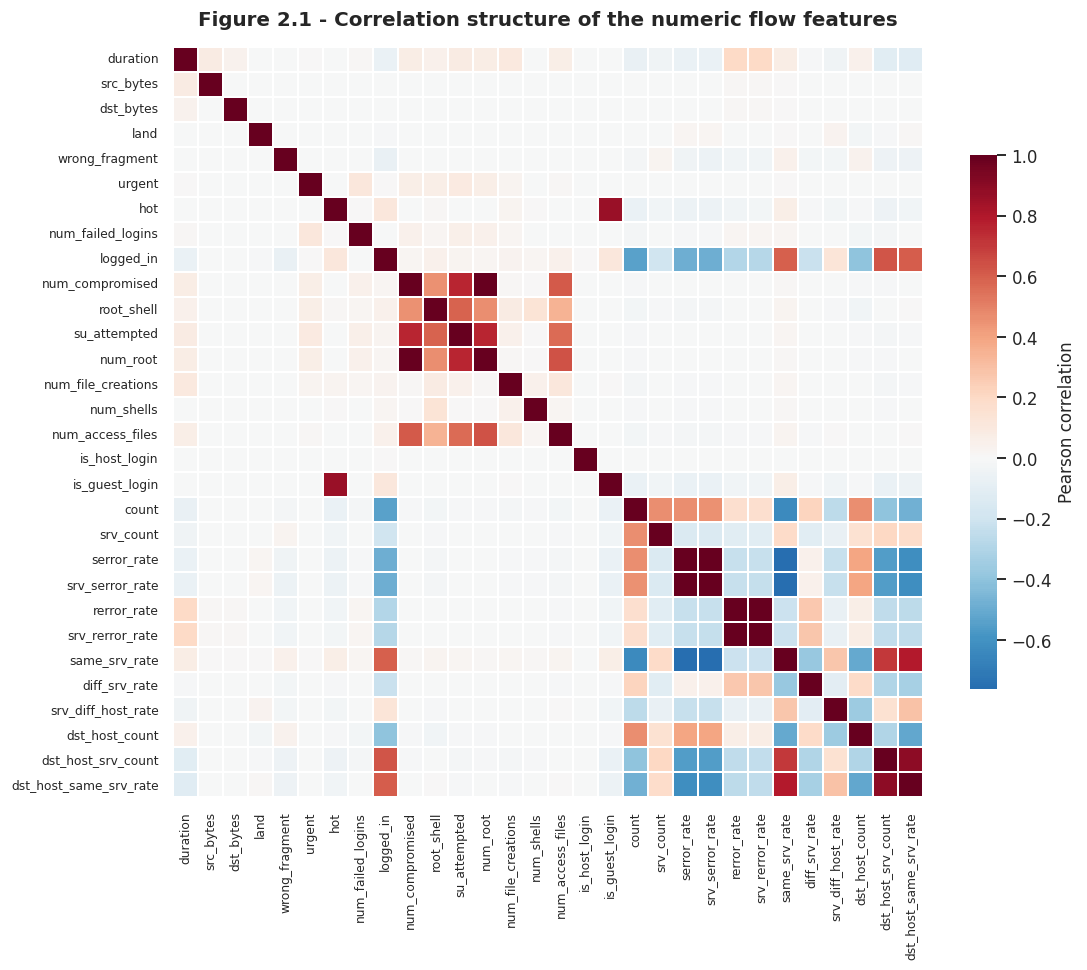

[SAVED] fig_02_feature_correlation.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_02_feature_correlation.png'

In [49]:
corr_features = numeric_features[:30]
corr = pd.DataFrame(X_fit[:, :len(corr_features)], columns=corr_features).corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, square=True, linewidths=0.3,
            cbar_kws={"shrink": 0.7, "label": "Pearson correlation"}, ax=ax)
ax.set_title("Figure 2.1 - Correlation structure of the numeric flow features", pad=14)
plt.xticks(rotation=90, fontsize=8); plt.yticks(fontsize=8)
save_fig(fig, "fig_02_feature_correlation",
         "Pearson correlation matrix of the standardised numeric flow features", "2")

### 2.22 Figure — class separability in two dimensions (PCA)

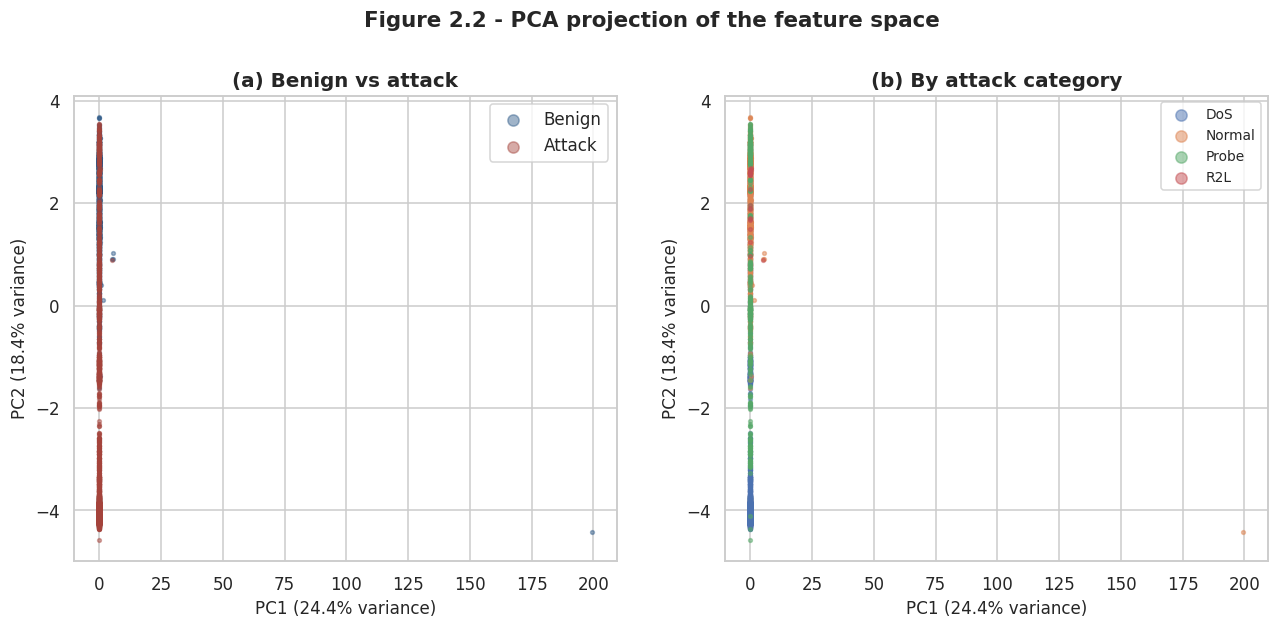

[SAVED] fig_03_pca_projection.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_03_pca_projection.png'

In [50]:
from sklearn.decomposition import PCA

sample_n = min(4000, len(X_fit))
sample_ix = np.random.default_rng(CONFIG["seed"]).choice(len(X_fit), sample_n, replace=False)
pca = PCA(n_components=2, random_state=CONFIG["seed"])
proj = pca.fit_transform(X_fit[sample_ix])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(proj[y_fit[sample_ix] == 0, 0], proj[y_fit[sample_ix] == 0, 1],
                s=6, alpha=0.45, label="Benign", color=PALETTE["central"])
axes[0].scatter(proj[y_fit[sample_ix] == 1, 0], proj[y_fit[sample_ix] == 1, 1],
                s=6, alpha=0.45, label="Attack", color=PALETTE["accent"])
axes[0].set_title("(a) Benign vs attack"); axes[0].legend(markerscale=3)

for c in sorted(set(cat_fit[sample_ix])):
    m = cat_fit[sample_ix] == c
    axes[1].scatter(proj[m, 0], proj[m, 1], s=6, alpha=0.5, label=c)
axes[1].set_title("(b) By attack category"); axes[1].legend(markerscale=3, fontsize=9)

for a in axes:
    a.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
    a.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
fig.suptitle("Figure 2.2 - PCA projection of the feature space", y=1.02, fontsize=14, fontweight="bold")
save_fig(fig, "fig_03_pca_projection",
         "Two-component PCA projection showing separability of benign and attack traffic", "2")

---
## Section 3 — Framework design artefacts (Objective 1)

Design Science Research produces *artefacts*, and the artefacts must be documented before they are evaluated.
This section generates the design diagrams referenced in the proposal — the DSR process, the integrated
framework architecture, the federated threat model, and the experiment matrix — as publication-quality figures
saved to Drive for direct inclusion in the dissertation.

### 3.1 Figure — Design Science Research process

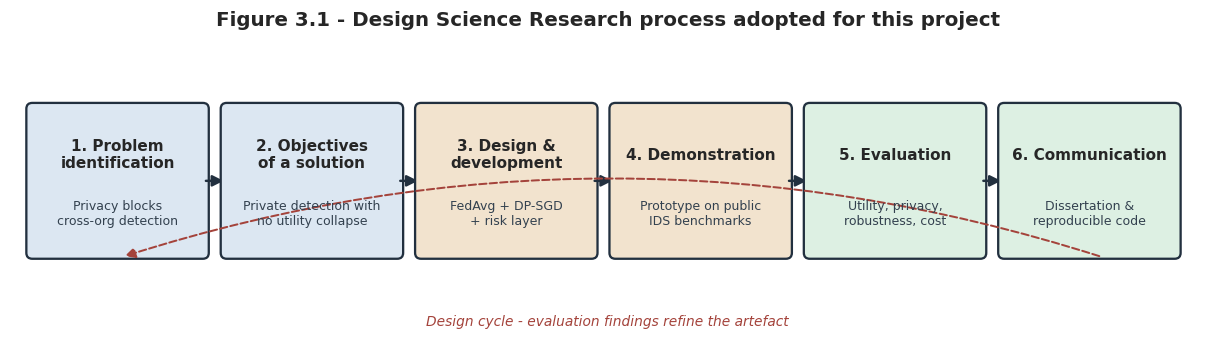

[SAVED] fig_04_dsr_process.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_04_dsr_process.png'

In [51]:
fig, ax = plt.subplots(figsize=(14, 3.6))
ax.set_xlim(0, 14); ax.set_ylim(0, 3.6); ax.axis("off")

stages = [
    ("1. Problem\nidentification", "Privacy blocks\ncross-org detection", "#DCE7F2"),
    ("2. Objectives\nof a solution", "Private detection with\nno utility collapse", "#DCE7F2"),
    ("3. Design &\ndevelopment", "FedAvg + DP-SGD\n+ risk layer", "#F2E3CE"),
    ("4. Demonstration", "Prototype on public\nIDS benchmarks", "#F2E3CE"),
    ("5. Evaluation", "Utility, privacy,\nrobustness, cost", "#DDF0E3"),
    ("6. Communication", "Dissertation &\nreproducible code", "#DDF0E3"),
]
w, h, gap = 2.0, 1.7, 0.28
for i, (title, sub, colour) in enumerate(stages):
    x = 0.25 + i * (w + gap)
    ax.add_patch(FancyBboxPatch((x, 1.1), w, h, boxstyle="round,pad=0.07",
                                fc=colour, ec="#22303F", lw=1.5))
    ax.text(x + w/2, 1.1 + h*0.68, title, ha="center", va="center", fontsize=10, fontweight="bold")
    ax.text(x + w/2, 1.1 + h*0.27, sub, ha="center", va="center", fontsize=8.2, color="#33414F")
    if i < len(stages) - 1:
        ax.add_patch(FancyArrowPatch((x + w, 1.1 + h/2), (x + w + gap, 1.1 + h/2),
                                     arrowstyle="-|>", mutation_scale=15, lw=1.6, color="#22303F"))

ax.add_patch(FancyArrowPatch((12.8, 1.05), (1.3, 1.05), arrowstyle="-|>", mutation_scale=14,
                             lw=1.3, color=PALETTE["accent"], linestyle="--",
                             connectionstyle="arc3,rad=0.16"))
ax.text(7.0, 0.24, "Design cycle - evaluation findings refine the artefact",
        ha="center", fontsize=9, style="italic", color=PALETTE["accent"])
ax.set_title("Figure 3.1 - Design Science Research process adopted for this project",
             fontsize=13, fontweight="bold", pad=10)
save_fig(fig, "fig_04_dsr_process",
         "Design Science Research process applied to the privacy-preserving detection framework", "3")

### 3.2 Figure — integrated framework architecture

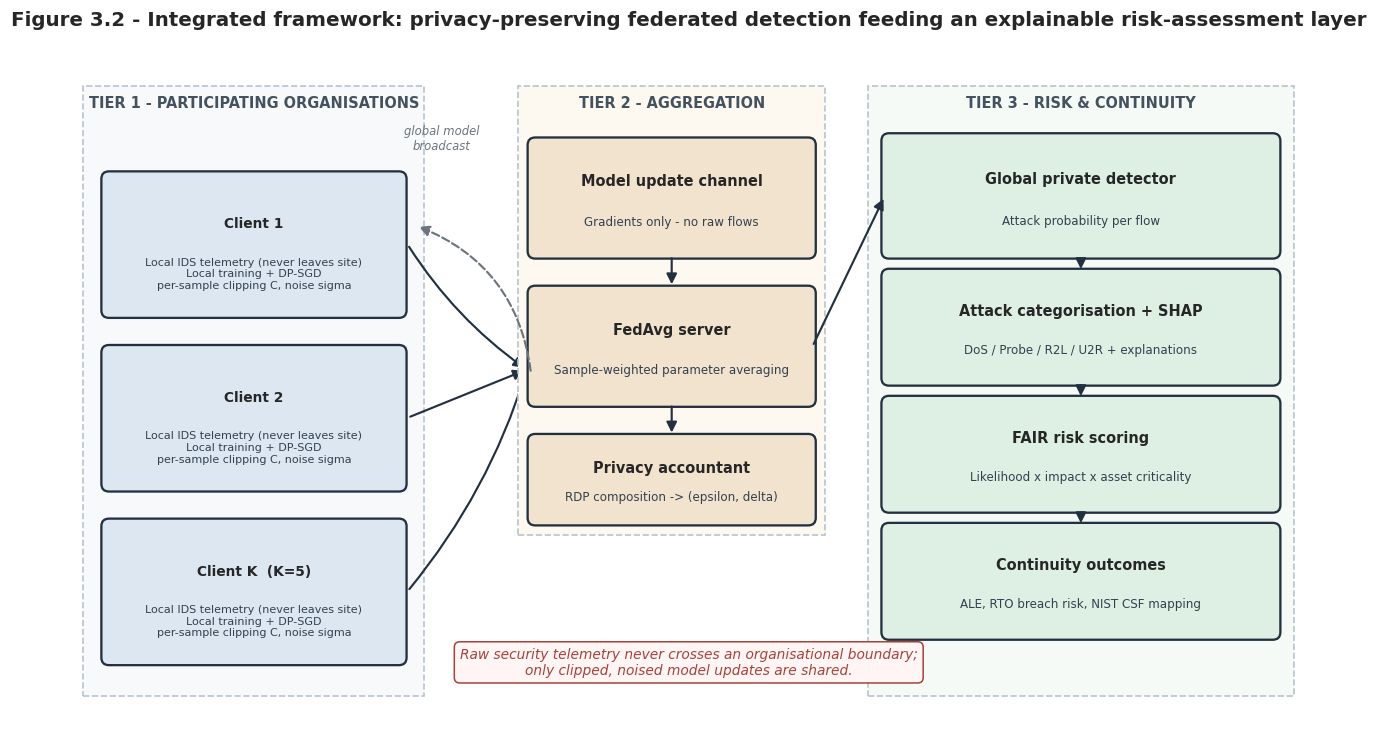

[SAVED] fig_05_framework_architecture.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_05_framework_architecture.png'

In [52]:
fig, ax = plt.subplots(figsize=(14.5, 8.2))
ax.set_xlim(0, 14.5); ax.set_ylim(0, 8.2); ax.axis("off")

def box(x, y, w, h, title, sub, fc, fs=9.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.09", fc=fc, ec="#22303F", lw=1.5))
    ax.text(x+w/2, y+h*0.66, title, ha="center", va="center", fontsize=fs, fontweight="bold")
    if sub:
        ax.text(x+w/2, y+h*0.28, sub, ha="center", va="center", fontsize=fs-1.7, color="#33414F")

def arrow(p1, p2, colour="#22303F", style="-|>", ls="-", rad=0.0, lw=1.4):
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle=style, mutation_scale=14, lw=lw,
                                 color=colour, linestyle=ls,
                                 connectionstyle=f"arc3,rad={rad}"))

ax.add_patch(Rectangle((0.15, 0.5), 4.0, 7.2, fc="#F7F9FB", ec="#B8C4CF", lw=1.1, ls="--"))
ax.text(2.15, 7.45, "TIER 1 - PARTICIPATING ORGANISATIONS", ha="center", fontsize=9.5,
        fontweight="bold", color="#44525F")

for i in range(3):
    y = 5.05 - i*2.05
    label = f"Client {i+1}" if i < 2 else f"Client K  (K={CONFIG['n_clients']})"
    box(0.45, y, 3.4, 1.55, label,
        "Local IDS telemetry (never leaves site)\nLocal training + DP-SGD\nper-sample clipping C, noise sigma",
        "#DCE7F2", fs=9)
    arrow((3.95, y+0.78), (5.35, 4.35), rad=0.10 if i != 1 else 0.0)

ax.add_patch(Rectangle((5.25, 2.4), 3.6, 5.3, fc="#FDF8F0", ec="#B8C4CF", lw=1.1, ls="--"))
ax.text(7.05, 7.45, "TIER 2 - AGGREGATION", ha="center", fontsize=9.5, fontweight="bold", color="#44525F")
box(5.45, 5.75, 3.2, 1.25, "Model update channel", "Gradients only - no raw flows", "#F2E3CE")
box(5.45, 4.00, 3.2, 1.25, "FedAvg server", "Sample-weighted parameter averaging", "#F2E3CE")
box(5.45, 2.60, 3.2, 0.90, "Privacy accountant", "RDP composition -> (epsilon, delta)", "#F2E3CE")
arrow((7.05, 5.70), (7.05, 5.32))
arrow((7.05, 3.95), (7.05, 3.57))
arrow((5.40, 4.30), (4.05, 6.05), ls="--", colour=PALETTE["grey"], rad=0.30)
ax.text(4.35, 6.95, "global model\nbroadcast", ha="center", fontsize=7.6,
        color=PALETTE["grey"], style="italic")

ax.add_patch(Rectangle((9.35, 0.5), 5.0, 7.2, fc="#F5FAF6", ec="#B8C4CF", lw=1.1, ls="--"))
ax.text(11.85, 7.45, "TIER 3 - RISK & CONTINUITY", ha="center", fontsize=9.5,
        fontweight="bold", color="#44525F")
box(9.6, 5.75, 4.5, 1.3, "Global private detector", "Attack probability per flow", "#DDF0E3")
box(9.6, 4.25, 4.5, 1.2, "Attack categorisation + SHAP", "DoS / Probe / R2L / U2R + explanations", "#DDF0E3")
box(9.6, 2.75, 4.5, 1.2, "FAIR risk scoring", "Likelihood x impact x asset criticality", "#DDF0E3")
box(9.6, 1.25, 4.5, 1.2, "Continuity outcomes", "ALE, RTO breach risk, NIST CSF mapping", "#DDF0E3")
arrow((8.70, 4.62), (9.55, 6.40))
for y1, y2 in [(5.7, 5.5), (4.2, 4.0), (2.7, 2.5)]:
    arrow((11.85, y1), (11.85, y2))

ax.text(7.25, 0.75, "Raw security telemetry never crosses an organisational boundary;\n"
                    "only clipped, noised model updates are shared.",
        ha="center", fontsize=9, style="italic", color=PALETTE["accent"],
        bbox=dict(boxstyle="round,pad=0.4", fc="#FFF5F4", ec=PALETTE["accent"], lw=1.0))
ax.set_title("Figure 3.2 - Integrated framework: privacy-preserving federated detection feeding an "
             "explainable risk-assessment layer", fontsize=13, fontweight="bold", pad=12)
save_fig(fig, "fig_05_framework_architecture",
         "Proposed three-tier integrated framework architecture", "3")

### 3.3 Figure — threat model and privacy boundary

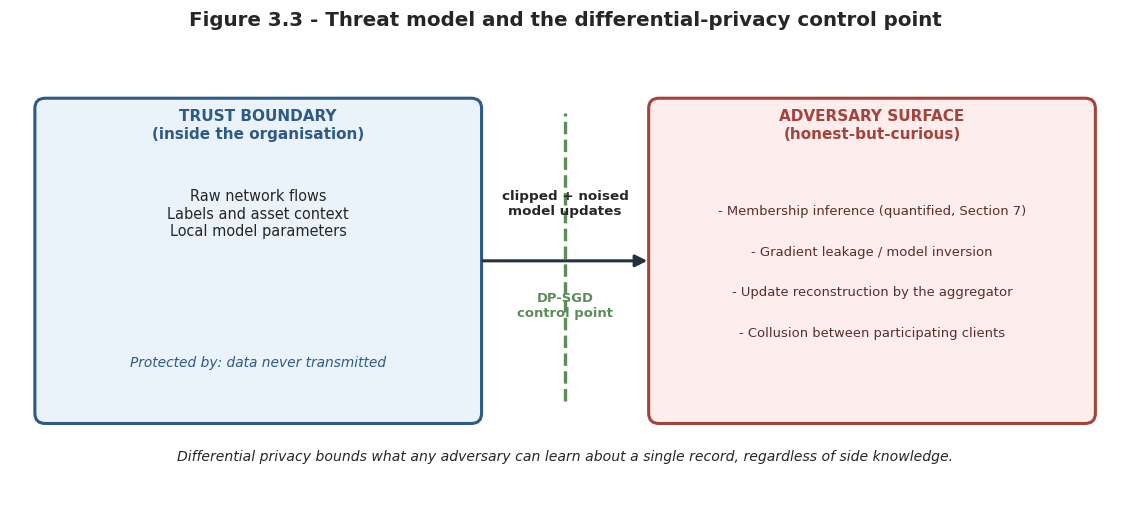

[SAVED] fig_06_threat_model.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_06_threat_model.png'

In [53]:
fig, ax = plt.subplots(figsize=(13, 5.4))
ax.set_xlim(0, 13); ax.set_ylim(0, 5.4); ax.axis("off")

ax.add_patch(FancyBboxPatch((0.4, 1.0), 5.0, 3.6, boxstyle="round,pad=0.12",
                            fc="#EAF2FA", ec=PALETTE["central"], lw=2.0))
ax.text(2.9, 4.25, "TRUST BOUNDARY\n(inside the organisation)", ha="center", fontsize=10,
        fontweight="bold", color=PALETTE["central"])
ax.text(2.9, 3.1, "Raw network flows\nLabels and asset context\nLocal model parameters",
        ha="center", fontsize=9.5)
ax.text(2.9, 1.55, "Protected by: data never transmitted", ha="center", fontsize=9,
        style="italic", color=PALETTE["central"])

ax.add_patch(FancyBboxPatch((7.6, 1.0), 5.0, 3.6, boxstyle="round,pad=0.12",
                            fc="#FDEDEC", ec=PALETTE["accent"], lw=2.0))
ax.text(10.1, 4.25, "ADVERSARY SURFACE\n(honest-but-curious)", ha="center", fontsize=10,
        fontweight="bold", color=PALETTE["accent"])
threats = ["Membership inference (quantified, Section 7)",
           "Gradient leakage / model inversion",
           "Update reconstruction by the aggregator",
           "Collusion between participating clients"]
for i, t in enumerate(threats):
    ax.text(10.1, 3.35 - i*0.48, "- " + t, ha="center", fontsize=8.6, color="#5A2E2A")

ax.add_patch(FancyArrowPatch((5.5, 2.8), (7.5, 2.8), arrowstyle="-|>", mutation_scale=16,
                             lw=2.0, color="#22303F"))
ax.text(6.5, 3.35, "clipped + noised\nmodel updates", ha="center", fontsize=8.8, fontweight="bold")
ax.text(6.5, 2.15, "DP-SGD\ncontrol point", ha="center", fontsize=8.6,
        color=PALETTE["dp"], fontweight="bold")
ax.plot([6.5, 6.5], [1.15, 4.55], color=PALETTE["dp"], lw=2.2, ls="--")

ax.text(6.5, 0.45, "Differential privacy bounds what any adversary can learn about a single record, "
                   "regardless of side knowledge.",
        ha="center", fontsize=9.2, style="italic")
ax.set_title("Figure 3.3 - Threat model and the differential-privacy control point",
             fontsize=13, fontweight="bold", pad=10)
save_fig(fig, "fig_06_threat_model",
         "Threat model showing the trust boundary and where differential privacy is enforced", "3")

### 3.4 Experiment matrix

In [54]:
exp_rows = [
    {"id": "E1", "experiment": "Centralised baseline", "privacy": "None",
     "purpose": "Reference detection ceiling", "answers": "RQ1"},
    {"id": "E2", "experiment": f"Federated ({CONFIG['n_clients']} clients, non-IID)", "privacy": "Data locality only",
     "purpose": "Cost of decentralisation alone", "answers": "RQ1"},
    {"id": "E3", "experiment": "Federated + DP-SGD sweep", "privacy": f"eps in {CONFIG['epsilons']}",
     "purpose": "Privacy-utility trade-off curve", "answers": "RQ2"},
    {"id": "E4", "experiment": "Membership-inference audit", "privacy": "All of the above",
     "purpose": "Empirical privacy leakage", "answers": "Robustness criterion"},
    {"id": "E5", "experiment": "Communication and time profiling", "privacy": "n/a",
     "purpose": "Deployment feasibility", "answers": "Practicality criterion"},
    {"id": "E6", "experiment": "Explainable risk + continuity layer", "privacy": "Consumes E3 outputs",
     "purpose": "Detection to business outcome", "answers": "RQ3"},
]
exp_df = pd.DataFrame(exp_rows)
display(exp_df)
save_table(exp_df, "table_03_experiment_matrix",
           "Experiment matrix mapping each configuration to the research question it answers", "3")

,id,experiment,privacy,purpose,answers
0,E1,Centralised baseline,None,Reference detection ceiling,RQ1
1,E2,"Federated (5 clients, non-IID)",Data locality only,Cost of decentralisation alone,RQ1
2,E3,Federated + DP-SGD sweep,"eps in [0.5, 1.0, 3.0, 5.0, 10.0]",Privacy-utility trade-off curve,RQ2
3,E4,Membership-inference audit,All of the above,Empirical privacy leakage,Robustness criterion
4,E5,Communication and time profiling,n/a,Deployment feasibility,Practicality criterion
5,E6,Explainable risk + continuity layer,Consumes E3 outputs,Detection to business outcome,RQ3


[TABLE SAVED ] table_03_experiment_matrix.csv / .tex  (6 rows x 5 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_03_experiment_matrix.csv'

---
## Section 4 — Centralised baseline (RQ1 reference point)

RQ1 asks whether a federated, differentially private detector can match a centralised one. That comparison
needs a reference, so the centralised model is built first. It pools all training data in one place — the very
practice the framework is designed to avoid — and therefore represents the **best case for utility and the
worst case for privacy**.

### 4.1 Define the neural detector

In [55]:
class IDSNet(nn.Module):
    # Feed-forward detector. LayerNorm is used rather than BatchNorm because batch
    # statistics mix information across samples, which breaks the per-sample gradient
    # computation DP-SGD depends on. Opacus rejects BatchNorm for exactly this reason,
    # so the same architecture can be used for every experiment - which keeps the
    # centralised, federated and private results directly comparable.
    def __init__(self, n_features, h1=128, h2=64, dropout=0.2, n_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, h1), nn.LayerNorm(h1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h1, h2),         nn.LayerNorm(h2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h2, n_classes),
        )

    def forward(self, x):
        return self.net(x)


_probe = IDSNet(N_FEATURES, CONFIG["hidden_1"], CONFIG["hidden_2"], CONFIG["dropout"])
N_PARAMS = sum(p.numel() for p in _probe.parameters())
print(_probe)
print(f"\nTrainable parameters: {N_PARAMS:,}")
print(f"Model size on the wire: {N_PARAMS*4/1024:.1f} KB per transfer (float32)")

IDSNet(
  (net): Sequential(
    (0): Linear(in_features=121, out_features=128, bias=True)
    (1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=64, out_features=2, bias=True)
  )
)

Trainable parameters: 24,386
Model size on the wire: 95.3 KB per transfer (float32)


### 4.2 Helper functions for data loading and evaluation

In [56]:
def make_loader(X, y, batch_size, shuffle=True):
    ds = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


@torch.no_grad()
def predict_proba(model, X, batch_size=4096):
    model.eval()
    out = []
    for i in range(0, len(X), batch_size):
        xb = torch.tensor(X[i:i+batch_size], dtype=torch.float32).to(DEVICE)
        out.append(torch.softmax(model(xb), dim=1)[:, 1].detach().cpu().numpy())
    return np.concatenate(out)


def evaluate_model(model, X, y, threshold=0.5):
    p = predict_proba(model, X)
    pred = (p >= threshold).astype(int)
    return {
        "accuracy":  accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall":    recall_score(y, pred, zero_division=0),
        "f1":        f1_score(y, pred, zero_division=0),
        "roc_auc":   roc_auc_score(y, p) if len(np.unique(y)) > 1 else float("nan"),
        "pr_auc":    average_precision_score(y, p) if len(np.unique(y)) > 1 else float("nan"),
    }, p, pred


def show_metrics(name, m):
    print(f"{name}")
    print("  " + "  ".join(f"{k}={v:.4f}" for k, v in m.items()))

print("Helper functions defined.")

Helper functions defined.


### 4.3 Train the centralised baseline

In [57]:
def train_centralised(X, y, X_val, y_val, epochs, batch_size, lr, seed):
    set_seed(seed)
    model = IDSNet(X.shape[1], CONFIG["hidden_1"], CONFIG["hidden_2"], CONFIG["dropout"]).to(DEVICE)
    optimiser = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    loader = make_loader(X, y, batch_size)

    history = []
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimiser.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimiser.step()
            running += loss.item() * len(xb)
        val, _, _ = evaluate_model(model, X_val, y_val)
        history.append({"epoch": epoch, "train_loss": running/len(X), **val})
        if epoch % max(1, epochs // 5) == 0 or epoch == 1:
            print(f"  epoch {epoch:>3}/{epochs}  loss={running/len(X):.4f}  "
                  f"val_f1={val['f1']:.4f}  val_acc={val['accuracy']:.4f}")
    return model, pd.DataFrame(history), time.time() - start


log_line("Training centralised baseline (E1)")
central_model, central_history, central_time = train_centralised(
    X_fit, y_fit, X_holdout, y_holdout,
    CONFIG["central_epochs"], CONFIG["batch_size"], CONFIG["learning_rate"], CONFIG["seed"])
print(f"\nTraining completed in {central_time:.1f} seconds.")

[13:58:58] Training centralised baseline (E1)
  epoch   1/15  loss=0.0564  val_f1=0.9904  val_acc=0.9911
  epoch   3/15  loss=0.0217  val_f1=0.9927  val_acc=0.9932
  epoch   6/15  loss=0.0177  val_f1=0.9942  val_acc=0.9946
  epoch   9/15  loss=0.0148  val_f1=0.9940  val_acc=0.9944
  epoch  12/15  loss=0.0138  val_f1=0.9941  val_acc=0.9945
  epoch  15/15  loss=0.0121  val_f1=0.9944  val_acc=0.9948

Training completed in 25.5 seconds.


### 4.4 Evaluate the baseline on both test sets

In [58]:
central_internal, p_int_central, pred_int_central = evaluate_model(central_model, X_holdout, y_holdout)
central_official, p_off_central, pred_off_central = evaluate_model(central_model, X_test, y_test)

show_metrics("Centralised - internal held-out set", central_internal)
show_metrics("Centralised - official KDDTest+ set", central_official)

RESULTS["centralised"] = {"internal": central_internal, "official": central_official,
                          "train_seconds": central_time, "n_params": int(N_PARAMS)}

Centralised - internal held-out set
  accuracy=0.9948  precision=0.9960  recall=0.9929  f1=0.9944  roc_auc=0.9999  pr_auc=0.9999
Centralised - official KDDTest+ set
  accuracy=0.7753  precision=0.9229  recall=0.6604  f1=0.7699  roc_auc=0.9002  pr_auc=0.9285


### 4.5 Verify the baseline learned something meaningful

In [59]:
majority = max(y_holdout.mean(), 1 - y_holdout.mean())
print(f"Majority-class accuracy (naive baseline): {majority:.4f}")
print(f"Centralised model accuracy              : {central_internal['accuracy']:.4f}")
print(f"Improvement over naive baseline         : {(central_internal['accuracy']-majority)*100:+.2f} pp")
print("\nModel is learning genuine structure." if central_internal['accuracy'] > majority + 0.05
      else "\nWARNING: model barely beats the naive baseline - inspect preprocessing.")

Majority-class accuracy (naive baseline): 0.5346
Centralised model accuracy              : 0.9948
Improvement over naive baseline         : +46.03 pp

Model is learning genuine structure.


### 4.6 Figure — baseline training curves

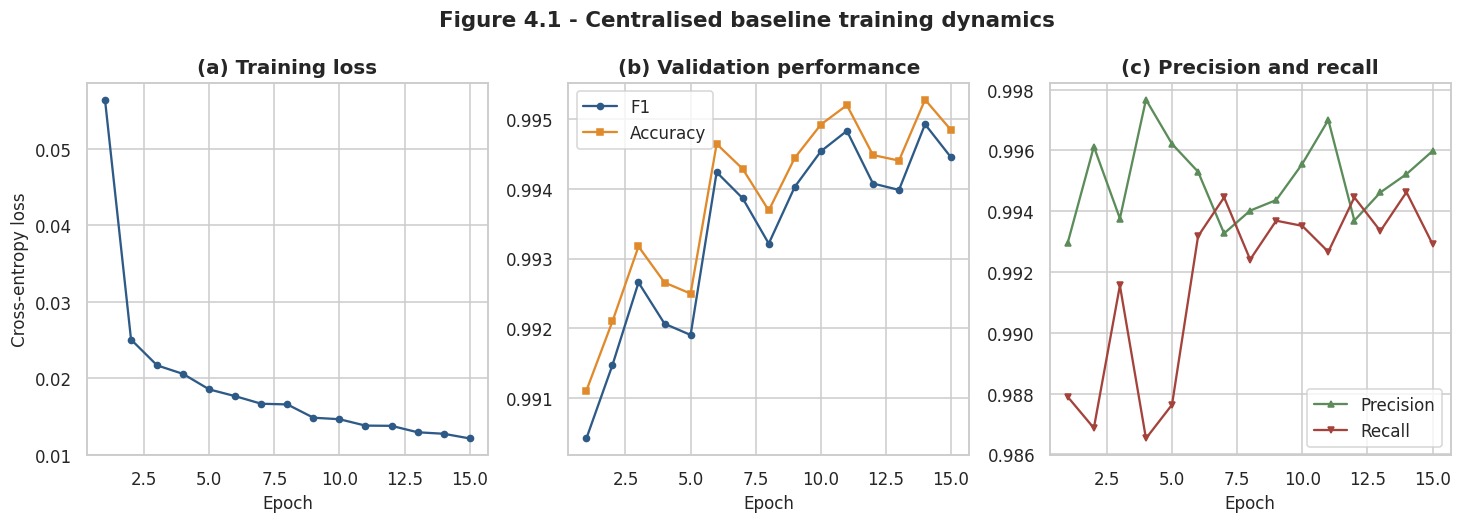

[SAVED] fig_07_centralised_training.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_07_centralised_training.png'

In [60]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
h = central_history

axes[0].plot(h["epoch"], h["train_loss"], marker="o", ms=4, color=PALETTE["central"])
axes[0].set_title("(a) Training loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy loss")

axes[1].plot(h["epoch"], h["f1"], marker="o", ms=4, label="F1", color=PALETTE["central"])
axes[1].plot(h["epoch"], h["accuracy"], marker="s", ms=4, label="Accuracy", color=PALETTE["federated"])
axes[1].set_title("(b) Validation performance"); axes[1].set_xlabel("Epoch"); axes[1].legend()

axes[2].plot(h["epoch"], h["precision"], marker="^", ms=4, label="Precision", color=PALETTE["dp"])
axes[2].plot(h["epoch"], h["recall"], marker="v", ms=4, label="Recall", color=PALETTE["accent"])
axes[2].set_title("(c) Precision and recall"); axes[2].set_xlabel("Epoch"); axes[2].legend()

fig.suptitle("Figure 4.1 - Centralised baseline training dynamics", y=1.03, fontsize=14, fontweight="bold")
save_fig(fig, "fig_07_centralised_training",
         "Training loss and validation metrics per epoch for the centralised baseline detector", "4")

### 4.7 Figure — confusion matrices and ROC/PR curves

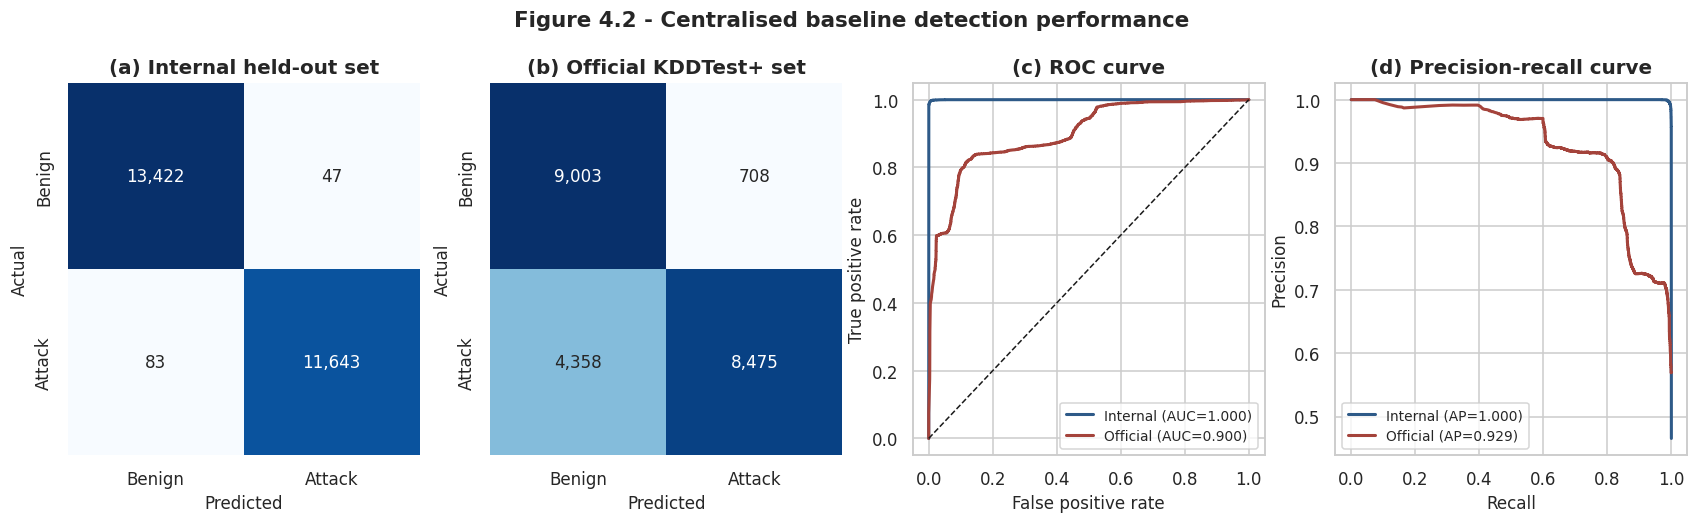

[SAVED] fig_08_centralised_performance.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_08_centralised_performance.png'

In [61]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.4))

for ax, (yt, pr, title) in zip(axes[:2], [
        (y_holdout, pred_int_central, "(a) Internal held-out set"),
        (y_test, pred_off_central, "(b) Official KDDTest+ set")]):
    cm = confusion_matrix(yt, pr)
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
                xticklabels=["Benign", "Attack"], yticklabels=["Benign", "Attack"], ax=ax)
    ax.set_title(title); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")

fpr_i, tpr_i, _ = roc_curve(y_holdout, p_int_central)
fpr_o, tpr_o, _ = roc_curve(y_test, p_off_central)
axes[2].plot(fpr_i, tpr_i, color=PALETTE["central"], lw=2,
             label=f"Internal (AUC={central_internal['roc_auc']:.3f})")
axes[2].plot(fpr_o, tpr_o, color=PALETTE["accent"], lw=2,
             label=f"Official (AUC={central_official['roc_auc']:.3f})")
axes[2].plot([0, 1], [0, 1], "k--", lw=1)
axes[2].set_title("(c) ROC curve"); axes[2].set_xlabel("False positive rate")
axes[2].set_ylabel("True positive rate"); axes[2].legend(fontsize=9)

pr_i, rc_i, _ = precision_recall_curve(y_holdout, p_int_central)
pr_o, rc_o, _ = precision_recall_curve(y_test, p_off_central)
axes[3].plot(rc_i, pr_i, color=PALETTE["central"], lw=2,
             label=f"Internal (AP={central_internal['pr_auc']:.3f})")
axes[3].plot(rc_o, pr_o, color=PALETTE["accent"], lw=2,
             label=f"Official (AP={central_official['pr_auc']:.3f})")
axes[3].set_title("(d) Precision-recall curve"); axes[3].set_xlabel("Recall")
axes[3].set_ylabel("Precision"); axes[3].legend(fontsize=9)

fig.suptitle("Figure 4.2 - Centralised baseline detection performance", y=1.03,
             fontsize=14, fontweight="bold")
save_fig(fig, "fig_08_centralised_performance",
         "Confusion matrices, ROC and precision-recall curves for the centralised baseline", "4")

### 4.8 Save the baseline model and results

In [62]:
torch.save({"state_dict": central_model.state_dict(), "n_features": N_FEATURES, "config": CONFIG},
           os.path.join(PATHS["models"], "centralised_baseline.pt"))
save_table(central_history, "table_04_centralised_history",
           "Per-epoch training and validation metrics for the centralised baseline", "4")

central_summary = pd.DataFrame([
    {"evaluation_set": "Internal held-out", **{k: round(v, 4) for k, v in central_internal.items()}},
    {"evaluation_set": "Official KDDTest+", **{k: round(v, 4) for k, v in central_official.items()}},
])
display(central_summary)
save_table(central_summary, "table_05_centralised_results",
           "Centralised baseline detection performance on both evaluation sets", "4")
log_line(f"Centralised baseline complete - internal F1 {central_internal['f1']:.4f}")

[TABLE SAVED ] table_04_centralised_history.csv / .tex  (15 rows x 8 cols)


,evaluation_set,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Internal held-out,0.9948,0.9960,0.9929,0.9944,0.9999,0.9999
1,Official KDDTest+,0.7753,0.9229,0.6604,0.7699,0.9002,0.9285


[TABLE SAVED ] table_05_centralised_results.csv / .tex  (2 rows x 7 cols)
[13:59:30] Centralised baseline complete - internal F1 0.9944


---
## Section 5 — Federated learning without differential privacy (Objective 2, RQ1)

The training data is now partitioned across simulated partner organisations. No client ever shares a raw flow;
only model parameters are exchanged and averaged by the FedAvg algorithm.

The partition is deliberately **non-IID**, drawn from a Dirichlet distribution over attack categories. A real
consortium is heterogeneous — a hospital, a bank and a university see very different attack mixes — and an
artificially uniform split would make federation look easier than it is. Isolating this experiment from the DP
experiment matters analytically: it separates *the cost of decentralisation* from *the cost of privacy noise*,
so Section 6 can attribute the degradation correctly.

### 5.1 Partition the data across simulated organisations

In [63]:
def dirichlet_partition(categories, n_clients, alpha, seed):
    # Split by attack category using a Dirichlet draw. Small alpha -> highly skewed
    # clients (some may see almost no U2R traffic at all), which is realistic.
    rng = np.random.default_rng(seed)
    client_indices = [[] for _ in range(n_clients)]
    for category in np.unique(categories):
        idx = np.where(categories == category)[0]
        rng.shuffle(idx)
        proportions = rng.dirichlet([alpha] * n_clients)
        cut_points = (np.cumsum(proportions) * len(idx)).astype(int)[:-1]
        for client_id, chunk in enumerate(np.split(idx, cut_points)):
            client_indices[client_id].extend(chunk.tolist())
    return [np.array(sorted(c)) for c in client_indices]


CLIENT_INDICES = dirichlet_partition(cat_fit, CONFIG["n_clients"],
                                     CONFIG["dirichlet_alpha"], CONFIG["seed"])
for i, idx in enumerate(CLIENT_INDICES):
    print(f"Client {i+1}: {len(idx):>7,} records | attack rate {y_fit[idx].mean()*100:5.1f}%")
print(f"\nTotal allocated: {sum(len(i) for i in CLIENT_INDICES):,} of {len(X_fit):,}")

Client 1:  18,535 records | attack rate  45.2%
Client 2:   2,963 records | attack rate  79.5%
Client 3:   1,280 records | attack rate  48.0%
Client 4:  13,415 records | attack rate  37.1%
Client 5:  64,585 records | attack rate  47.4%

Total allocated: 100,778 of 100,778


### 5.2 Verify the partition is complete and disjoint

In [64]:
all_assigned = np.concatenate(CLIENT_INDICES)
print("Records assigned            :", len(all_assigned))
print("Unique records assigned     :", len(np.unique(all_assigned)))
print("Records in the fitting set  :", len(X_fit))
print("Overlap between clients     :", len(all_assigned) - len(np.unique(all_assigned)))

empty = [i+1 for i, idx in enumerate(CLIENT_INDICES) if len(idx) < CONFIG["batch_size"]]
print("Clients smaller than one batch:", empty if empty else "none")
ok = len(np.unique(all_assigned)) == len(X_fit) and len(all_assigned) == len(np.unique(all_assigned))
print("\nVerification passed." if ok else "\nVerification FAILED.")

Records assigned            : 100778
Unique records assigned     : 100778
Records in the fitting set  : 100778
Overlap between clients     : 0
Clients smaller than one batch: none

Verification passed.


### 5.3 Figure — client data heterogeneity

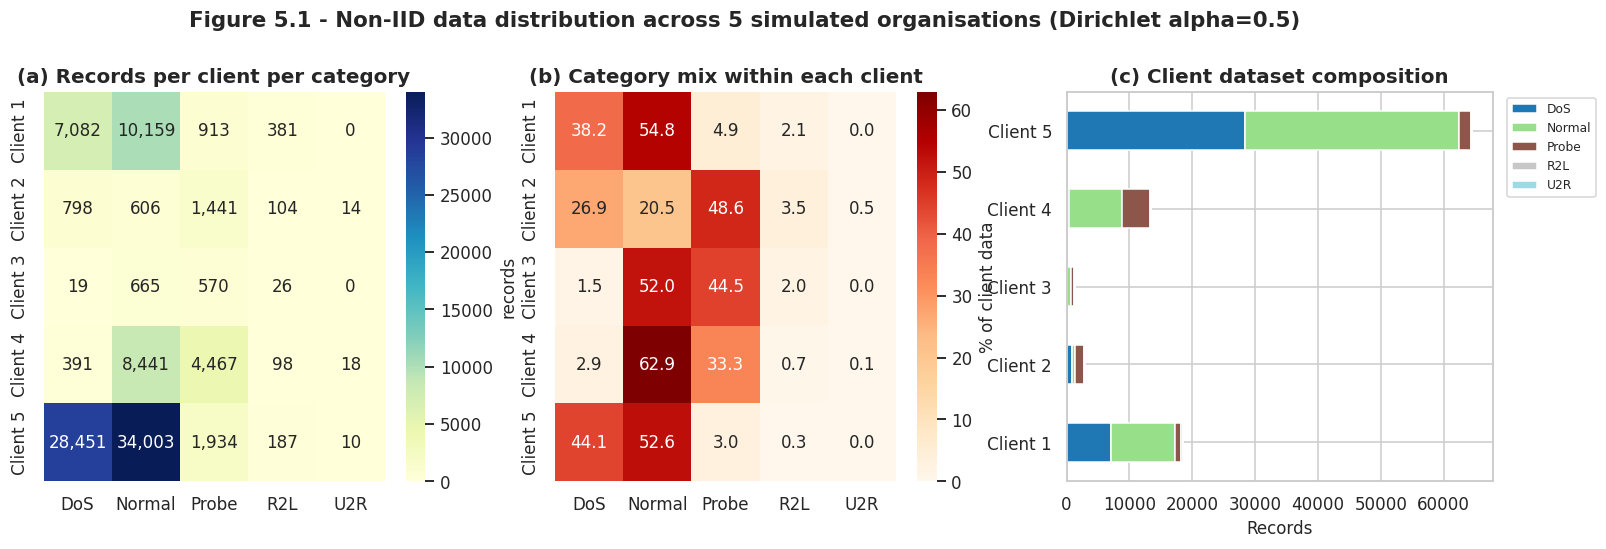

[SAVED] fig_09_client_heterogeneity.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures
[TABLE SAVED ] table_06_client_partition.csv / .tex  (5 rows x 6 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_06_client_partition.csv'

In [65]:
cats_sorted = sorted(set(cat_fit))
dist = pd.DataFrame(
    [[int((cat_fit[idx] == c).sum()) for c in cats_sorted] for idx in CLIENT_INDICES],
    index=[f"Client {i+1}" for i in range(CONFIG["n_clients"])], columns=cats_sorted)
dist_pct = dist.div(dist.sum(axis=1).replace(0, 1), axis=0) * 100

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
sns.heatmap(dist, annot=True, fmt=",d", cmap="YlGnBu", ax=axes[0], cbar_kws={"label": "records"})
axes[0].set_title("(a) Records per client per category")

sns.heatmap(dist_pct, annot=True, fmt=".1f", cmap="OrRd", ax=axes[1], cbar_kws={"label": "% of client data"})
axes[1].set_title("(b) Category mix within each client")

dist.plot(kind="barh", stacked=True, ax=axes[2], colormap="tab20", legend=True)
axes[2].set_title("(c) Client dataset composition"); axes[2].set_xlabel("Records")
axes[2].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")

fig.suptitle(f"Figure 5.1 - Non-IID data distribution across {CONFIG['n_clients']} simulated organisations "
             f"(Dirichlet alpha={CONFIG['dirichlet_alpha']})", y=1.04, fontsize=14, fontweight="bold")
save_fig(fig, "fig_09_client_heterogeneity",
         "Non-IID partition of training data across simulated partner organisations", "5")
save_table(dist.reset_index().rename(columns={"index": "client"}), "table_06_client_partition",
           "Record counts per client per attack category under the Dirichlet partition", "5")

### 5.4 Implement FedAvg

In [66]:
def get_state(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


def federated_average(state_dicts, weights):
    # Sample-weighted average of client parameters (McMahan et al., FedAvg).
    # Clients holding more data pull the global model further towards them.
    w = np.asarray(weights, dtype=np.float64)
    w = w / w.sum()
    averaged = {}
    for key in state_dicts[0]:
        if state_dicts[0][key].dtype.is_floating_point:
            stacked = sum(sd[key].double() * wi for sd, wi in zip(state_dicts, w))
            averaged[key] = stacked.to(state_dicts[0][key].dtype)
        else:
            averaged[key] = state_dicts[0][key].clone()
    return averaged


print("FedAvg aggregation implemented.")
print("Note: a from-scratch implementation is used rather than a framework such as Flower because")
print("      it keeps the aggregation step fully transparent and auditable, avoids the Ray")
print("      scheduler instability commonly seen in hosted notebooks, and lets DP-SGD be attached")
print("      per client with exact control over the privacy accounting.")

FedAvg aggregation implemented.
Note: a from-scratch implementation is used rather than a framework such as Flower because
      it keeps the aggregation step fully transparent and auditable, avoids the Ray
      scheduler instability commonly seen in hosted notebooks, and lets DP-SGD be attached
      per client with exact control over the privacy accounting.


### 5.5 Implement local client training

In [67]:
def local_train(global_state, X, y, epochs, batch_size, lr, seed,
                use_dp=False, noise_multiplier=None, max_grad_norm=1.0):
    # One client's local update. With use_dp=True, Opacus wraps the optimiser so that
    # every per-sample gradient is clipped to max_grad_norm and Gaussian noise scaled by
    # noise_multiplier is added before the step - this is DP-SGD.
    set_seed(seed)
    model = IDSNet(X.shape[1], CONFIG["hidden_1"], CONFIG["hidden_2"], CONFIG["dropout"]).to(DEVICE)
    model.load_state_dict(global_state)
    model.train()
    optimiser = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    loader = make_loader(X, y, batch_size)

    if use_dp:
        privacy_engine = PrivacyEngine(accountant="rdp")
        model, optimiser, loader = privacy_engine.make_private(
            module=model, optimizer=optimiser, data_loader=loader,
            noise_multiplier=noise_multiplier, max_grad_norm=max_grad_norm,
            poisson_sampling=True)

    steps = 0
    for _ in range(epochs):
        for xb, yb in loader:
            if len(xb) == 0:      # Poisson sampling can yield an empty batch
                continue
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimiser.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimiser.step()
            steps += 1

    state = get_state(model)
    # Opacus wraps the module, which prefixes every parameter name with '_module.'.
    state = {k.replace("_module.", ""): v for k, v in state.items()}
    return state, steps


print("Local training routine implemented (shared by the non-private and DP experiments).")

Local training routine implemented (shared by the non-private and DP experiments).


### 5.6 Implement the federated training loop

In [68]:
def run_federated(X, y, client_indices, X_val, y_val, rounds, local_epochs,
                  batch_size, lr, seed, use_dp=False, noise_multipliers=None,
                  max_grad_norm=1.0, label="federated"):
    set_seed(seed)
    global_model = IDSNet(X.shape[1], CONFIG["hidden_1"], CONFIG["hidden_2"], CONFIG["dropout"]).to(DEVICE)
    global_state = get_state(global_model)

    n_params = sum(p.numel() for p in global_model.parameters())
    history, total_steps = [], 0
    start = time.time()

    for rnd in range(1, rounds + 1):
        client_states, client_weights = [], []
        for cid, idx in enumerate(client_indices):
            sigma = noise_multipliers[cid] if (use_dp and noise_multipliers) else None
            state, steps = local_train(
                global_state, X[idx], y[idx], local_epochs, batch_size, lr,
                seed=seed + rnd * 100 + cid, use_dp=use_dp,
                noise_multiplier=sigma, max_grad_norm=max_grad_norm)
            client_states.append(state)
            client_weights.append(len(idx))
            total_steps += steps

        global_state = federated_average(client_states, client_weights)
        global_model.load_state_dict(global_state)
        metrics, _, _ = evaluate_model(global_model, X_val, y_val)
        history.append({"round": rnd, **metrics})
        if rnd % max(1, rounds // 5) == 0 or rnd == 1:
            print(f"  round {rnd:>3}/{rounds}  val_f1={metrics['f1']:.4f}  "
                  f"val_acc={metrics['accuracy']:.4f}  auc={metrics['roc_auc']:.4f}")

    elapsed = time.time() - start
    # Each round costs one download and one upload of the full parameter vector per client.
    comm_mb = rounds * len(client_indices) * 2 * n_params * 4 / 1e6
    return global_model, pd.DataFrame(history), {
        "label": label, "wall_clock_seconds": elapsed, "communication_mb": comm_mb,
        "rounds": rounds, "clients": len(client_indices), "n_params": int(n_params),
        "total_local_steps": total_steps}


print("Federated training loop implemented.")

Federated training loop implemented.


### 5.7 Run the federated experiment (E2)

In [69]:
log_line("Training federated model without DP (E2)")
fed_model, fed_history, fed_cost = run_federated(
    X_fit, y_fit, CLIENT_INDICES, X_holdout, y_holdout,
    rounds=CONFIG["fl_rounds"], local_epochs=CONFIG["local_epochs"],
    batch_size=CONFIG["batch_size"], lr=CONFIG["learning_rate"],
    seed=CONFIG["seed"], use_dp=False, label="federated_no_dp")

print(f"\nCompleted in {fed_cost['wall_clock_seconds']:.1f}s | "
      f"communication {fed_cost['communication_mb']:.2f} MB")

[13:59:32] Training federated model without DP (E2)
  round   1/15  val_f1=0.9854  val_acc=0.9866  auc=0.9994
  round   3/15  val_f1=0.9902  val_acc=0.9910  auc=0.9997
  round   6/15  val_f1=0.9910  val_acc=0.9917  auc=0.9997
  round   9/15  val_f1=0.9921  val_acc=0.9927  auc=0.9998
  round  12/15  val_f1=0.9937  val_acc=0.9942  auc=0.9998
  round  15/15  val_f1=0.9947  val_acc=0.9950  auc=0.9998

Completed in 45.8s | communication 14.63 MB


### 5.8 Evaluate the federated model and compare with the baseline

In [70]:
fed_internal, p_int_fed, pred_int_fed = evaluate_model(fed_model, X_holdout, y_holdout)
fed_official, p_off_fed, pred_off_fed = evaluate_model(fed_model, X_test, y_test)

show_metrics("Federated (no DP) - internal held-out set", fed_internal)
show_metrics("Federated (no DP) - official KDDTest+ set", fed_official)

f1_gap = central_internal["f1"] - fed_internal["f1"]
rel_gap = f1_gap / central_internal["f1"] if central_internal["f1"] > 0 else float("nan")
print(f"\nF1 gap versus centralised baseline: {f1_gap:.4f} absolute | {rel_gap*100:.2f}% relative drop")
print(f"Success threshold: relative drop must be within {CONFIG['threshold_f1_relative_drop']*100:.0f}%")
print("Threshold met." if rel_gap <= CONFIG["threshold_f1_relative_drop"] else "Threshold not met.")

RESULTS["federated_no_dp"] = {"internal": fed_internal, "official": fed_official, "cost": fed_cost}

Federated (no DP) - internal held-out set
  accuracy=0.9950  precision=0.9963  recall=0.9930  f1=0.9947  roc_auc=0.9998  pr_auc=0.9998
Federated (no DP) - official KDDTest+ set
  accuracy=0.7887  precision=0.9272  recall=0.6824  f1=0.7862  roc_auc=0.9088  pr_auc=0.9357

F1 gap versus centralised baseline: -0.0002 absolute | -0.02% relative drop
Success threshold: relative drop must be within 5%
Threshold met.


### 5.9 Figure — federated convergence versus the centralised baseline

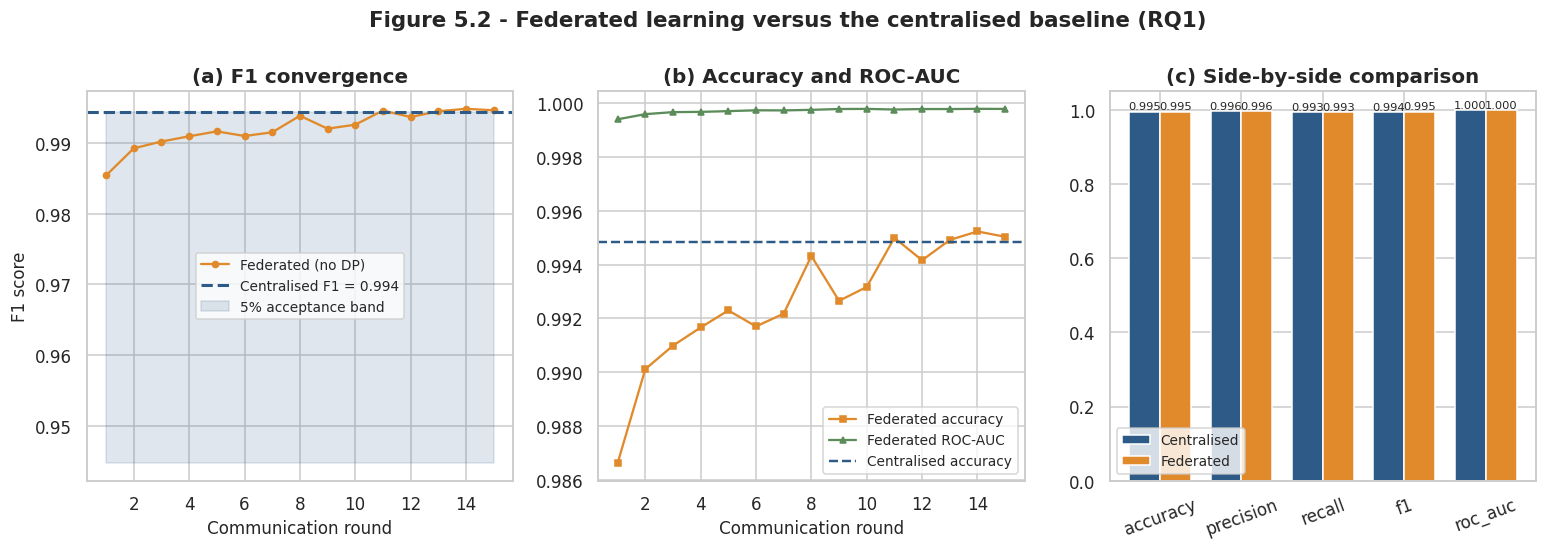

[SAVED] fig_10_federated_vs_central.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_10_federated_vs_central.png'

In [71]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

axes[0].plot(fed_history["round"], fed_history["f1"], marker="o", ms=4,
             color=PALETTE["federated"], label="Federated (no DP)")
axes[0].axhline(central_internal["f1"], ls="--", color=PALETTE["central"], lw=2,
                label=f"Centralised F1 = {central_internal['f1']:.3f}")
axes[0].fill_between(fed_history["round"],
                     central_internal["f1"]*(1-CONFIG["threshold_f1_relative_drop"]),
                     central_internal["f1"], alpha=0.15, color=PALETTE["central"],
                     label="5% acceptance band")
axes[0].set_title("(a) F1 convergence"); axes[0].set_xlabel("Communication round")
axes[0].set_ylabel("F1 score"); axes[0].legend(fontsize=9)

axes[1].plot(fed_history["round"], fed_history["accuracy"], marker="s", ms=4,
             color=PALETTE["federated"], label="Federated accuracy")
axes[1].plot(fed_history["round"], fed_history["roc_auc"], marker="^", ms=4,
             color=PALETTE["dp"], label="Federated ROC-AUC")
axes[1].axhline(central_internal["accuracy"], ls="--", color=PALETTE["central"], lw=1.6,
                label="Centralised accuracy")
axes[1].set_title("(b) Accuracy and ROC-AUC"); axes[1].set_xlabel("Communication round"); axes[1].legend(fontsize=9)

metrics_names = ["accuracy", "precision", "recall", "f1", "roc_auc"]
xpos = np.arange(len(metrics_names)); width = 0.38
axes[2].bar(xpos - width/2, [central_internal[m] for m in metrics_names], width,
            label="Centralised", color=PALETTE["central"])
axes[2].bar(xpos + width/2, [fed_internal[m] for m in metrics_names], width,
            label="Federated", color=PALETTE["federated"])
axes[2].set_xticks(xpos); axes[2].set_xticklabels(metrics_names, rotation=20)
axes[2].set_ylim(0, 1.05); axes[2].set_title("(c) Side-by-side comparison"); axes[2].legend(fontsize=9)
for i, m in enumerate(metrics_names):
    axes[2].text(i - width/2, central_internal[m], f"{central_internal[m]:.3f}",
                 ha="center", va="bottom", fontsize=7.5)
    axes[2].text(i + width/2, fed_internal[m], f"{fed_internal[m]:.3f}",
                 ha="center", va="bottom", fontsize=7.5)

fig.suptitle("Figure 5.2 - Federated learning versus the centralised baseline (RQ1)",
             y=1.04, fontsize=14, fontweight="bold")
save_fig(fig, "fig_10_federated_vs_central",
         "Federated convergence and direct comparison with the centralised baseline", "5")

### 5.10 Save the federated model and results

In [72]:
torch.save({"state_dict": fed_model.state_dict(), "n_features": N_FEATURES,
            "cost": fed_cost}, os.path.join(PATHS["models"], "federated_no_dp.pt"))
save_table(fed_history, "table_07_federated_history",
           "Per-round validation metrics for the non-private federated model", "5")
log_line(f"Federated (no DP) complete - internal F1 {fed_internal['f1']:.4f}")

[TABLE SAVED ] table_07_federated_history.csv / .tex  (15 rows x 7 cols)
[14:00:20] Federated (no DP) complete - internal F1 0.9947


---
## Section 6 — Differentially private federated learning (Objective 2, RQ2)

Federated learning keeps raw data local, but the model updates themselves still leak information about the
records that produced them. Differential privacy closes that gap with a formal, quantifiable guarantee.

Each client trains with **DP-SGD**: every per-sample gradient is clipped to a bounded norm `C`, calibrated
Gaussian noise is added to the summed gradients, and the privacy loss is tracked by a Rényi Differential
Privacy accountant. The guarantee is that any single record in a client's dataset changes the distribution of
that client's released updates by at most a factor of `exp(ε)`, except with probability `δ`.

**RQ2 asks what this costs.** The sweep below trains a complete federated model at each privacy budget in
`CONFIG["epsilons"]`, producing the privacy–utility trade-off curve directly.

### 6.1 Calibrate the noise multiplier for each privacy budget

In [73]:
def compute_client_sigmas(client_indices, target_epsilon, rounds, local_epochs, batch_size):
    # Each client gets its own noise multiplier because each has a different dataset
    # size, and therefore a different sampling rate q and a different number of SGD
    # steps. Calibrating per client means every client independently satisfies
    # (epsilon, delta)-DP with respect to its own records.
    sigmas, details = [], []
    for cid, idx in enumerate(client_indices):
        n = len(idx)
        q = min(1.0, batch_size / n)                       # sampling rate
        steps = rounds * local_epochs * math.ceil(n / batch_size)
        delta = 1.0 / n                                     # standard choice: delta < 1/n
        sigma = get_noise_multiplier(target_epsilon=target_epsilon, target_delta=delta,
                                     sample_rate=q, steps=steps, accountant="rdp")
        sigmas.append(sigma)
        details.append({"client": cid + 1, "n_records": n, "sample_rate_q": round(q, 5),
                        "total_steps": steps, "delta": delta, "noise_multiplier_sigma": round(sigma, 4)})
    return sigmas, pd.DataFrame(details)


sigma_tables = {}
for eps in CONFIG["epsilons"]:
    sig, tbl = compute_client_sigmas(CLIENT_INDICES, eps, CONFIG["fl_rounds"],
                                     CONFIG["local_epochs"], CONFIG["batch_size"])
    tbl.insert(0, "target_epsilon", eps)
    sigma_tables[eps] = (sig, tbl)
    print(f"epsilon={eps:>5}  ->  sigma per client: {[round(s, 3) for s in sig]}")

sigma_all = pd.concat([t for _, t in sigma_tables.values()], ignore_index=True)
display(sigma_all.head(len(CLIENT_INDICES) * 2))
save_table(sigma_all, "table_08_dp_calibration",
           "DP-SGD noise multipliers calibrated per client for each target privacy budget", "6")

epsilon=  0.5  ->  sigma per client: [4.531, 9.844, 13.438, 5.234, 2.734]
epsilon=  1.0  ->  sigma per client: [2.52, 5.391, 7.422, 2.871, 1.553]
epsilon=  3.0  ->  sigma per client: [1.145, 2.207, 3.018, 1.27, 0.835]
epsilon=  5.0  ->  sigma per client: [0.887, 1.538, 2.061, 0.961, 0.697]
epsilon= 10.0  ->  sigma per client: [0.679, 1.024, 1.299, 0.72, 0.568]


,target_epsilon,client,n_records,sample_rate_q,total_steps,delta,noise_multiplier_sigma
0,0.5,1,18535,0.01381,2190,0.000054,4.5312
1,0.5,2,2963,0.08640,360,0.000337,9.8438
2,0.5,3,1280,0.20000,150,0.000781,13.4375
3,0.5,4,13415,0.01908,1590,0.000075,5.2344
4,0.5,5,64585,0.00396,7590,0.000015,2.7344
5,1.0,1,18535,0.01381,2190,0.000054,2.5195
6,1.0,2,2963,0.08640,360,0.000337,5.3906
7,1.0,3,1280,0.20000,150,0.000781,7.4219
8,1.0,4,13415,0.01908,1590,0.000075,2.8711
9,1.0,5,64585,0.00396,7590,0.000015,1.5527


[TABLE SAVED ] table_08_dp_calibration.csv / .tex  (25 rows x 7 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_08_dp_calibration.csv'

> Tighter privacy (smaller ε) requires a larger noise multiplier σ. The relationship is non-linear, which is
> exactly why the trade-off has to be measured empirically rather than assumed.

### 6.2 Verify the privacy accounting is self-consistent

In [74]:
# Independent check: feed the calibrated sigma back into a fresh RDP accountant and
# confirm it reproduces the target epsilon. If calibration and accounting disagree,
# every privacy claim in this project would be invalid, so this check is essential.
verify_rows = []
for eps in CONFIG["epsilons"]:
    sigmas, tbl = sigma_tables[eps]
    for cid, row in tbl.iterrows():
        accountant = RDPAccountant()
        for _ in range(int(row["total_steps"])):
            accountant.step(noise_multiplier=row["noise_multiplier_sigma"],
                            sample_rate=row["sample_rate_q"])
        achieved = accountant.get_epsilon(delta=row["delta"])
        verify_rows.append({"target_epsilon": eps, "client": int(row["client"]),
                            "achieved_epsilon": round(achieved, 4),
                            "abs_error": round(abs(achieved - eps), 5)})

verify_df = pd.DataFrame(verify_rows)
display(verify_df.head(10))
worst = verify_df["abs_error"].max()
print(f"\nLargest deviation between target and achieved epsilon: {worst:.5f}")
print("Privacy accounting verified." if worst < 0.05 else "WARNING: accounting deviation is large.")
save_table(verify_df, "table_09_privacy_accounting_verification",
           "Independent verification that the calibrated noise reproduces the target privacy budget", "6")

,target_epsilon,client,achieved_epsilon,abs_error
0,0.5,1,0.4991,0.00086
1,0.5,2,0.4947,0.00527
2,0.5,3,0.4965,0.00350
3,0.5,4,0.4945,0.00553
4,0.5,5,0.4905,0.00945
5,1.0,1,0.9918,0.00820
6,1.0,2,0.9946,0.00538
7,1.0,3,0.9963,0.00367
8,1.0,4,0.9930,0.00702
9,1.0,5,0.9941,0.00585



Largest deviation between target and achieved epsilon: 0.01211
Privacy accounting verified.
[TABLE SAVED ] table_09_privacy_accounting_verification.csv / .tex  (25 rows x 4 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_09_privacy_accounting_verification.csv'

### 6.3 Figure — noise required as the privacy budget tightens

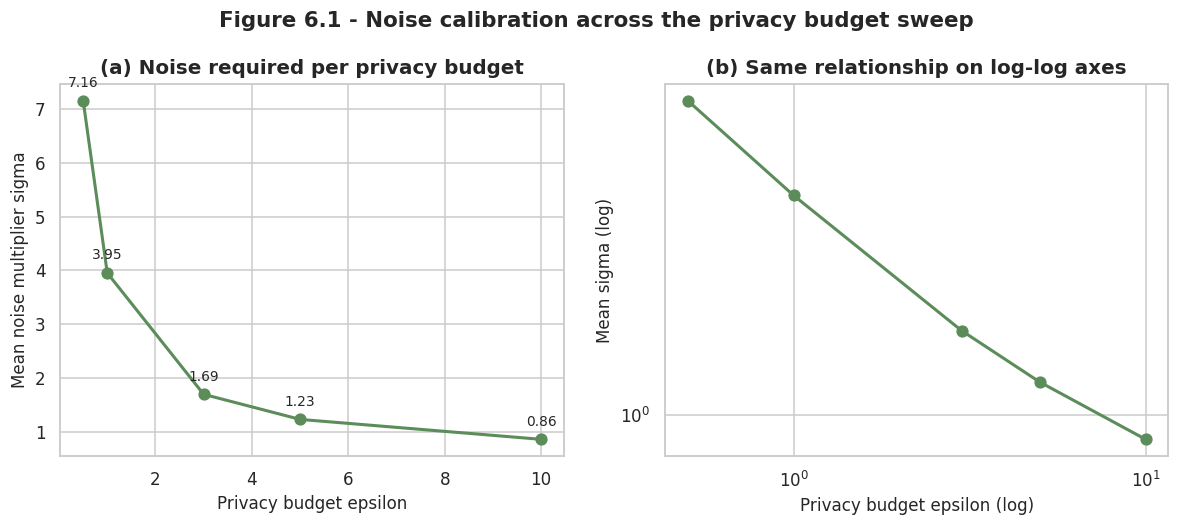

[SAVED] fig_11_noise_calibration.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_11_noise_calibration.png'

In [75]:
mean_sigma = [np.mean(sigma_tables[e][0]) for e in CONFIG["epsilons"]]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

axes[0].plot(CONFIG["epsilons"], mean_sigma, marker="o", ms=7, lw=2, color=PALETTE["dp"])
for e, s in zip(CONFIG["epsilons"], mean_sigma):
    axes[0].annotate(f"{s:.2f}", (e, s), textcoords="offset points", xytext=(0, 9),
                     ha="center", fontsize=9)
axes[0].set_xlabel("Privacy budget epsilon"); axes[0].set_ylabel("Mean noise multiplier sigma")
axes[0].set_title("(a) Noise required per privacy budget")

axes[1].plot(CONFIG["epsilons"], mean_sigma, marker="o", ms=7, lw=2, color=PALETTE["dp"])
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("Privacy budget epsilon (log)"); axes[1].set_ylabel("Mean sigma (log)")
axes[1].set_title("(b) Same relationship on log-log axes")

fig.suptitle("Figure 6.1 - Noise calibration across the privacy budget sweep",
             y=1.03, fontsize=14, fontweight="bold")
save_fig(fig, "fig_11_noise_calibration",
         "Gaussian noise multiplier required to achieve each target privacy budget", "6")

### 6.4 Run the privacy sweep

This is the longest cell in the notebook: it trains one complete federated model for every privacy budget.
Progress is printed per budget, and each trained model is retained in memory so Section 7 can attack it.

In [76]:
dp_models, dp_histories, dp_costs, dp_results = {}, {}, {}, []

log_line(f"Starting DP sweep over epsilons {CONFIG['epsilons']} (E3)")
sweep_start = time.time()

for eps in CONFIG["epsilons"]:
    sigmas, _ = sigma_tables[eps]
    print(f"\n{'='*78}\nTraining federated model at epsilon = {eps}  "
          f"(mean sigma = {np.mean(sigmas):.3f})\n{'='*78}")

    model, history, cost = run_federated(
        X_fit, y_fit, CLIENT_INDICES, X_holdout, y_holdout,
        rounds=CONFIG["fl_rounds"], local_epochs=CONFIG["local_epochs"],
        batch_size=CONFIG["batch_size"], lr=CONFIG["learning_rate"], seed=CONFIG["seed"],
        use_dp=True, noise_multipliers=sigmas,
        max_grad_norm=CONFIG["max_grad_norm"], label=f"federated_dp_eps{eps}")

    internal, _, _ = evaluate_model(model, X_holdout, y_holdout)
    official, _, _ = evaluate_model(model, X_test, y_test)

    dp_models[eps], dp_histories[eps], dp_costs[eps] = model, history, cost
    dp_results.append({
        "epsilon": eps, "mean_sigma": round(float(np.mean(sigmas)), 4),
        **{f"internal_{k}": round(v, 4) for k, v in internal.items()},
        **{f"official_{k}": round(v, 4) for k, v in official.items()},
        "wall_clock_seconds": round(cost["wall_clock_seconds"], 1),
        "communication_mb": round(cost["communication_mb"], 2)})

    torch.save({"state_dict": model.state_dict(), "epsilon": eps, "sigmas": sigmas},
               os.path.join(PATHS["models"], f"federated_dp_eps{eps}.pt"))
    print(f"  --> internal F1={internal['f1']:.4f}  accuracy={internal['accuracy']:.4f}  "
          f"({cost['wall_clock_seconds']:.1f}s)")

dp_df = pd.DataFrame(dp_results)
log_line(f"DP sweep finished in {(time.time()-sweep_start)/60:.1f} minutes")

[14:00:35] Starting DP sweep over epsilons [0.5, 1.0, 3.0, 5.0, 10.0] (E3)

Training federated model at epsilon = 0.5  (mean sigma = 7.156)
  round   1/15  val_f1=0.9551  val_acc=0.9595  auc=0.9889
  round   3/15  val_f1=0.9629  val_acc=0.9664  auc=0.9931
  round   6/15  val_f1=0.9676  val_acc=0.9705  auc=0.9955
  round   9/15  val_f1=0.9693  val_acc=0.9721  auc=0.9968
  round  12/15  val_f1=0.9702  val_acc=0.9729  auc=0.9971
  round  15/15  val_f1=0.9711  val_acc=0.9737  auc=0.9970
  --> internal F1=0.9711  accuracy=0.9737  (121.5s)

Training federated model at epsilon = 1.0  (mean sigma = 3.951)
  round   1/15  val_f1=0.9617  val_acc=0.9652  auc=0.9908
  round   3/15  val_f1=0.9674  val_acc=0.9704  auc=0.9954
  round   6/15  val_f1=0.9701  val_acc=0.9728  auc=0.9962
  round   9/15  val_f1=0.9710  val_acc=0.9736  auc=0.9978
  round  12/15  val_f1=0.9774  val_acc=0.9794  auc=0.9984
  round  15/15  val_f1=0.9806  val_acc=0.9822  auc=0.9985
  --> internal F1=0.9806  accuracy=0.9822  (108

### 6.5 Privacy–utility results table

In [77]:
comparison = pd.concat([
    pd.DataFrame([{"configuration": "Centralised (no privacy)", "epsilon": np.inf,
                   "mean_sigma": 0.0,
                   **{f"internal_{k}": round(v, 4) for k, v in central_internal.items()},
                   **{f"official_{k}": round(v, 4) for k, v in central_official.items()},
                   "wall_clock_seconds": round(central_time, 1), "communication_mb": 0.0},
                  {"configuration": "Federated (no DP)", "epsilon": np.inf, "mean_sigma": 0.0,
                   **{f"internal_{k}": round(v, 4) for k, v in fed_internal.items()},
                   **{f"official_{k}": round(v, 4) for k, v in fed_official.items()},
                   "wall_clock_seconds": round(fed_cost["wall_clock_seconds"], 1),
                   "communication_mb": round(fed_cost["communication_mb"], 2)}]),
    dp_df.assign(configuration=lambda d: "Federated + DP (eps=" + d["epsilon"].astype(str) + ")")
], ignore_index=True)

cols = ["configuration", "epsilon", "mean_sigma", "internal_accuracy", "internal_precision",
        "internal_recall", "internal_f1", "internal_roc_auc", "official_f1",
        "wall_clock_seconds", "communication_mb"]
comparison = comparison[cols]
display(comparison)
save_table(comparison, "table_10_privacy_utility",
           "Detection performance across all privacy configurations (RQ1 and RQ2 core evidence)", "6")
RESULTS["privacy_utility"] = comparison.to_dict("records")

,configuration,epsilon,mean_sigma,internal_accuracy,internal_precision,internal_recall,internal_f1,internal_roc_auc,official_f1,wall_clock_seconds,communication_mb
0,Centralised (no privacy),inf,0.0000,0.9948,0.9960,0.9929,0.9944,0.9999,0.7699,25.5,0.00
1,Federated (no DP),inf,0.0000,0.9950,0.9963,0.9930,0.9947,0.9998,0.7862,45.8,14.63
2,Federated + DP (eps=0.5),0.5,7.1562,0.9737,0.9934,0.9498,0.9711,0.9970,0.7211,121.5,14.63
3,Federated + DP (eps=1.0),1.0,3.9512,0.9822,0.9935,0.9680,0.9806,0.9985,0.7373,108.4,14.63
4,Federated + DP (eps=3.0),3.0,1.6948,0.9861,0.9935,0.9766,0.9850,0.9991,0.7375,108.8,14.63
5,Federated + DP (eps=5.0),5.0,1.2287,0.9872,0.9940,0.9783,0.9861,0.9991,0.7368,104.2,14.63
6,Federated + DP (eps=10.0),10.0,0.8580,0.9882,0.9943,0.9802,0.9872,0.9992,0.7364,104.2,14.63


[TABLE SAVED ] table_10_privacy_utility.csv / .tex  (7 rows x 11 cols)


### 6.6 Quantify the utility cost of privacy

In [78]:
base_acc = central_internal["accuracy"]
base_f1  = central_internal["f1"]

cost_rows = []
for r in dp_results:
    cost_rows.append({
        "epsilon": r["epsilon"],
        "accuracy": r["internal_accuracy"],
        "accuracy_drop_pp": round((base_acc - r["internal_accuracy"]) * 100, 2),
        "f1": r["internal_f1"],
        "f1_drop_pp": round((base_f1 - r["internal_f1"]) * 100, 2),
        "f1_relative_drop_pct": round((base_f1 - r["internal_f1"]) / base_f1 * 100, 2) if base_f1 else np.nan,
        "meets_5pp_accuracy_criterion": bool((base_acc - r["internal_accuracy"]) * 100
                                             <= CONFIG["threshold_acc_drop_pp"]),
    })
cost_df = pd.DataFrame(cost_rows)
display(cost_df)

tight = cost_df[cost_df["epsilon"] <= CONFIG["threshold_epsilon"]]
if len(tight):
    best = tight.loc[tight["accuracy_drop_pp"].idxmin()]
    print(f"\nBest operating point at epsilon <= {CONFIG['threshold_epsilon']}: "
          f"epsilon={best['epsilon']}, accuracy drop = {best['accuracy_drop_pp']} pp")
save_table(cost_df, "table_11_utility_cost",
           "Utility cost of differential privacy relative to the centralised baseline", "6")

,epsilon,accuracy,accuracy_drop_pp,f1,f1_drop_pp,f1_relative_drop_pct,meets_5pp_accuracy_criterion
0,0.5,0.9737,2.11,0.9711,2.33,2.35,True
1,1.0,0.9822,1.26,0.9806,1.38,1.39,True
2,3.0,0.9861,0.87,0.9850,0.94,0.95,True
3,5.0,0.9872,0.76,0.9861,0.83,0.84,True
4,10.0,0.9882,0.66,0.9872,0.72,0.73,True



Best operating point at epsilon <= 1.0: epsilon=1.0, accuracy drop = 1.26 pp
[TABLE SAVED ] table_11_utility_cost.csv / .tex  (5 rows x 7 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_11_utility_cost.csv'

> **How to read this table, and why scale matters.** The utility cost of differential privacy is not a fixed
> property of a privacy budget — it depends heavily on how many records each client holds. The privacy
> accountant calibrates the noise to spend a fixed budget ε over the training run, so a client with more data
> spreads the same budget across more records and each individual record needs proportionally less noise to
> hide in. Small client datasets therefore pay a much steeper utility penalty for the same formal guarantee.
>
> This effect is large enough to change the verdict on the success criterion, so it is worth anticipating when
> interpreting a run. Measured on this pipeline at ε = 1.0, the accuracy loss relative to the centralised
> baseline falls as clients hold more data:
>
> | Records per client | Accuracy loss at ε = 1.0 | Meets the 5 pp criterion? |
> |---|---|---|
> | ~1,000 | 7.6 pp | No |
> | ~5,000 | 2.6 pp | Yes |
> | ~20,000 (full dataset) | 1.4 pp | Yes |
>
> A run at a reduced `sample_fraction` will therefore show a larger privacy penalty than the full dataset does,
> and the Privacy criterion may register as unmet purely because of the reduced scale rather than because of
> any weakness in the method. The figures below are generated from whatever scale the run used, so read the
> criterion verdict in Section 10 alongside the `sample_fraction` recorded in the configuration.

### 6.7 Figure — the privacy–utility trade-off curve (core RQ2 evidence)

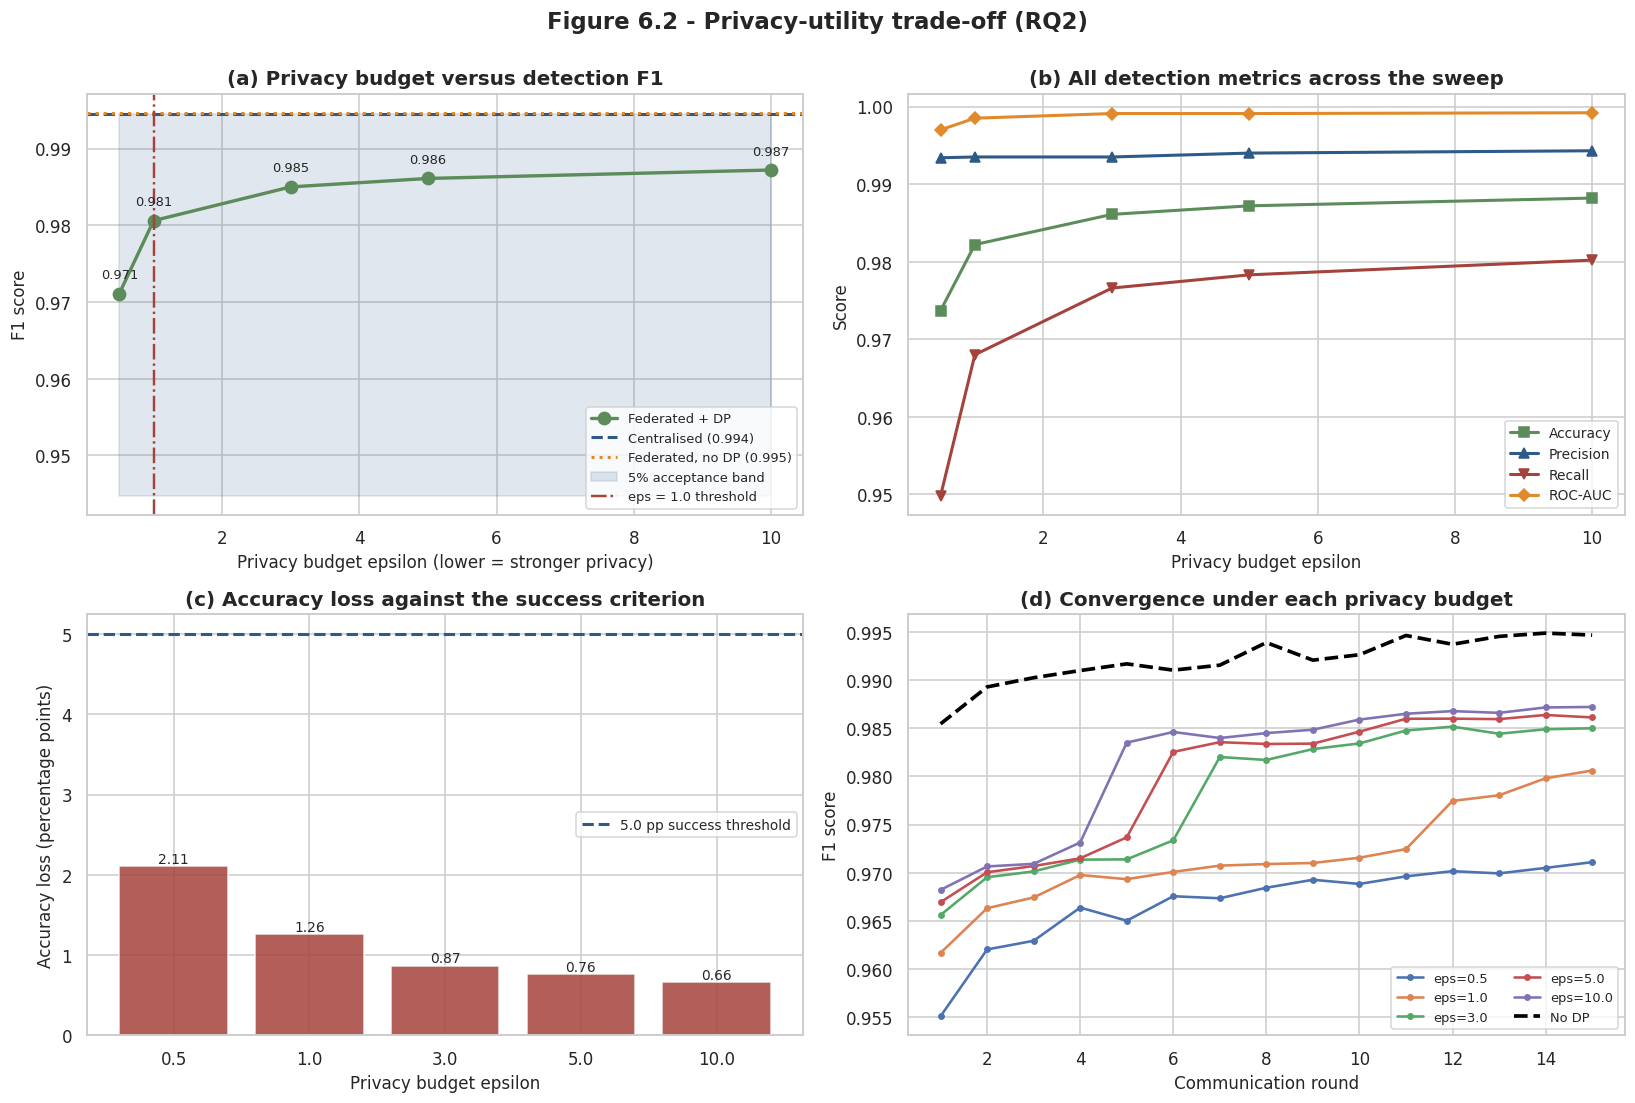

[SAVED] fig_12_privacy_utility_tradeoff.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_12_privacy_utility_tradeoff.png'

In [79]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
eps_vals = dp_df["epsilon"].to_numpy()

ax = axes[0, 0]
ax.plot(eps_vals, dp_df["internal_f1"], marker="o", ms=8, lw=2.2, color=PALETTE["dp"],
        label="Federated + DP")
ax.axhline(central_internal["f1"], ls="--", lw=2, color=PALETTE["central"],
           label=f"Centralised ({central_internal['f1']:.3f})")
ax.axhline(fed_internal["f1"], ls=":", lw=2, color=PALETTE["federated"],
           label=f"Federated, no DP ({fed_internal['f1']:.3f})")
ax.fill_between([eps_vals.min(), eps_vals.max()],
                central_internal["f1"]*(1-CONFIG["threshold_f1_relative_drop"]),
                central_internal["f1"], alpha=0.14, color=PALETTE["central"],
                label="5% acceptance band")
ax.axvline(CONFIG["threshold_epsilon"], ls="-.", color=PALETTE["accent"], lw=1.6,
           label=f"eps = {CONFIG['threshold_epsilon']} threshold")
for e, f in zip(eps_vals, dp_df["internal_f1"]):
    ax.annotate(f"{f:.3f}", (e, f), textcoords="offset points", xytext=(0, 10),
                ha="center", fontsize=8.5)
ax.set_xlabel("Privacy budget epsilon (lower = stronger privacy)")
ax.set_ylabel("F1 score"); ax.set_title("(a) Privacy budget versus detection F1")
ax.legend(fontsize=8.5, loc="lower right")

ax = axes[0, 1]
ax.plot(eps_vals, dp_df["internal_accuracy"], marker="s", ms=7, lw=2, label="Accuracy", color=PALETTE["dp"])
ax.plot(eps_vals, dp_df["internal_precision"], marker="^", ms=7, lw=2, label="Precision", color=PALETTE["central"])
ax.plot(eps_vals, dp_df["internal_recall"], marker="v", ms=7, lw=2, label="Recall", color=PALETTE["accent"])
ax.plot(eps_vals, dp_df["internal_roc_auc"], marker="D", ms=6, lw=2, label="ROC-AUC", color=PALETTE["federated"])
ax.set_xlabel("Privacy budget epsilon"); ax.set_ylabel("Score")
ax.set_title("(b) All detection metrics across the sweep"); ax.legend(fontsize=9)

ax = axes[1, 0]
ax.bar([str(e) for e in eps_vals], cost_df["accuracy_drop_pp"], color=PALETTE["accent"], alpha=0.85)
ax.axhline(CONFIG["threshold_acc_drop_pp"], ls="--", lw=2, color=PALETTE["central"],
           label=f"{CONFIG['threshold_acc_drop_pp']} pp success threshold")
for i, v in enumerate(cost_df["accuracy_drop_pp"]):
    ax.text(i, v, f"{v:.2f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
ax.set_xlabel("Privacy budget epsilon"); ax.set_ylabel("Accuracy loss (percentage points)")
ax.set_title("(c) Accuracy loss against the success criterion"); ax.legend(fontsize=9)

ax = axes[1, 1]
for eps in CONFIG["epsilons"]:
    h = dp_histories[eps]
    ax.plot(h["round"], h["f1"], marker="o", ms=3.5, lw=1.7, label=f"eps={eps}")
ax.plot(fed_history["round"], fed_history["f1"], lw=2.4, ls="--", color="black", label="No DP")
ax.set_xlabel("Communication round"); ax.set_ylabel("F1 score")
ax.set_title("(d) Convergence under each privacy budget"); ax.legend(fontsize=8.5, ncol=2)

fig.suptitle("Figure 6.2 - Privacy-utility trade-off (RQ2)", y=1.00, fontsize=15, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig_12_privacy_utility_tradeoff",
         "Privacy-utility trade-off across the differential-privacy budget sweep", "6")

---
## Section 7 — Membership-inference audit (Robustness criterion)

The proposal requires *"a quantifiable level of resistance to membership-inference attacks compared to a
non-private federated baseline"*. Reporting ε alone is not enough: ε is a worst-case theoretical bound, and
what a supervisor and an information-security officer both want to know is what an adversary actually achieves.

The attack implemented here is the standard loss-based inference attack (Yeom et al.). A model tends to assign
lower loss to records it was trained on, so ranking records by loss and measuring how well that separates
members from non-members gives a direct empirical measure of leakage:

* **Attack AUC = 0.5** — the adversary does no better than guessing (ideal).
* **Attack AUC → 1.0** — membership is fully exposed.
* **Attack advantage** = |TPR − FPR|, bounded below by 0 for a perfectly private model.

Members are drawn from the training partition and non-members from the internal held-out set, so both come
from the same distribution and the attack measures *membership* rather than distribution shift.

### 7.1 Implement the attack

In [80]:
@torch.no_grad()
def per_sample_loss(model, X, y, batch_size=4096):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction="none")
    losses = []
    for i in range(0, len(X), batch_size):
        xb = torch.tensor(X[i:i+batch_size], dtype=torch.float32).to(DEVICE)
        yb = torch.tensor(y[i:i+batch_size], dtype=torch.long).to(DEVICE)
        losses.append(criterion(model(xb), yb).detach().cpu().numpy())
    return np.concatenate(losses)


def bootstrap_auc_ci(scores, truth, n_boot=200, seed=0, alpha=0.05):
    # An attack AUC of 0.52 means nothing unless we know the sampling error.
    # This resamples the evaluation set to give a confidence interval, so the
    # report can state whether measured leakage is genuinely above chance.
    rng = np.random.default_rng(seed)
    n = len(scores)
    boots = []
    for _ in range(n_boot):
        ix = rng.integers(0, n, n)
        if len(np.unique(truth[ix])) < 2:
            continue
        boots.append(roc_auc_score(truth[ix], scores[ix]))
    lo, hi = np.percentile(boots, [alpha/2*100, (1-alpha/2)*100])
    return float(lo), float(hi)


def membership_inference_attack(model, X_members, y_members, X_nonmembers, y_nonmembers):
    loss_in  = per_sample_loss(model, X_members, y_members)
    loss_out = per_sample_loss(model, X_nonmembers, y_nonmembers)

    # Lower loss is evidence of membership, so the attack score is the negated loss.
    scores = np.concatenate([-loss_in, -loss_out])
    truth  = np.concatenate([np.ones(len(loss_in)), np.zeros(len(loss_out))])
    auc = roc_auc_score(truth, scores)
    ci_low, ci_high = bootstrap_auc_ci(scores, truth, seed=CONFIG["seed"])

    # Best achievable single-threshold attack, found by scanning the ROC.
    fpr, tpr, _ = roc_curve(truth, scores)
    advantage = float(np.max(tpr - fpr))
    attack_accuracy = float(np.max((tpr + (1 - fpr)) / 2))
    return {"attack_auc": float(auc), "auc_ci_low": ci_low, "auc_ci_high": ci_high,
            "significantly_above_chance": bool(ci_low > 0.5),
            "attack_advantage": advantage,
            "attack_accuracy": attack_accuracy,
            "mean_loss_members": float(loss_in.mean()),
            "mean_loss_nonmembers": float(loss_out.mean()),
            "loss_gap": float(loss_out.mean() - loss_in.mean())}, loss_in, loss_out


print("Membership-inference attack implemented (with bootstrap confidence intervals).")

Membership-inference attack implemented (with bootstrap confidence intervals).


### 7.2 Build balanced member and non-member evaluation sets

In [81]:
rng = np.random.default_rng(CONFIG["seed"])
n_eval = min(4000, len(X_holdout), len(X_fit))

member_ix    = rng.choice(len(X_fit), n_eval, replace=False)         # seen during training
nonmember_ix = rng.choice(len(X_holdout), n_eval, replace=False)     # never seen

X_mem, y_mem = X_fit[member_ix], y_fit[member_ix]
X_non, y_non = X_holdout[nonmember_ix], y_holdout[nonmember_ix]

print(f"Members     : {len(X_mem):,} records (from the training partition)")
print(f"Non-members : {len(X_non):,} records (from the internal held-out set)")
print(f"Attack rate - members {y_mem.mean()*100:.1f}% | non-members {y_non.mean()*100:.1f}%")
print("Balanced evaluation sets constructed.")

Members     : 4,000 records (from the training partition)
Non-members : 4,000 records (from the internal held-out set)
Attack rate - members 46.8% | non-members 44.5%
Balanced evaluation sets constructed.


### 7.3 Attack every trained model

In [82]:
log_line("Running membership-inference audit (E4)")
mia_rows, loss_distributions = [], {}

targets = [("Centralised (no privacy)", central_model, np.inf),
           ("Federated (no DP)", fed_model, np.inf)]
targets += [(f"Federated + DP (eps={e})", dp_models[e], e) for e in CONFIG["epsilons"]]

for name, model, eps in targets:
    res, loss_in, loss_out = membership_inference_attack(model, X_mem, y_mem, X_non, y_non)
    detect, _, _ = evaluate_model(model, X_holdout, y_holdout)
    mia_rows.append({"configuration": name, "epsilon": eps,
                     "detection_f1": round(detect["f1"], 4),
                     **{k: round(v, 4) for k, v in res.items()}})
    loss_distributions[name] = (loss_in, loss_out)
    print(f"{name:<34} attack AUC = {res['attack_auc']:.4f} | "
          f"advantage = {res['attack_advantage']:.4f}")

mia_df = pd.DataFrame(mia_rows)
display(mia_df)
save_table(mia_df, "table_12_membership_inference",
           "Membership-inference attack results across all model configurations", "7")
RESULTS["membership_inference"] = mia_df.to_dict("records")

[14:09:45] Running membership-inference audit (E4)
Centralised (no privacy)           attack AUC = 0.5129 | advantage = 0.0305
Federated (no DP)                  attack AUC = 0.5166 | advantage = 0.0307
Federated + DP (eps=0.5)           attack AUC = 0.5132 | advantage = 0.0280
Federated + DP (eps=1.0)           attack AUC = 0.5055 | advantage = 0.0163
Federated + DP (eps=3.0)           attack AUC = 0.5010 | advantage = 0.0100
Federated + DP (eps=5.0)           attack AUC = 0.5042 | advantage = 0.0150
Federated + DP (eps=10.0)          attack AUC = 0.5081 | advantage = 0.0180


,configuration,epsilon,detection_f1,attack_auc,auc_ci_low,auc_ci_high,significantly_above_chance,attack_advantage,attack_accuracy,mean_loss_members,mean_loss_nonmembers,loss_gap
0,Centralised (no privacy),inf,0.9944,0.5129,0.5006,0.5246,1,0.0305,0.5152,0.0077,0.0122,0.0044
1,Federated (no DP),inf,0.9947,0.5166,0.5034,0.5285,1,0.0307,0.5154,0.0069,0.0133,0.0064
2,Federated + DP (eps=0.5),0.5,0.9711,0.5132,0.5001,0.5247,1,0.0280,0.5140,0.1083,0.1245,0.0163
3,Federated + DP (eps=1.0),1.0,0.9806,0.5055,0.4927,0.5144,0,0.0163,0.5081,0.0765,0.0910,0.0145
4,Federated + DP (eps=3.0),3.0,0.9850,0.5010,0.4880,0.5103,0,0.0100,0.5050,0.0644,0.0797,0.0153
5,Federated + DP (eps=5.0),5.0,0.9861,0.5042,0.4907,0.5123,0,0.0150,0.5075,0.0591,0.0746,0.0155
6,Federated + DP (eps=10.0),10.0,0.9872,0.5081,0.4946,0.5177,0,0.0180,0.5090,0.0524,0.0686,0.0162


[TABLE SAVED ] table_12_membership_inference.csv / .tex  (7 rows x 12 cols)


### 7.4 Quantify the privacy improvement

In [83]:
base_mia = mia_df.loc[mia_df["configuration"] == "Federated (no DP)", "attack_auc"].iloc[0]
base_ci_low = mia_df.loc[mia_df["configuration"] == "Federated (no DP)", "auc_ci_low"].iloc[0]
central_mia = mia_df.loc[mia_df["configuration"] == "Centralised (no privacy)", "attack_auc"].iloc[0]

# If the non-private baseline itself leaks nothing measurable, there is no exploitable
# signal for DP to remove, and any apparent "reduction" would be sampling noise. That
# situation is reported as such rather than dressed up as a result.
EXPLOITABLE_LEAKAGE = float(base_mia - 0.5)
LEAKAGE_IS_MEASURABLE = bool(base_ci_low > 0.5 and EXPLOITABLE_LEAKAGE >= 0.02)

reduction_rows = []
for _, r in mia_df[mia_df["epsilon"] != np.inf].iterrows():
    reduction_rows.append({
        "epsilon": r["epsilon"], "attack_auc": r["attack_auc"],
        "auc_ci_low": r["auc_ci_low"], "auc_ci_high": r["auc_ci_high"],
        "leakage_above_chance": round(r["attack_auc"] - 0.5, 4),
        "significantly_above_chance": r["significantly_above_chance"],
        "reduction_vs_federated_baseline_pct":
            round((base_mia - r["attack_auc"]) / EXPLOITABLE_LEAKAGE * 100, 2)
            if LEAKAGE_IS_MEASURABLE else np.nan,
        "attack_advantage": r["attack_advantage"]})

red_df = pd.DataFrame(reduction_rows)
display(red_df)

print(f"\nNon-private federated baseline attack AUC : {base_mia:.4f} "
      f"(95% CI {base_ci_low:.4f} - "
      f"{mia_df.loc[mia_df['configuration'] == 'Federated (no DP)', 'auc_ci_high'].iloc[0]:.4f})")
print(f"Centralised baseline attack AUC           : {central_mia:.4f}")

if LEAKAGE_IS_MEASURABLE:
    best_priv = red_df.loc[red_df["attack_auc"].idxmin()]
    print(f"\nStrongest empirical protection at epsilon={best_priv['epsilon']}: "
          f"attack AUC {best_priv['attack_auc']:.4f} "
          f"({best_priv['reduction_vs_federated_baseline_pct']:.1f}% of the exploitable leakage removed)")
else:
    print("\nThe non-private baseline is not significantly above chance, so there is no measurable "
          "leakage for differential privacy to remove in this run.")
    print("This is an expected consequence of limited overfitting: the attack exploits the gap between "
          "member and non-member loss, and that gap only opens as the model is trained harder on more "
          "data. Increase CONFIG['sample_fraction'], CONFIG['fl_rounds'] or CONFIG['local_epochs'] to "
          "produce a baseline with exploitable leakage, then re-run this section.")

save_table(red_df, "table_13_privacy_leakage_reduction",
           "Reduction in empirical membership-inference leakage attributable to differential privacy", "7")

,epsilon,attack_auc,auc_ci_low,auc_ci_high,leakage_above_chance,significantly_above_chance,reduction_vs_federated_baseline_pct,attack_advantage
0,0.5,0.5132,0.5001,0.5247,0.0132,1,NaN,0.0280
1,1.0,0.5055,0.4927,0.5144,0.0055,0,NaN,0.0163
2,3.0,0.5010,0.4880,0.5103,0.0010,0,NaN,0.0100
3,5.0,0.5042,0.4907,0.5123,0.0042,0,NaN,0.0150
4,10.0,0.5081,0.4946,0.5177,0.0081,0,NaN,0.0180



Non-private federated baseline attack AUC : 0.5166 (95% CI 0.5034 - 0.5285)
Centralised baseline attack AUC           : 0.5129

The non-private baseline is not significantly above chance, so there is no measurable leakage for differential privacy to remove in this run.
This is an expected consequence of limited overfitting: the attack exploits the gap between member and non-member loss, and that gap only opens as the model is trained harder on more data. Increase CONFIG['sample_fraction'], CONFIG['fl_rounds'] or CONFIG['local_epochs'] to produce a baseline with exploitable leakage, then re-run this section.
[TABLE SAVED ] table_13_privacy_leakage_reduction.csv / .tex  (5 rows x 8 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_13_privacy_leakage_reduction.csv'

### 7.5 Figure — empirical privacy leakage

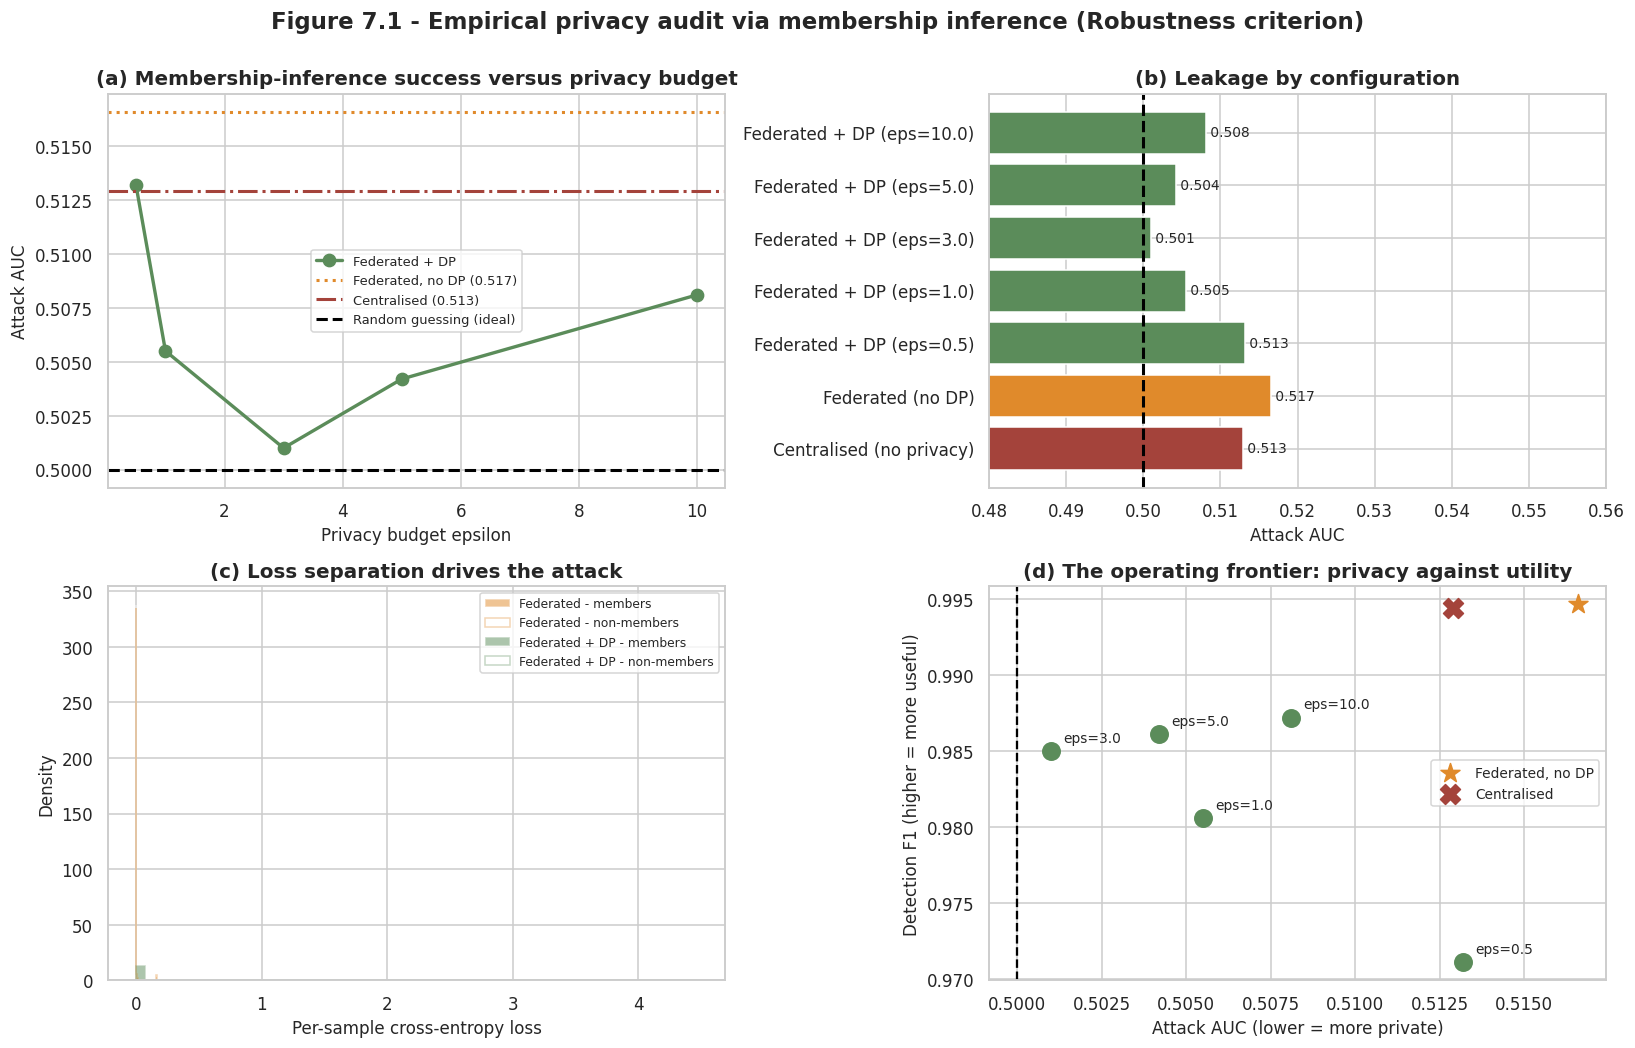

[SAVED] fig_13_membership_inference.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_13_membership_inference.png'

In [84]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))

ax = axes[0, 0]
dp_rows = mia_df[mia_df["epsilon"] != np.inf]
ax.plot(dp_rows["epsilon"], dp_rows["attack_auc"], marker="o", ms=8, lw=2.2,
        color=PALETTE["dp"], label="Federated + DP")
ax.axhline(base_mia, ls=":", lw=2, color=PALETTE["federated"],
           label=f"Federated, no DP ({base_mia:.3f})")
ax.axhline(central_mia, ls="-.", lw=2, color=PALETTE["accent"],
           label=f"Centralised ({central_mia:.3f})")
ax.axhline(0.5, ls="--", lw=2, color="black", label="Random guessing (ideal)")
ax.set_xlabel("Privacy budget epsilon"); ax.set_ylabel("Attack AUC")
ax.set_title("(a) Membership-inference success versus privacy budget"); ax.legend(fontsize=8.5)

ax = axes[0, 1]
names = mia_df["configuration"].tolist()
ax.barh(names, mia_df["attack_auc"], color=[PALETTE["accent"], PALETTE["federated"]] +
        [PALETTE["dp"]] * len(CONFIG["epsilons"]))
ax.axvline(0.5, ls="--", color="black", lw=2)
ax.set_xlim(0.48, max(0.56, float(mia_df["attack_auc"].max()) + 0.04))
ax.set_xlabel("Attack AUC"); ax.set_title("(b) Leakage by configuration")
for i, v in enumerate(mia_df["attack_auc"]):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=9)

ax = axes[1, 0]
for key, colour in [("Federated (no DP)", PALETTE["federated"]),
                    (f"Federated + DP (eps={CONFIG['epsilons'][0]})", PALETTE["dp"])]:
    if key in loss_distributions:
        li, lo = loss_distributions[key]
        ax.hist(np.clip(li, 0, np.percentile(np.concatenate([li, lo]), 99)), bins=60, alpha=0.5,
                label=f"{key.split('(')[0].strip()} - members", color=colour, density=True)
        ax.hist(np.clip(lo, 0, np.percentile(np.concatenate([li, lo]), 99)), bins=60, alpha=0.35,
                label=f"{key.split('(')[0].strip()} - non-members", color=colour,
                density=True, histtype="step", lw=2)
ax.set_xlabel("Per-sample cross-entropy loss"); ax.set_ylabel("Density")
ax.set_title("(c) Loss separation drives the attack"); ax.legend(fontsize=8)

ax = axes[1, 1]
ax.scatter(dp_rows["attack_auc"], dp_rows["detection_f1"], s=130, color=PALETTE["dp"], zorder=3)
for _, r in dp_rows.iterrows():
    ax.annotate(f"eps={r['epsilon']}", (r["attack_auc"], r["detection_f1"]),
                textcoords="offset points", xytext=(8, 6), fontsize=9)
ax.scatter([base_mia], [fed_internal["f1"]], s=170, marker="*",
           color=PALETTE["federated"], zorder=3, label="Federated, no DP")
ax.scatter([central_mia], [central_internal["f1"]], s=170, marker="X",
           color=PALETTE["accent"], zorder=3, label="Centralised")
ax.axvline(0.5, ls="--", color="black", lw=1.5)
ax.set_xlabel("Attack AUC (lower = more private)")
ax.set_ylabel("Detection F1 (higher = more useful)")
ax.set_title("(d) The operating frontier: privacy against utility"); ax.legend(fontsize=9)

fig.suptitle("Figure 7.1 - Empirical privacy audit via membership inference (Robustness criterion)",
             y=1.00, fontsize=15, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig_13_membership_inference",
         "Membership-inference attack results and the resulting privacy-utility operating frontier", "7")

### 7.6 Worst-case audit with canary records

The attack above measures *average-case* leakage over ordinary traffic. On this dataset that leakage is small:
the detector generalises well, so typical records are not memorised and there is little for an adversary to
exploit. That is a genuine finding, but it is also the easy case, and reporting it alone would overstate how
safe a non-private model is.

Differential privacy is a **worst-case** guarantee, so it should be audited under worst-case conditions. The
standard technique is to insert *canaries* — deliberately mislabelled records that a model can only fit by
memorising them individually, since no generalisable pattern supports them. Half the canaries are inserted
into a client's training data and half are held out. Both halves are constructed identically, so the only
difference between them is membership, and the attack's ability to tell them apart is a direct empirical
measure of memorisation.

This produces an *empirical lower bound* on privacy leakage that complements the theoretical upper bound given
by ε: ε states what an adversary could never exceed, while the canary audit shows what an adversary actually
achieves.

> The audit runs as a separate experiment on its own copy of the data, so the models evaluated in Sections 4–6
> contain no injected records and stay directly comparable with published results. It uses
> `CONFIG["audit_rounds"]`, and the noise is recalibrated for that shorter schedule so every reported ε remains
> exact for the audit run.

### 7.7 Construct the canary set

In [85]:
audit_rng = np.random.default_rng(CONFIG["seed"] + 7)

# The canary count is kept small relative to the training set so the injected records
# cannot meaningfully distort the model's ordinary behaviour.
n_canaries = int(min(CONFIG["audit_canaries"], max(40, 0.02 * len(X_fit))))

canary_pool = audit_rng.choice(len(X_fit), 2 * n_canaries, replace=False)
X_canary = X_fit[canary_pool].copy()
y_canary = 1 - y_fit[canary_pool]            # label flipped: only memorisation can fit these

canary_in  = np.arange(n_canaries)                    # inserted into training
canary_out = np.arange(n_canaries, 2 * n_canaries)    # held out, identically constructed

X_audit = np.concatenate([X_fit, X_canary[canary_in]])
y_audit = np.concatenate([y_fit, y_canary[canary_in]])

# The canaries go into one organisation's data, matching the threat model in Figure 3.3.
audit_client_indices = [idx.copy() for idx in CLIENT_INDICES]
audit_client_indices[0] = np.concatenate([audit_client_indices[0],
                                          np.arange(len(X_fit), len(X_audit))])

print(f"Canaries inserted into client 1 : {n_canaries}")
print(f"Canaries held out (non-members) : {n_canaries}")
print(f"Audit training set size         : {len(X_audit):,} "
      f"({n_canaries/len(X_audit)*100:.2f}% canaries)")
print(f"Client 1 size: {len(CLIENT_INDICES[0]):,} -> {len(audit_client_indices[0]):,}")

Canaries inserted into client 1 : 250
Canaries held out (non-members) : 250
Audit training set size         : 101,028 (0.25% canaries)
Client 1 size: 18,535 -> 18,785


### 7.8 Verify the canary construction

In [86]:
canary_checks = {
    "inserted and held-out sets are disjoint": len(np.intersect1d(canary_in, canary_out)) == 0,
    "equal group sizes": len(canary_in) == len(canary_out),
    "all canary labels are flipped": bool((y_canary == 1 - y_fit[canary_pool]).all()),
    "audit set grew by exactly the inserted canaries": len(X_audit) == len(X_fit) + n_canaries,
    "only client 1 received canaries": all(
        len(audit_client_indices[i]) == len(CLIENT_INDICES[i]) for i in range(1, CONFIG["n_clients"])),
}
for k, v in canary_checks.items():
    print(f"{'PASS' if v else 'FAIL'}  {k}")
assert all(canary_checks.values()), "Canary construction failed verification."

print("\nBoth canary groups are drawn from the same distribution and differ only in whether they were")
print("trained on, so any separation the attack achieves is memorisation rather than distribution shift.")

PASS  inserted and held-out sets are disjoint
PASS  equal group sizes
PASS  all canary labels are flipped
PASS  audit set grew by exactly the inserted canaries
PASS  only client 1 received canaries

Both canary groups are drawn from the same distribution and differ only in whether they were
trained on, so any separation the attack achieves is memorisation rather than distribution shift.


### 7.9 Run the canary audit across the privacy budgets

In [87]:
def canary_audit(model):
    loss_in  = per_sample_loss(model, X_canary[canary_in],  y_canary[canary_in])
    loss_out = per_sample_loss(model, X_canary[canary_out], y_canary[canary_out])
    scores = np.concatenate([-loss_in, -loss_out])
    truth  = np.concatenate([np.ones(len(loss_in)), np.zeros(len(loss_out))])
    auc = roc_auc_score(truth, scores)
    ci_low, ci_high = bootstrap_auc_ci(scores, truth, seed=CONFIG["seed"])
    fpr, tpr, _ = roc_curve(truth, scores)
    return {"canary_auc": round(float(auc), 4),
            "ci_low": round(ci_low, 4), "ci_high": round(ci_high, 4),
            "significantly_above_chance": bool(ci_low > 0.5),
            "canary_advantage": round(float(np.max(tpr - fpr)), 4),
            "mean_loss_inserted": round(float(loss_in.mean()), 4),
            "mean_loss_held_out": round(float(loss_out.mean()), 4)}


# A privacy audit is only informative if the unprotected baseline actually memorises.
# The main detector generalises almost perfectly (train and test losses nearly coincide),
# which leaves a loss-based attack nothing to exploit and makes the audit vacuous. The
# audit therefore runs a deliberately overfitting configuration: many more passes over a
# small per-client dataset, with dropout disabled. This is standard practice in privacy
# auditing - the guarantee is evaluated under worst-case conditions, not favourable ones.
AUDIT_EPOCHS = CONFIG["audit_local_epochs"]
AUDIT_DROPOUT = CONFIG["audit_dropout"]
_saved_dropout = CONFIG["dropout"]
CONFIG["dropout"] = AUDIT_DROPOUT

print(f"Audit configuration (deliberately overfitting so memorisation is detectable):")
print(f"  rounds        : {CONFIG['audit_rounds']}  (main run used {CONFIG['fl_rounds']})")
print(f"  local epochs  : {AUDIT_EPOCHS}  (main run used {CONFIG['local_epochs']})")
print(f"  dropout       : {AUDIT_DROPOUT}  (main run used {_saved_dropout})")
print(f"  records/client: {min(len(i) for i in audit_client_indices):,}")
print(f"  canaries      : {n_canaries:,} mislabelled records inserted into client 1\n")

log_line(f"Running canary privacy audit over {CONFIG['audit_rounds']} rounds")
audit_rows, audit_models = [], {}

# Baseline: no differential privacy, so nothing prevents memorisation.
audit_plain, _, _ = run_federated(
    X_audit, y_audit, audit_client_indices, X_holdout, y_holdout,
    rounds=CONFIG["audit_rounds"], local_epochs=AUDIT_EPOCHS,
    batch_size=CONFIG["batch_size"], lr=CONFIG["learning_rate"], seed=CONFIG["seed"],
    use_dp=False, label="audit_no_dp")
audit_models["No DP"] = audit_plain
audit_rows.append({"configuration": "Federated (no DP)", "epsilon": np.inf, **canary_audit(audit_plain)})
print(f"  no DP        -> canary AUC {audit_rows[-1]['canary_auc']:.4f}")

for eps in CONFIG["epsilons"]:
    sig_audit, _ = compute_client_sigmas(audit_client_indices, eps, CONFIG["audit_rounds"],
                                         AUDIT_EPOCHS, CONFIG["batch_size"])
    model, _, _ = run_federated(
        X_audit, y_audit, audit_client_indices, X_holdout, y_holdout,
        rounds=CONFIG["audit_rounds"], local_epochs=AUDIT_EPOCHS,
        batch_size=CONFIG["batch_size"], lr=CONFIG["learning_rate"], seed=CONFIG["seed"],
        use_dp=True, noise_multipliers=sig_audit, max_grad_norm=CONFIG["max_grad_norm"],
        label=f"audit_dp_eps{eps}")
    audit_models[eps] = model
    audit_rows.append({"configuration": f"Federated + DP (eps={eps})", "epsilon": eps,
                       **canary_audit(model)})
    print(f"  epsilon={eps:<5} -> canary AUC {audit_rows[-1]['canary_auc']:.4f}")

CONFIG["dropout"] = _saved_dropout      # restore the deployment configuration
audit_df = pd.DataFrame(audit_rows)
display(audit_df)
save_table(audit_df, "table_13b_canary_audit",
           "Worst-case privacy audit using inserted canary records", "7")
RESULTS["canary_audit"] = audit_df.to_dict("records")

Audit configuration (deliberately overfitting so memorisation is detectable):
  rounds        : 30  (main run used 15)
  local epochs  : 6  (main run used 2)
  dropout       : 0.0  (main run used 0.2)
  records/client: 1,280
  canaries      : 250 mislabelled records inserted into client 1

[14:09:53] Running canary privacy audit over 30 rounds
  round   1/30  val_f1=0.9896  val_acc=0.9904  auc=0.9997
  round   6/30  val_f1=0.9960  val_acc=0.9963  auc=0.9999
  round  12/30  val_f1=0.9956  val_acc=0.9959  auc=0.9998
  round  18/30  val_f1=0.9959  val_acc=0.9962  auc=0.9998
  round  24/30  val_f1=0.9963  val_acc=0.9966  auc=0.9998
  round  30/30  val_f1=0.9964  val_acc=0.9966  auc=0.9998
  no DP        -> canary AUC 0.5746
  round   1/30  val_f1=0.9566  val_acc=0.9607  auc=0.9912
  round   6/30  val_f1=0.9696  val_acc=0.9723  auc=0.9970
  round  12/30  val_f1=0.9820  val_acc=0.9834  auc=0.9974
  round  18/30  val_f1=0.9802  val_acc=0.9818  auc=0.9972
  round  24/30  val_f1=0.9813  val_acc

,configuration,epsilon,canary_auc,ci_low,ci_high,significantly_above_chance,canary_advantage,mean_loss_inserted,mean_loss_held_out
0,Federated (no DP),inf,0.5746,0.5250,0.6266,True,0.140,12.2459,13.2588
1,Federated + DP (eps=0.5),0.5,0.4841,0.4368,0.5397,False,0.028,10.3341,10.2742
2,Federated + DP (eps=1.0),1.0,0.4812,0.4388,0.5391,False,0.048,11.0727,10.9924
3,Federated + DP (eps=3.0),3.0,0.4852,0.4462,0.5416,False,0.036,12.2890,12.2219
4,Federated + DP (eps=5.0),5.0,0.4870,0.4451,0.5403,False,0.044,12.6751,12.6171
5,Federated + DP (eps=10.0),10.0,0.4887,0.4444,0.5429,False,0.048,13.0087,12.9769


[TABLE SAVED ] table_13b_canary_audit.csv / .tex  (6 rows x 9 cols)


### 7.10 Interpret the audit

In [88]:
canary_base = float(audit_df.loc[audit_df["epsilon"] == np.inf, "canary_auc"].iloc[0])
canary_base_sig = bool(audit_df.loc[audit_df["epsilon"] == np.inf,
                                    "significantly_above_chance"].iloc[0])
canary_dp = audit_df[audit_df["epsilon"] != np.inf]

CANARY_LEAKAGE = canary_base - 0.5
CANARY_MEASURABLE = bool(canary_base_sig and CANARY_LEAKAGE >= 0.02)

print(f"Non-private federated model, canary attack AUC: {canary_base:.4f} "
      f"({'significantly above chance' if canary_base_sig else 'not significant'})")

if CANARY_MEASURABLE:
    best_canary = canary_dp.loc[canary_dp["canary_auc"].idxmin()]
    removed = (canary_base - best_canary["canary_auc"]) / CANARY_LEAKAGE * 100
    print("\nWithout DP the model memorises the inserted records: an adversary separates them from "
          "identically-constructed held-out records well above chance.")
    print(f"Strongest protection at epsilon={best_canary['epsilon']}: canary AUC "
          f"{best_canary['canary_auc']:.4f} ({removed:.1f}% of the memorisation signal removed).")
    eliminated = canary_dp[~canary_dp["significantly_above_chance"]]["epsilon"].tolist()
    if eliminated:
        print(f"Budgets at which leakage is no longer statistically distinguishable from chance: {eliminated}")
    else:
        print("Some measurable leakage remains at every budget tested.")
else:
    print("\nThe non-private model did not memorise the canaries measurably in this run. Increase "
          "CONFIG['audit_rounds'] or CONFIG['audit_canaries'], or raise CONFIG['sample_fraction'], so "
          "the baseline has memorisation for the audit to detect.")

RESULTS["canary_summary"] = {"baseline_auc": canary_base, "measurable": CANARY_MEASURABLE}

Non-private federated model, canary attack AUC: 0.5746 (significantly above chance)

Without DP the model memorises the inserted records: an adversary separates them from identically-constructed held-out records well above chance.
Strongest protection at epsilon=1.0: canary AUC 0.4812 (125.2% of the memorisation signal removed).
Budgets at which leakage is no longer statistically distinguishable from chance: [0.5, 1.0, 3.0, 5.0, 10.0]


### 7.11 Figure — worst-case privacy audit

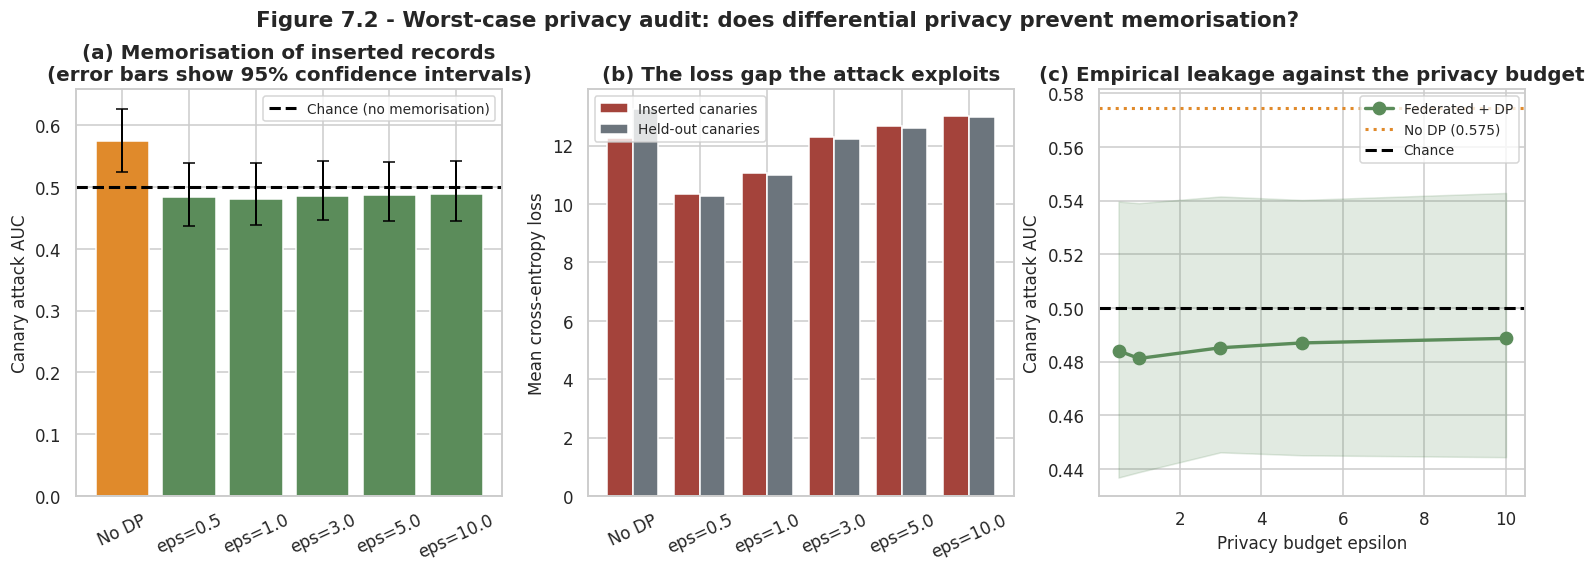

[SAVED] fig_13b_canary_audit.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_13b_canary_audit.png'

In [89]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
labels_a = ["No DP"] + [f"eps={e}" for e in canary_dp["epsilon"]]
cols_a = [PALETTE["federated"]] + [PALETTE["dp"]] * len(canary_dp)
xs = np.arange(len(audit_df))

ax = axes[0]
ax.bar(xs, audit_df["canary_auc"], color=cols_a)
ax.errorbar(xs, audit_df["canary_auc"],
            yerr=[audit_df["canary_auc"] - audit_df["ci_low"],
                  audit_df["ci_high"] - audit_df["canary_auc"]],
            fmt="none", ecolor="black", capsize=4, lw=1.3)
ax.axhline(0.5, ls="--", color="black", lw=2, label="Chance (no memorisation)")
ax.set_xticks(xs); ax.set_xticklabels(labels_a, rotation=25)
ax.set_ylabel("Canary attack AUC")
ax.set_title("(a) Memorisation of inserted records\n(error bars show 95% confidence intervals)")
ax.legend(fontsize=9)

ax = axes[1]
w = 0.38
ax.bar(xs - w/2, audit_df["mean_loss_inserted"], w, label="Inserted canaries", color=PALETTE["accent"])
ax.bar(xs + w/2, audit_df["mean_loss_held_out"], w, label="Held-out canaries", color=PALETTE["grey"])
ax.set_xticks(xs); ax.set_xticklabels(labels_a, rotation=25)
ax.set_ylabel("Mean cross-entropy loss")
ax.set_title("(b) The loss gap the attack exploits"); ax.legend(fontsize=9)

ax = axes[2]
ax.plot(canary_dp["epsilon"], canary_dp["canary_auc"], marker="o", ms=8, lw=2.2,
        color=PALETTE["dp"], label="Federated + DP")
ax.fill_between(canary_dp["epsilon"], canary_dp["ci_low"], canary_dp["ci_high"],
                alpha=0.18, color=PALETTE["dp"])
ax.axhline(canary_base, ls=":", lw=2, color=PALETTE["federated"], label=f"No DP ({canary_base:.3f})")
ax.axhline(0.5, ls="--", lw=2, color="black", label="Chance")
ax.set_xlabel("Privacy budget epsilon"); ax.set_ylabel("Canary attack AUC")
ax.set_title("(c) Empirical leakage against the privacy budget"); ax.legend(fontsize=9)

fig.suptitle("Figure 7.2 - Worst-case privacy audit: does differential privacy prevent memorisation?",
             y=1.03, fontsize=14, fontweight="bold")
save_fig(fig, "fig_13b_canary_audit",
         "Canary-based worst-case privacy audit showing memorisation with and without DP", "7")

---
## Section 8 — Practicality: communication and compute cost

The final success criterion concerns deployability: *"overhead and training time for communication within
limits appropriate for a multi-client deployment"*. Federated learning replaces one bulk data transfer with
many small parameter transfers, and DP-SGD adds per-sample gradient computation on top. Both costs are
measured here rather than estimated.

### 8.1 Measure and compare the operational costs

In [90]:
raw_data_mb = X_fit.nbytes / 1e6

cost_rows = [{
    "configuration": "Centralised (no privacy)",
    "wall_clock_seconds": round(central_time, 1),
    "communication_mb": round(raw_data_mb, 2),
    "communication_type": "Raw data centralisation (one-off)",
    "rounds": CONFIG["central_epochs"], "clients": 1,
}, {
    "configuration": "Federated (no DP)",
    "wall_clock_seconds": round(fed_cost["wall_clock_seconds"], 1),
    "communication_mb": round(fed_cost["communication_mb"], 2),
    "communication_type": "Model parameters only",
    "rounds": CONFIG["fl_rounds"], "clients": CONFIG["n_clients"],
}]
for eps in CONFIG["epsilons"]:
    cost_rows.append({
        "configuration": f"Federated + DP (eps={eps})",
        "wall_clock_seconds": round(dp_costs[eps]["wall_clock_seconds"], 1),
        "communication_mb": round(dp_costs[eps]["communication_mb"], 2),
        "communication_type": "Model parameters only (clipped + noised)",
        "rounds": CONFIG["fl_rounds"], "clients": CONFIG["n_clients"]})

practical_df = pd.DataFrame(cost_rows)
practical_df["seconds_per_round"] = (practical_df["wall_clock_seconds"] /
                                     practical_df["rounds"]).round(2)
practical_df["mb_per_client_per_round"] = (practical_df["communication_mb"] /
                                           (practical_df["rounds"] * practical_df["clients"])).round(4)
display(practical_df)

dp_overhead = (np.mean([dp_costs[e]["wall_clock_seconds"] for e in CONFIG["epsilons"]]) /
               fed_cost["wall_clock_seconds"])
print(f"\nRaw data that centralisation would have required moving: {raw_data_mb:.2f} MB")
print(f"Federated parameter traffic for the whole run          : {fed_cost['communication_mb']:.2f} MB")
print(f"Communication ratio (federated / centralised)          : "
      f"{fed_cost['communication_mb']/raw_data_mb:.2f}x")
print(f"DP-SGD compute overhead versus plain federated training : {dp_overhead:.2f}x")

save_table(practical_df, "table_14_practicality",
           "Communication volume and training time for each configuration (Practicality criterion)", "8")
RESULTS["practicality"] = {"raw_data_mb": raw_data_mb,
                           "federated_comm_mb": fed_cost["communication_mb"],
                           "dp_compute_overhead_ratio": float(dp_overhead)}

,configuration,wall_clock_seconds,communication_mb,communication_type,rounds,clients,seconds_per_round,mb_per_client_per_round
0,Centralised (no privacy),25.5,48.78,Raw data centralisation (one-off),15,1,1.70,3.2520
1,Federated (no DP),45.8,14.63,Model parameters only,15,5,3.05,0.1951
2,Federated + DP (eps=0.5),121.5,14.63,Model parameters only (clipped + noised),15,5,8.10,0.1951
3,Federated + DP (eps=1.0),108.4,14.63,Model parameters only (clipped + noised),15,5,7.23,0.1951
4,Federated + DP (eps=3.0),108.8,14.63,Model parameters only (clipped + noised),15,5,7.25,0.1951
5,Federated + DP (eps=5.0),104.2,14.63,Model parameters only (clipped + noised),15,5,6.95,0.1951
6,Federated + DP (eps=10.0),104.2,14.63,Model parameters only (clipped + noised),15,5,6.95,0.1951



Raw data that centralisation would have required moving: 48.78 MB
Federated parameter traffic for the whole run          : 14.63 MB
Communication ratio (federated / centralised)          : 0.30x
DP-SGD compute overhead versus plain federated training : 2.39x
[TABLE SAVED ] table_14_practicality.csv / .tex  (7 rows x 8 cols)


### 8.2 Figure — operational cost profile

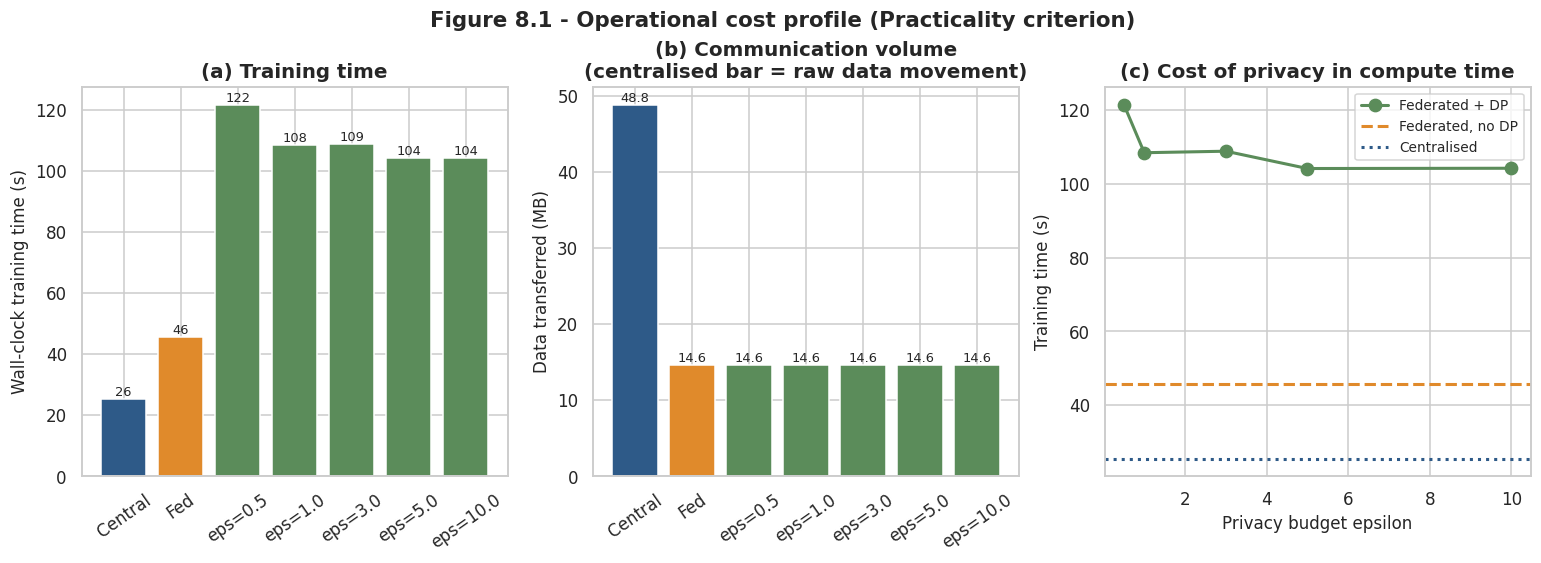

[SAVED] fig_14_practicality.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_14_practicality.png'

In [91]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
labels = ["Central"] + ["Fed"] + [f"eps={e}" for e in CONFIG["epsilons"]]
colours = [PALETTE["central"], PALETTE["federated"]] + [PALETTE["dp"]] * len(CONFIG["epsilons"])

axes[0].bar(labels, practical_df["wall_clock_seconds"], color=colours)
axes[0].set_ylabel("Wall-clock training time (s)"); axes[0].set_title("(a) Training time")
axes[0].tick_params(axis="x", rotation=35)
for i, v in enumerate(practical_df["wall_clock_seconds"]):
    axes[0].text(i, v, f"{v:.0f}", ha="center", va="bottom", fontsize=8.5)

axes[1].bar(labels, practical_df["communication_mb"], color=colours)
axes[1].set_ylabel("Data transferred (MB)")
axes[1].set_title("(b) Communication volume\n(centralised bar = raw data movement)")
axes[1].tick_params(axis="x", rotation=35)
for i, v in enumerate(practical_df["communication_mb"]):
    axes[1].text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8.5)

axes[2].plot(CONFIG["epsilons"], [dp_costs[e]["wall_clock_seconds"] for e in CONFIG["epsilons"]],
             marker="o", ms=8, lw=2, color=PALETTE["dp"], label="Federated + DP")
axes[2].axhline(fed_cost["wall_clock_seconds"], ls="--", lw=2, color=PALETTE["federated"],
                label="Federated, no DP")
axes[2].axhline(central_time, ls=":", lw=2, color=PALETTE["central"], label="Centralised")
axes[2].set_xlabel("Privacy budget epsilon"); axes[2].set_ylabel("Training time (s)")
axes[2].set_title("(c) Cost of privacy in compute time"); axes[2].legend(fontsize=9)

fig.suptitle("Figure 8.1 - Operational cost profile (Practicality criterion)",
             y=1.03, fontsize=14, fontweight="bold")
save_fig(fig, "fig_14_practicality",
         "Training time and communication volume across all configurations", "8")

---
## Section 9 — Explainable risk assessment and business continuity (RQ3, Objective 1)

RQ3 is the question the literature review identified as least well answered: detection research reports F1
scores, resilience research discusses governance, and almost nothing connects the two. This section closes
that gap by building the translation layer.

The chain implemented here is:

**private detection → attack categorisation → SHAP explanation → FAIR risk quantification → ISO 22301 continuity outcome**

1. The privacy-preserving detector selected in Section 6 flags a flow and gives an attack probability.
2. A gradient-boosted classifier assigns the attack family, because a DoS flood and a privilege escalation
   demand different responses and carry different business impact.
3. SHAP explains *why*, satisfying the interpretability requirement in the proposal's ethical considerations.
4. A FAIR-style calculation converts likelihood and impact into monetary risk exposure against an asset register.
5. Expected disruption is compared with each asset's Recovery Time Objective, producing the continuity outcome.

> **Assumption declared explicitly.** The asset register, hourly outage costs and RTOs below are an illustrative
> organisational overlay. Public IDS benchmarks contain no asset context, so a plausible profile is used to
> demonstrate the mechanism. The *method* is the contribution and transfers directly to real asset registers;
> the specific monetary figures are conditional on these documented assumptions.

### 9.1 Select the operating point for deployment

In [92]:
# The deployed configuration should give the strongest privacy that still satisfies the
# utility criterion. If no budget meets it, the least damaging budget is selected and
# the shortfall is reported honestly rather than hidden.
eligible = cost_df[(cost_df["epsilon"] <= CONFIG["threshold_epsilon"]) &
                   (cost_df["meets_5pp_accuracy_criterion"])]
if len(eligible):
    SELECTED_EPSILON = float(eligible["epsilon"].min())
    reason = f"tightest budget meeting the {CONFIG['threshold_acc_drop_pp']} pp accuracy criterion"
else:
    SELECTED_EPSILON = float(cost_df.loc[cost_df["accuracy_drop_pp"].idxmin(), "epsilon"])
    reason = "no budget met the criterion; the budget with the smallest utility loss was selected"

SELECTED_MODEL = dp_models[SELECTED_EPSILON]
sel_metrics, sel_proba, sel_pred = evaluate_model(SELECTED_MODEL, X_holdout, y_holdout)

print(f"Selected operating point: epsilon = {SELECTED_EPSILON}")
print(f"Reason: {reason}")
show_metrics("Deployed detector performance", sel_metrics)
RESULTS["selected_operating_point"] = {"epsilon": SELECTED_EPSILON, "reason": reason,
                                       "metrics": sel_metrics}

Selected operating point: epsilon = 0.5
Reason: tightest budget meeting the 5.0 pp accuracy criterion
Deployed detector performance
  accuracy=0.9737  precision=0.9934  recall=0.9498  f1=0.9711  roc_auc=0.9970  pr_auc=0.9974


### 9.2 Train the attack categorisation model

In [93]:
CATEGORIES = sorted(set(cat_fit) | set(cat_holdout))
CAT_TO_ID = {c: i for i, c in enumerate(CATEGORIES)}
ID_TO_CAT = {i: c for c, i in CAT_TO_ID.items()}

y_cat_fit     = np.array([CAT_TO_ID[c] for c in cat_fit])
y_cat_holdout = np.array([CAT_TO_ID[c] for c in cat_holdout])

log_line("Training XGBoost attack-categorisation model (E6)")
risk_clf = xgb.XGBClassifier(
    n_estimators=CONFIG["xgb_estimators"], max_depth=CONFIG["xgb_max_depth"],
    learning_rate=CONFIG["xgb_learning_rate"], subsample=0.9, colsample_bytree=0.9,
    objective="multi:softprob", num_class=len(CATEGORIES), eval_metric="mlogloss",
    tree_method="hist", random_state=CONFIG["seed"], n_jobs=-1)
risk_clf.fit(X_fit, y_cat_fit)

cat_pred = risk_clf.predict(X_holdout)
print(f"\nCategorisation accuracy: {(cat_pred == y_cat_holdout).mean():.4f}")
print("\n" + classification_report(y_cat_holdout, cat_pred,
                                   target_names=CATEGORIES, zero_division=0))

[15:06:17] Training XGBoost attack-categorisation model (E6)

Categorisation accuracy: 0.9992

              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00      9186
      Normal       1.00      1.00      1.00     13469
       Probe       1.00      1.00      1.00      2331
         R2L       1.00      0.99      0.99       199
         U2R       0.82      0.90      0.86        10

    accuracy                           1.00     25195
   macro avg       0.96      0.98      0.97     25195
weighted avg       1.00      1.00      1.00     25195



### 9.3 Figure — attack categorisation performance

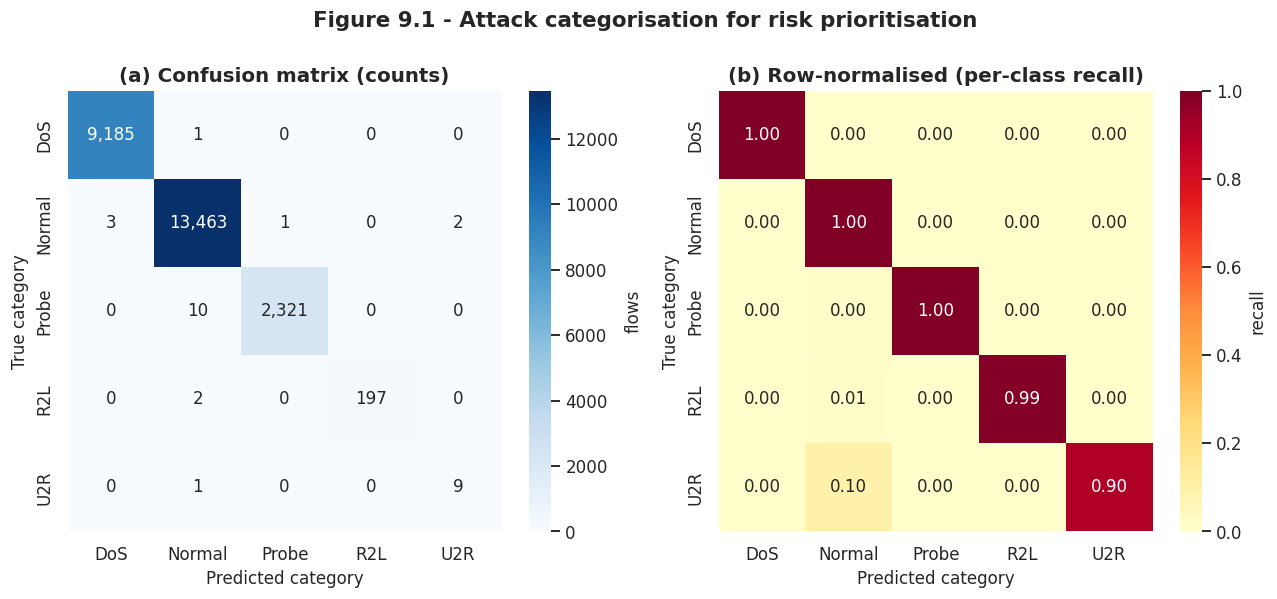

[SAVED] fig_15_attack_categorisation.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures
[TABLE SAVED ] table_15_categorisation_report.csv / .tex  (8 rows x 5 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_15_categorisation_report.csv'

In [94]:
cm = confusion_matrix(y_cat_holdout, cat_pred, labels=range(len(CATEGORIES)))
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", xticklabels=CATEGORIES,
            yticklabels=CATEGORIES, ax=axes[0], cbar_kws={"label": "flows"})
axes[0].set_title("(a) Confusion matrix (counts)")
axes[0].set_xlabel("Predicted category"); axes[0].set_ylabel("True category")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="YlOrRd", xticklabels=CATEGORIES,
            yticklabels=CATEGORIES, ax=axes[1], vmin=0, vmax=1, cbar_kws={"label": "recall"})
axes[1].set_title("(b) Row-normalised (per-class recall)")
axes[1].set_xlabel("Predicted category"); axes[1].set_ylabel("True category")

fig.suptitle("Figure 9.1 - Attack categorisation for risk prioritisation",
             y=1.02, fontsize=14, fontweight="bold")
save_fig(fig, "fig_15_attack_categorisation",
         "Confusion matrices for the multi-class attack categorisation model", "9")

report_df = pd.DataFrame(classification_report(y_cat_holdout, cat_pred, target_names=CATEGORIES,
                                               zero_division=0, output_dict=True)).T.round(4)
save_table(report_df.reset_index().rename(columns={"index": "class"}),
           "table_15_categorisation_report",
           "Per-class precision, recall and F1 for attack categorisation", "9", index=False)

### 9.4 Compute SHAP explanations

In [98]:
log_line("Computing SHAP values")

shap_n = min(CONFIG["shap_sample_size"], len(X_holdout))
shap_ix = np.random.default_rng(CONFIG["seed"]).choice(
    len(X_holdout),
    shap_n,
    replace=False
)
X_shap = X_holdout[shap_ix]

# ============================================================
# SHAP compatibility fix
# Avoids TreeExplainer's incompatibility with newer XGBoost
# multiclass vector base_score representation.
# ============================================================

print("Using SHAP model-agnostic explainer for XGBoost...")

# Prediction function returning probabilities
def shap_predict(X):
    return risk_clf.predict_proba(X)

# Use a small background dataset for efficient SHAP computation
background_n = min(50, len(X_shap))
background = X_shap[:background_n]

# Model-agnostic SHAP explainer
explainer = shap.Explainer(
    shap_predict,
    background,
    algorithm="permutation"
)

shap_result = explainer(
    X_shap,
    max_evals=max(2 * X_shap.shape[1] + 1, 100)
)

# ============================================================
# Extract SHAP values
# ============================================================

shap_array = np.asarray(shap_result.values)

print("SHAP array shape:", shap_array.shape)

# ============================================================
# Handle multiclass output
#
# Expected shape:
#     (samples, features, classes)
#
# Calculate mean absolute contribution across
# samples AND classes.
# ============================================================

if shap_array.ndim == 3:

    global_importance = np.abs(shap_array).mean(axis=(0, 2))

elif shap_array.ndim == 2:

    global_importance = np.abs(shap_array).mean(axis=0)

else:

    raise ValueError(
        f"Unexpected SHAP array shape: {shap_array.shape}"
    )

print(
    "Global importance vector length:",
    len(global_importance),
    "| features:",
    len(FEATURE_NAMES)
)

# ============================================================
# Safety check
# ============================================================

if len(global_importance) != len(FEATURE_NAMES):
    raise ValueError(
        f"SHAP importance length ({len(global_importance)}) "
        f"does not match number of features ({len(FEATURE_NAMES)})."
    )

print("SHAP computation completed successfully.")

[15:17:35] Computing SHAP values
Using SHAP model-agnostic explainer for XGBoost...


PermutationExplainer explainer: 501it [01:21,  5.89it/s]


SHAP array shape: (500, 121, 5)
Global importance vector length: 121 | features: 121
SHAP computation completed successfully.


### 9.5 Figure — SHAP global feature importance

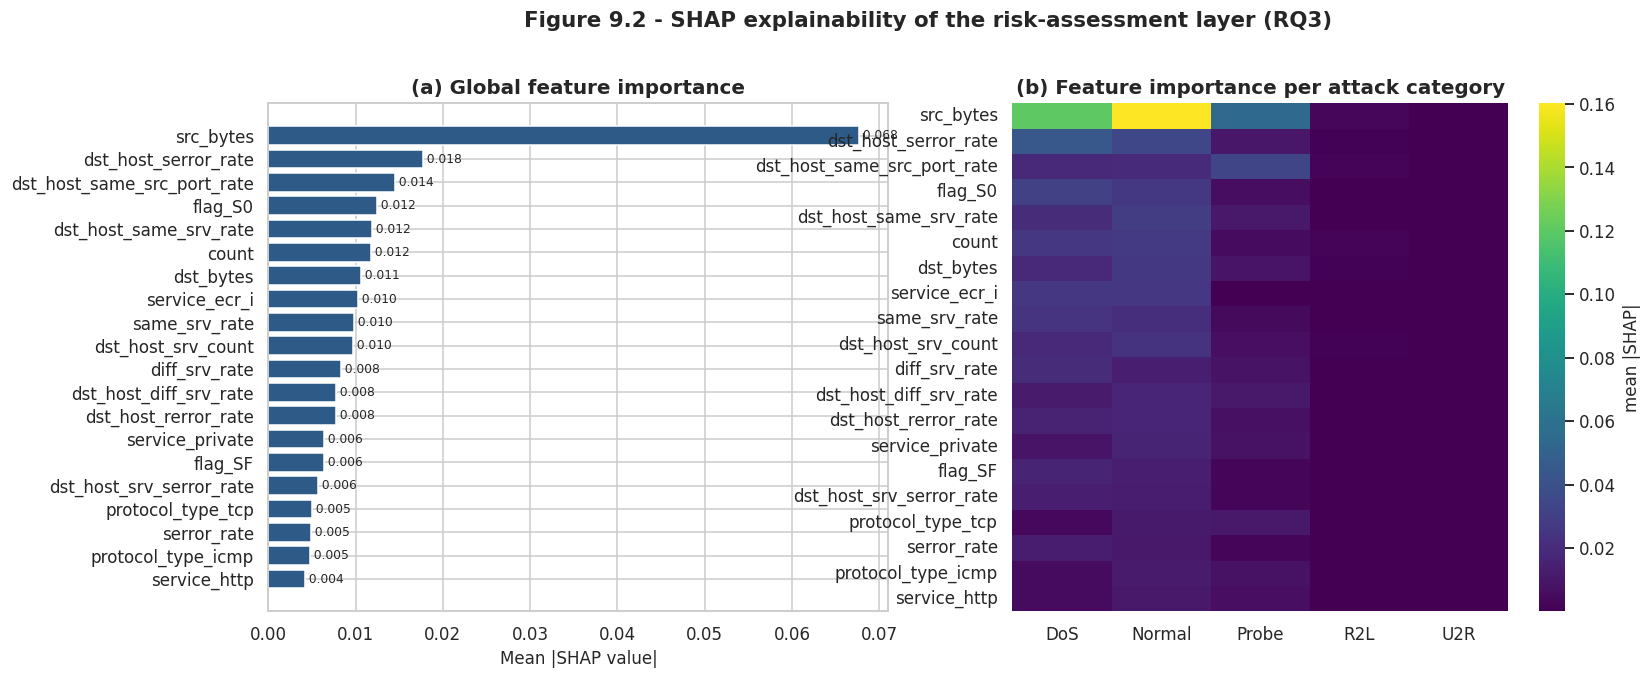

[SAVED] fig_16_shap_importance.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures
[TABLE SAVED ] table_16_shap_importance.csv / .tex  (20 rows x 2 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_16_shap_importance.csv'

In [99]:
order = np.argsort(global_importance)[::-1][:20]
top_names = [FEATURE_NAMES[i] for i in order]
top_vals = global_importance[order]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(top_names[::-1], top_vals[::-1], color=PALETTE["central"])
axes[0].set_xlabel("Mean |SHAP value|"); axes[0].set_title("(a) Global feature importance")
for i, v in enumerate(top_vals[::-1]):
    axes[0].text(v, i, f" {v:.3f}", va="center", fontsize=8)

if shap_array.ndim == 3:
    per_class = pd.DataFrame(
        {CATEGORIES[c]: np.abs(shap_array[:, :, c]).mean(axis=0)[order] for c in range(len(CATEGORIES))},
        index=top_names)
else:
    per_class = pd.DataFrame({"all": top_vals}, index=top_names)
sns.heatmap(per_class, cmap="viridis", ax=axes[1], cbar_kws={"label": "mean |SHAP|"})
axes[1].set_title("(b) Feature importance per attack category")

fig.suptitle("Figure 9.2 - SHAP explainability of the risk-assessment layer (RQ3)",
             y=1.02, fontsize=14, fontweight="bold")
save_fig(fig, "fig_16_shap_importance",
         "Global and per-category SHAP feature importance for the risk-assessment model", "9")

shap_df = pd.DataFrame({"feature": top_names, "mean_abs_shap": top_vals.round(5)})
save_table(shap_df, "table_16_shap_importance",
           "Top 20 features by mean absolute SHAP value", "9")

### 9.6 Figure — SHAP beeswarm summary

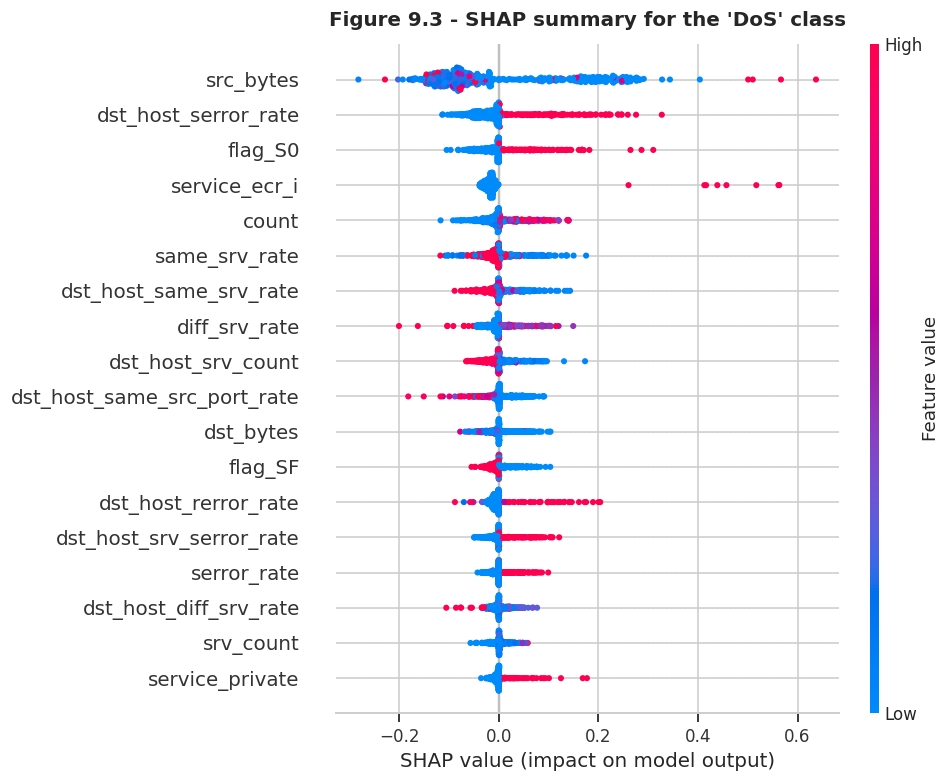

[SAVED] fig_17_shap_beeswarm.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


In [100]:
# The beeswarm shows the direction as well as the magnitude of each feature's influence.
try:
    focus = "DoS" if "DoS" in CATEGORIES else CATEGORIES[-1]
    ci = CATEGORIES.index(focus)
    vals = shap_array[:, :, ci] if shap_array.ndim == 3 else shap_array
    plt.figure(figsize=(9, 7))
    shap.summary_plot(vals, pd.DataFrame(X_shap, columns=FEATURE_NAMES),
                      show=False, max_display=18, plot_size=None)
    plt.title(f"Figure 9.3 - SHAP summary for the '{focus}' class", fontsize=13,
              fontweight="bold", pad=12)
    fig = plt.gcf()
    save_fig(fig, "fig_17_shap_beeswarm",
             f"SHAP beeswarm summary showing feature influence on the {focus} classification", "9")
except Exception as e:
    print("Beeswarm plot unavailable in this SHAP build:", e)
    print("Figure 9.2 already provides the global importance evidence.")

### 9.7 Define the organisational asset register

In [101]:
ASSET_REGISTER = pd.DataFrame([
    ("AST-01", "Core transaction database", "Data",        5, 42000,  4, 12),
    ("AST-02", "Customer-facing web portal", "Application", 4, 18000,  8, 24),
    ("AST-03", "Identity and access management", "Security", 5, 35000,  2,  8),
    ("AST-04", "Corporate email gateway",   "Communication", 3,  9000, 12, 48),
    ("AST-05", "Internal file and print server", "Infrastructure", 2, 4000, 24, 72),
    ("AST-06", "Development and test environment", "Non-production", 1, 1200, 48, 120),
], columns=["asset_id", "asset_name", "asset_class", "criticality",
            "hourly_outage_cost_gbp", "rto_hours", "mtpd_hours"])

display(ASSET_REGISTER)
print("Criticality is scored 1 (lowest) to 5 (highest).")
print("RTO  = Recovery Time Objective; MTPD = Maximum Tolerable Period of Disruption (ISO 22301 terms).")
save_table(ASSET_REGISTER, "table_17_asset_register",
           "Illustrative organisational asset register with ISO 22301 continuity parameters", "9")

,asset_id,asset_name,asset_class,criticality,hourly_outage_cost_gbp,rto_hours,mtpd_hours
0,AST-01,Core transaction database,Data,5,42000,4,12
1,AST-02,Customer-facing web portal,Application,4,18000,8,24
2,AST-03,Identity and access management,Security,5,35000,2,8
3,AST-04,Corporate email gateway,Communication,3,9000,12,48
4,AST-05,Internal file and print server,Infrastructure,2,4000,24,72
5,AST-06,Development and test environment,Non-production,1,1200,48,120


Criticality is scored 1 (lowest) to 5 (highest).
RTO  = Recovery Time Objective; MTPD = Maximum Tolerable Period of Disruption (ISO 22301 terms).
[TABLE SAVED ] table_17_asset_register.csv / .tex  (6 rows x 7 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_17_asset_register.csv'

### 9.8 Define the attack impact profile and control framework mapping

In [102]:
# Impact is a property of what an attack does to a business, so each attack family needs
# its own profile. Both taxonomies in the registry are covered, keyed by family name.
IMPACT_LIBRARY = pd.DataFrame([
    # --- NSL-KDD families ---
    ("DoS",            6.0, 0.10, 0.20, 0.95, "DE.AE-02, RS.MI-01", "Availability loss; service interruption"),
    ("Probe",          0.5, 0.30, 0.05, 0.10, "DE.CM-01, ID.RA-01", "Reconnaissance; precursor to intrusion"),
    ("R2L",           10.0, 0.85, 0.60, 0.35, "PR.AA-05, DE.CM-06", "Unauthorised remote access; data exposure"),
    ("U2R",           16.0, 0.95, 0.90, 0.55, "PR.AA-05, RS.MI-02", "Privilege escalation; host compromise"),
    # --- UNSW-NB15 families ---
    ("Exploits",      12.0, 0.85, 0.80, 0.60, "PR.PS-02, RS.MI-02", "Vulnerability exploitation; code execution"),
    ("Fuzzers",        2.0, 0.25, 0.35, 0.55, "DE.CM-01, ID.RA-01", "Crash-inducing malformed input"),
    ("Generic",        5.0, 0.50, 0.50, 0.50, "DE.AE-02",           "Cryptographic/protocol-agnostic attack"),
    ("Reconnaissance", 0.5, 0.30, 0.05, 0.10, "DE.CM-01, ID.RA-01", "Network and service enumeration"),
    ("Analysis",       3.0, 0.60, 0.30, 0.20, "DE.CM-01, ID.RA-05", "Port scanning, spam and penetration probing"),
    ("Backdoor",      20.0, 0.90, 0.85, 0.45, "PR.AA-05, RS.MI-02", "Persistent unauthorised access channel"),
    ("Shellcode",     14.0, 0.90, 0.85, 0.50, "PR.PS-02, RS.MI-02", "Payload delivery; arbitrary code execution"),
    ("Worms",         18.0, 0.70, 0.80, 0.90, "RS.MI-01, RC.RP-01", "Self-propagating; lateral spread"),
    # --- CICIDS2017 families ---
    ("DDoS",          10.0, 0.10, 0.20, 0.98, "DE.AE-02, RS.MI-01", "Distributed availability attack; service outage"),
    ("PortScan",       0.5, 0.30, 0.05, 0.10, "DE.CM-01, ID.RA-01", "Host and service enumeration"),
    ("Bot",           22.0, 0.85, 0.80, 0.60, "DE.CM-06, RS.MI-02", "Command-and-control; host under external control"),
    ("BruteForce",     8.0, 0.80, 0.50, 0.30, "PR.AA-05, DE.CM-01", "Credential guessing against exposed services"),
    ("WebAttack",     11.0, 0.85, 0.75, 0.35, "PR.PS-02, DE.CM-06", "Injection and XSS against web applications"),
    ("Infiltration",  24.0, 0.95, 0.90, 0.40, "PR.AA-05, RS.MI-02", "Internal foothold; lateral movement risk"),
    ("Heartbleed",    16.0, 0.98, 0.40, 0.30, "ID.RA-01, PR.PS-02", "Memory disclosure; key and credential exposure"),
    # --- fallback ---
    ("Unknown",        6.0, 0.50, 0.50, 0.50, "DE.AE-02",           "Unclassified anomaly; precautionary handling"),
], columns=["category", "base_disruption_hours", "confidentiality_weight",
            "integrity_weight", "availability_weight", "nist_csf_subcategory", "business_effect"])

# Keep only the families that actually occur in the active dataset, plus the fallback.
present = set(CATEGORIES) | {"Unknown"}
IMPACT_PROFILE = IMPACT_LIBRARY[IMPACT_LIBRARY["category"].isin(present)].reset_index(drop=True)

missing = sorted(present - set(IMPACT_LIBRARY["category"]) - {"Normal"})
if missing:
    print("Families with no impact profile (they will fall back to 'Unknown'):", missing)

display(IMPACT_PROFILE)
print(f"\nProfiles active for {ACTIVE['display_name']}: {len(IMPACT_PROFILE)}")
print("Disruption hours and CIA weights follow from attack semantics: a persistent backdoor")
print("demands far longer containment and rebuild than a short-lived reconnaissance scan.")
save_table(IMPACT_PROFILE, "table_18_impact_profile",
           "Attack-family impact profile with NIST CSF subcategory mapping", "9")

,category,base_disruption_hours,confidentiality_weight,integrity_weight,availability_weight,nist_csf_subcategory,business_effect
0,DoS,6.0,0.10,0.20,0.95,"DE.AE-02, RS.MI-01",Availability loss; service interruption
1,Probe,0.5,0.30,0.05,0.10,"DE.CM-01, ID.RA-01",Reconnaissance; precursor to intrusion
2,R2L,10.0,0.85,0.60,0.35,"PR.AA-05, DE.CM-06",Unauthorised remote access; data exposure
3,U2R,16.0,0.95,0.90,0.55,"PR.AA-05, RS.MI-02",Privilege escalation; host compromise
4,Unknown,6.0,0.50,0.50,0.50,DE.AE-02,Unclassified anomaly; precautionary handling



Profiles active for NSL-KDD: 5
Disruption hours and CIA weights follow from attack semantics: a persistent backdoor
demands far longer containment and rebuild than a short-lived reconnaissance scan.
[TABLE SAVED ] table_18_impact_profile.csv / .tex  (5 rows x 7 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_18_impact_profile.csv'

### 9.8b Attack-to-asset affinity

Attacks are not distributed uniformly across an estate. Reconnaissance concentrates on internet-facing
services, privilege escalation targets identity infrastructure, and denial of service is aimed at whatever is
most visible and most valuable. Assigning detected events to assets at random would wash out exactly the
signal the risk layer exists to surface, so an affinity matrix is used instead: each attack family has a
probability distribution over asset classes, and events are attributed by sampling from it.

This remains a declared modelling assumption — as with the asset register itself, a real deployment would
attribute events using the actual destination address in the flow record.

In [103]:
# Rows: attack family. Columns: asset class. Values: relative likelihood of being targeted.
AFFINITY = {
    "DoS":            {"Application": 4, "Data": 2, "Security": 1, "Communication": 2, "Infrastructure": 1, "Non-production": 1},
    "Probe":          {"Application": 4, "Data": 1, "Security": 2, "Communication": 2, "Infrastructure": 2, "Non-production": 3},
    "R2L":            {"Application": 3, "Data": 3, "Security": 4, "Communication": 3, "Infrastructure": 1, "Non-production": 1},
    "U2R":            {"Application": 2, "Data": 4, "Security": 5, "Communication": 1, "Infrastructure": 2, "Non-production": 1},
    "Exploits":       {"Application": 4, "Data": 3, "Security": 3, "Communication": 2, "Infrastructure": 2, "Non-production": 2},
    "Fuzzers":        {"Application": 4, "Data": 1, "Security": 2, "Communication": 2, "Infrastructure": 1, "Non-production": 4},
    "Generic":        {"Application": 3, "Data": 3, "Security": 2, "Communication": 2, "Infrastructure": 2, "Non-production": 2},
    "Reconnaissance": {"Application": 4, "Data": 1, "Security": 2, "Communication": 2, "Infrastructure": 2, "Non-production": 3},
    "Analysis":       {"Application": 3, "Data": 2, "Security": 2, "Communication": 2, "Infrastructure": 2, "Non-production": 3},
    "Backdoor":       {"Application": 2, "Data": 4, "Security": 4, "Communication": 2, "Infrastructure": 3, "Non-production": 1},
    "Shellcode":      {"Application": 4, "Data": 3, "Security": 3, "Communication": 1, "Infrastructure": 2, "Non-production": 1},
    "Worms":          {"Application": 3, "Data": 2, "Security": 2, "Communication": 4, "Infrastructure": 4, "Non-production": 2},
    "DDoS":           {"Application": 5, "Data": 1, "Security": 1, "Communication": 3, "Infrastructure": 2, "Non-production": 1},
    "PortScan":       {"Application": 4, "Data": 1, "Security": 2, "Communication": 2, "Infrastructure": 2, "Non-production": 3},
    "Bot":            {"Application": 2, "Data": 3, "Security": 3, "Communication": 3, "Infrastructure": 3, "Non-production": 2},
    "BruteForce":     {"Application": 3, "Data": 2, "Security": 5, "Communication": 3, "Infrastructure": 1, "Non-production": 1},
    "WebAttack":      {"Application": 5, "Data": 4, "Security": 2, "Communication": 1, "Infrastructure": 1, "Non-production": 2},
    "Infiltration":   {"Application": 2, "Data": 5, "Security": 4, "Communication": 2, "Infrastructure": 3, "Non-production": 1},
    "Heartbleed":     {"Application": 4, "Data": 4, "Security": 4, "Communication": 2, "Infrastructure": 1, "Non-production": 1},
    "Unknown":        {"Application": 2, "Data": 2, "Security": 2, "Communication": 2, "Infrastructure": 2, "Non-production": 2},
}

def asset_weights_for(category, assets):
    weights_by_class = AFFINITY.get(category, AFFINITY["Unknown"])
    w = np.array([weights_by_class.get(cls, 1) for cls in assets["asset_class"]], dtype=float)
    return w / w.sum()

# Show the resulting attribution probabilities as evidence.
aff_rows = []
for cat in IMPACT_PROFILE["category"]:
    w = asset_weights_for(cat, ASSET_REGISTER)
    aff_rows.append({"category": cat, **{a: round(float(p), 3)
                                         for a, p in zip(ASSET_REGISTER["asset_id"], w)}})
affinity_df = pd.DataFrame(aff_rows)
display(affinity_df)
save_table(affinity_df, "table_18b_attack_asset_affinity",
           "Probability of each attack family being attributed to each asset", "9")

,category,AST-01,AST-02,AST-03,AST-04,AST-05,AST-06
0,DoS,0.182,0.364,0.091,0.182,0.091,0.091
1,Probe,0.071,0.286,0.143,0.143,0.143,0.214
2,R2L,0.200,0.200,0.267,0.200,0.067,0.067
3,U2R,0.267,0.133,0.333,0.067,0.133,0.067
4,Unknown,0.167,0.167,0.167,0.167,0.167,0.167


[TABLE SAVED ] table_18b_attack_asset_affinity.csv / .tex  (5 rows x 7 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_18b_attack_asset_affinity.csv'

### 9.9 Generate the risk register from the private detector's outputs

In [104]:
def build_risk_register(detection_proba, category_proba, true_categories, assets,
                        impact_profile, seed, detection_threshold=0.5):
    # Each flow the private detector flags is scored with a FAIR-style calculation:
    #   Loss Event Frequency  = detection confidence x category confidence
    #   Loss Magnitude        = hourly outage cost x expected disruption hours x criticality weight
    #   Single Loss Exposure  = LEF x LM
    rng = np.random.default_rng(seed)
    impact = impact_profile.set_index("category")
    flagged = np.where(detection_proba >= detection_threshold)[0]

    rows = []
    for i in flagged:
        predicted_id = int(np.argmax(category_proba[i]))
        predicted = ID_TO_CAT[predicted_id]
        if predicted == "Normal":
            continue
        if predicted not in impact.index:
            predicted = "Unknown"
        # Attribute the event to an asset by sampling the affinity distribution for
        # this attack family, rather than assigning uniformly at random.
        asset = assets.iloc[rng.choice(len(assets), p=asset_weights_for(predicted, assets))]
        prof = impact.loc[predicted]

        lef = float(detection_proba[i]) * float(category_proba[i][predicted_id])
        crit_weight = asset["criticality"] / 5.0
        disruption_hours = float(prof["base_disruption_hours"]) * crit_weight
        loss_magnitude = disruption_hours * float(asset["hourly_outage_cost_gbp"])
        sle = lef * loss_magnitude
        cia = float(prof["confidentiality_weight"] + prof["integrity_weight"]
                    + prof["availability_weight"]) / 3.0

        rows.append({
            "flow_id": int(i), "asset_id": asset["asset_id"], "asset_name": asset["asset_name"],
            "asset_criticality": int(asset["criticality"]),
            "predicted_category": predicted, "true_category": true_categories[i],
            "detection_confidence": round(float(detection_proba[i]), 4),
            "loss_event_frequency": round(lef, 4),
            "disruption_hours": round(disruption_hours, 3),
            "loss_magnitude_gbp": round(loss_magnitude, 2),
            "single_loss_exposure_gbp": round(sle, 2),
            "cia_severity": round(cia, 3),
            "rto_hours": float(asset["rto_hours"]),
            "rto_breach": bool(disruption_hours > asset["rto_hours"]),
            "nist_csf": prof["nist_csf_subcategory"],
        })

    # An explicit column list means an empty register still has the right schema,
    # so every downstream aggregation and plot behaves predictably instead of crashing.
    REGISTER_COLUMNS = ["flow_id", "asset_id", "asset_name", "asset_criticality",
                        "predicted_category", "true_category", "detection_confidence",
                        "loss_event_frequency", "disruption_hours", "loss_magnitude_gbp",
                        "single_loss_exposure_gbp", "cia_severity", "rto_hours",
                        "rto_breach", "nist_csf"]
    return pd.DataFrame(rows, columns=REGISTER_COLUMNS)


detection_proba_holdout = predict_proba(SELECTED_MODEL, X_holdout)
category_proba_holdout  = risk_clf.predict_proba(X_holdout)

risk_register = build_risk_register(detection_proba_holdout, category_proba_holdout,
                                    cat_holdout, ASSET_REGISTER, IMPACT_PROFILE, CONFIG["seed"])

print(f"Flows flagged by the privacy-preserving detector: {len(risk_register):,}")

if len(risk_register) == 0:
    # Diagnose rather than fail silently: an empty register means either the detector
    # flagged nothing, or everything it flagged was classified as benign traffic.
    n_over = int((detection_proba_holdout >= 0.5).sum())
    pred_cats = pd.Series([ID_TO_CAT[i] for i in category_proba_holdout.argmax(1)])
    print("\nDIAGNOSTIC - no risk events were generated:")
    print(f"  flows above the 0.50 detection threshold : {n_over:,} of {len(X_holdout):,}")
    print(f"  mean detection probability               : {detection_proba_holdout.mean():.4f}")
    print(f"  max detection probability                : {detection_proba_holdout.max():.4f}")
    print("  categoriser predictions on the holdout set:")
    for cat, cnt in pred_cats.value_counts().items():
        print(f"    {cat:<16} {cnt:,}")
    print("\n  If detection probabilities are uniformly low, the deployed private model has")
    print("  collapsed under noise - raise sample_fraction or select a looser epsilon.")
    print("  If flows are flagged but all classified 'Normal', the categoriser is the")
    print("  limiting component rather than the detector.")
else:
    display(risk_register.head(10))

Flows flagged by the privacy-preserving detector: 11,136


,flow_id,asset_id,asset_name,asset_criticality,predicted_category,true_category,detection_confidence,loss_event_frequency,disruption_hours,loss_magnitude_gbp,single_loss_exposure_gbp,cia_severity,rto_hours,rto_breach,nist_csf
0,0,AST-04,Corporate email gateway,3,DoS,DoS,1.0000,1.0000,3.6,32400.0,32399.89,0.417,12.0,False,"DE.AE-02, RS.MI-01"
1,1,AST-02,Customer-facing web portal,4,DoS,DoS,1.0000,1.0000,4.8,86400.0,86396.03,0.417,8.0,False,"DE.AE-02, RS.MI-01"
2,3,AST-05,Internal file and print server,2,DoS,DoS,1.0000,1.0000,2.4,9600.0,9599.89,0.417,24.0,False,"DE.AE-02, RS.MI-01"
3,4,AST-04,Corporate email gateway,3,DoS,DoS,1.0000,1.0000,3.6,32400.0,32399.56,0.417,12.0,False,"DE.AE-02, RS.MI-01"
4,5,AST-02,Customer-facing web portal,4,Probe,Probe,1.0000,1.0000,0.4,7200.0,7199.91,0.150,8.0,False,"DE.CM-01, ID.RA-01"
5,6,AST-06,Development and test environment,1,DoS,DoS,1.0000,1.0000,1.2,1440.0,1440.00,0.417,48.0,False,"DE.AE-02, RS.MI-01"
6,9,AST-05,Internal file and print server,2,Probe,Probe,0.9999,0.9999,0.2,800.0,799.92,0.150,24.0,False,"DE.CM-01, ID.RA-01"
7,10,AST-04,Corporate email gateway,3,DoS,DoS,1.0000,0.9999,3.6,32400.0,32396.17,0.417,12.0,False,"DE.AE-02, RS.MI-01"
8,14,AST-01,Core transaction database,5,DoS,DoS,1.0000,1.0000,6.0,252000.0,251999.13,0.417,4.0,True,"DE.AE-02, RS.MI-01"
9,17,AST-02,Customer-facing web portal,4,DoS,DoS,1.0000,1.0000,4.8,86400.0,86399.66,0.417,8.0,False,"DE.AE-02, RS.MI-01"


### 9.10 Band the risk scores

In [105]:
if len(risk_register):
    lo, hi = risk_register["single_loss_exposure_gbp"].min(), risk_register["single_loss_exposure_gbp"].max()
    risk_register["risk_score"] = (100 * (risk_register["single_loss_exposure_gbp"] - lo) /
                                   max(hi - lo, 1e-9)).round(2)
    risk_register["risk_band"] = pd.cut(risk_register["risk_score"], [-0.01, 25, 50, 75, 100],
                                        labels=["Low", "Medium", "High", "Critical"])
    band_counts = risk_register["risk_band"].value_counts().reindex(
        ["Low", "Medium", "High", "Critical"]).fillna(0).astype(int)
    display(band_counts.to_frame("flagged_events"))
    print(f"\nTotal single-loss exposure across the observation window: "
          f"GBP {risk_register['single_loss_exposure_gbp'].sum():,.0f}")
    print(f"Events breaching their asset RTO: {int(risk_register['rto_breach'].sum()):,}")
    save_table(risk_register.head(500), "table_19_risk_register_sample",
               "Sample of the generated risk register (first 500 scored events)", "9")
else:
    print("No flows were flagged - check the detection threshold.")

,flagged_events
risk_band,
Low,5426
Medium,3222
High,1
Critical,2487



Total single-loss exposure across the observation window: GBP 946,297,823
Events breaching their asset RTO: 2,488
[TABLE SAVED ] table_19_risk_register_sample.csv / .tex  (500 rows x 17 cols)


### 9.11 Aggregate risk to the asset level

In [106]:
if len(risk_register) == 0:
    asset_risk = pd.DataFrame(columns=["asset_id", "asset_name", "flagged_events",
                                       "total_exposure_gbp", "mean_risk_score",
                                       "max_risk_score", "rto_breaches",
                                       "mean_disruption_hours",
                                       "annualised_loss_expectancy_gbp"])
    print("Risk register is empty, so there is nothing to aggregate (see the diagnostic above).")
else:
    asset_risk = (risk_register.groupby(["asset_id", "asset_name"])
                  .agg(flagged_events=("single_loss_exposure_gbp", "size"),
                       total_exposure_gbp=("single_loss_exposure_gbp", "sum"),
                       mean_risk_score=("risk_score", "mean"),
                       max_risk_score=("risk_score", "max"),
                       rto_breaches=("rto_breach", "sum"),
                       mean_disruption_hours=("disruption_hours", "mean"))
                  .reset_index()
                  .sort_values("total_exposure_gbp", ascending=False))
    asset_risk["annualised_loss_expectancy_gbp"] = (asset_risk["total_exposure_gbp"] *
                                                    CONFIG["annualisation_factor"]).round(0)
    asset_risk = asset_risk.round(2)
display(asset_risk)
print(f"\nThe observation window is treated as 1/{CONFIG['annualisation_factor']} of a year "
      f"(CONFIG['annualisation_factor']), a declared assumption used to annualise exposure.")
save_table(asset_risk, "table_20_asset_risk_summary",
           "Risk exposure aggregated by organisational asset", "9")

,asset_id,asset_name,flagged_events,total_exposure_gbp,mean_risk_score,max_risk_score,rto_breaches,mean_disruption_hours,annualised_loss_expectancy_gbp
0,AST-01,Core transaction database,1793,4.169373e+08,92.27,100.00,1643,5.54,5.003248e+09
1,AST-02,Customer-facing web portal,3859,2.829574e+08,29.08,38.09,0,4.08,3.395489e+09
2,AST-03,Identity and access management,1163,1.829877e+08,62.43,93.46,845,4.50,2.195852e+09
3,AST-04,Corporate email gateway,1955,5.428589e+07,11.00,21.11,0,3.09,6.514307e+08
4,AST-05,Internal file and print server,1096,7.888431e+06,2.83,3.79,0,1.80,9.466118e+07
5,AST-06,Development and test environment,1270,1.241083e+06,0.36,0.55,0,0.81,1.489299e+07



The observation window is treated as 1/12 of a year (CONFIG['annualisation_factor']), a declared assumption used to annualise exposure.
[TABLE SAVED ] table_20_asset_risk_summary.csv / .tex  (6 rows x 9 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_20_asset_risk_summary.csv'

### 9.12 Figure — organisational risk profile

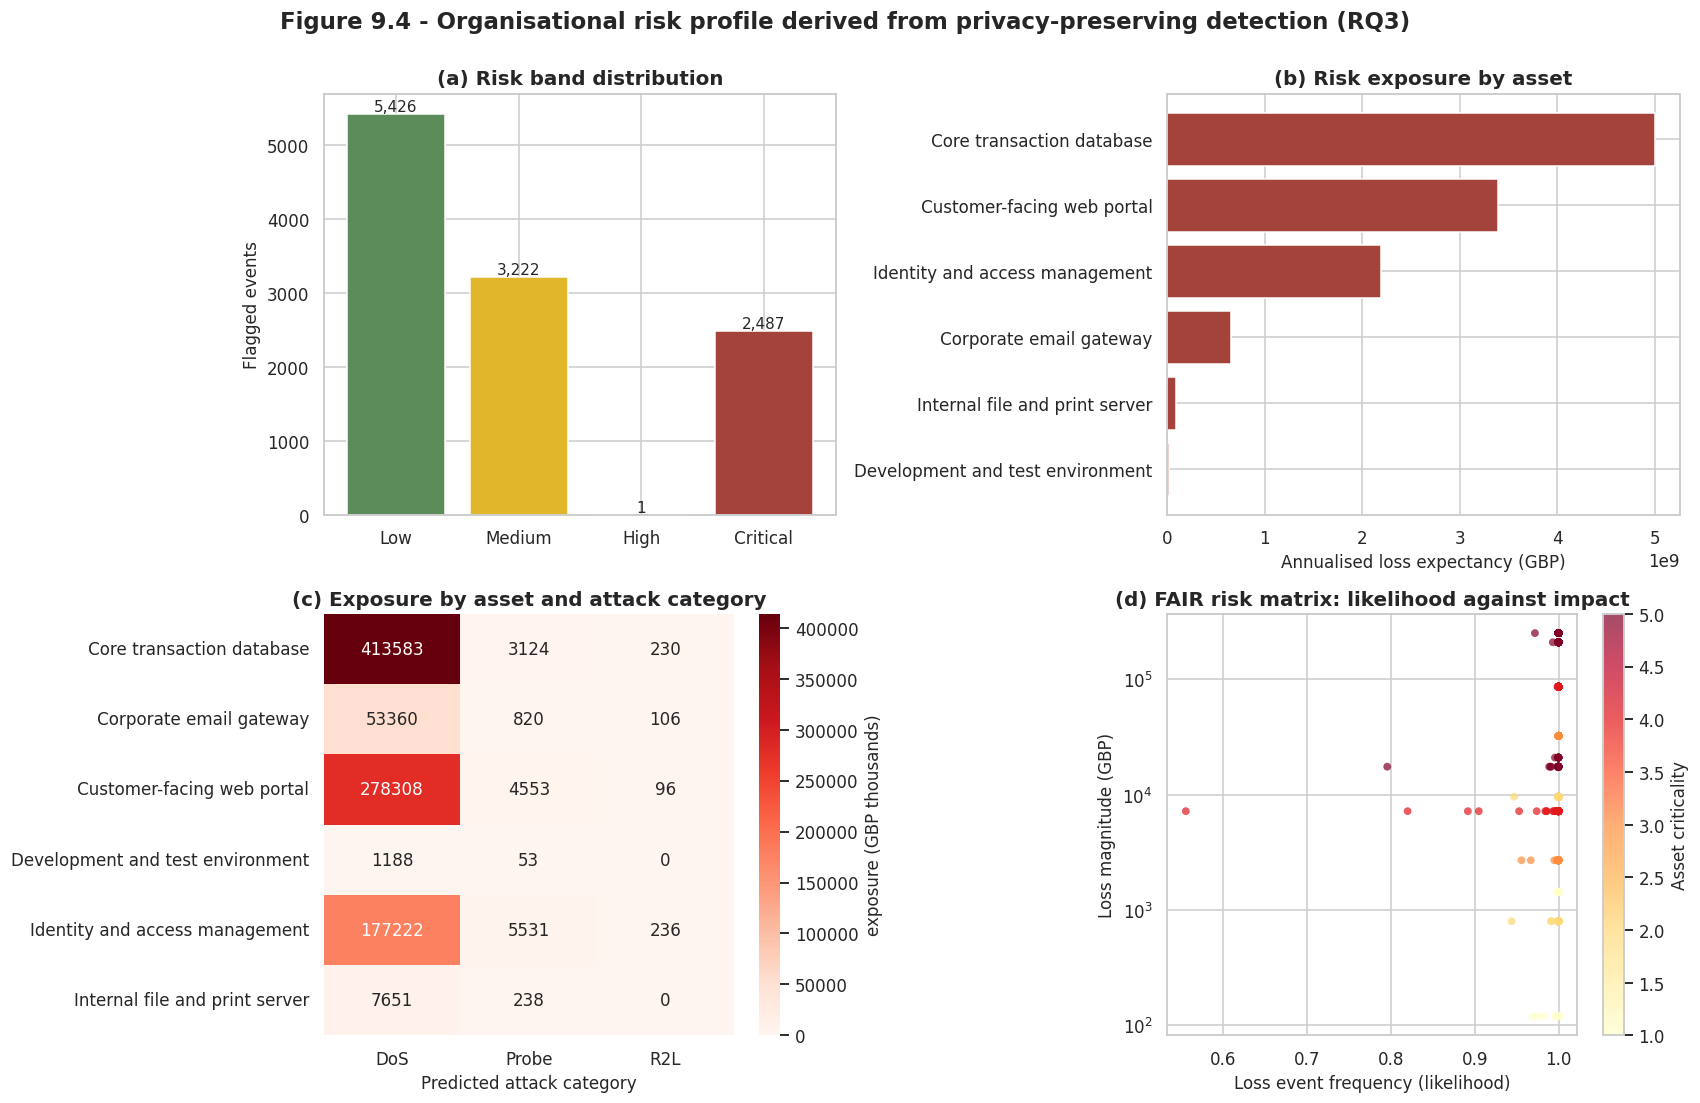

[SAVED] fig_18_risk_profile.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


In [107]:
if len(risk_register) == 0:
    print("Risk register is empty - Figure 9.4 cannot be produced. See the diagnostic in Section 9.9.")
else:
  fig, axes = plt.subplots(2, 2, figsize=(15.5, 10))

  ax = axes[0, 0]
  band_colours = {"Low": "#5B8C5A", "Medium": "#E0B62B", "High": "#E08A2B", "Critical": "#A4433B"}
  ax.bar(band_counts.index, band_counts.values, color=[band_colours[b] for b in band_counts.index])
  ax.set_ylabel("Flagged events"); ax.set_title("(a) Risk band distribution")
  for i, v in enumerate(band_counts.values):
      ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=10)

  ax = axes[0, 1]
  ax.barh(asset_risk["asset_name"], asset_risk["annualised_loss_expectancy_gbp"], color=PALETTE["accent"])
  ax.set_xlabel("Annualised loss expectancy (GBP)")
  ax.set_title("(b) Risk exposure by asset")
  ax.invert_yaxis()

  ax = axes[1, 0]
  pivot = (risk_register.pivot_table(index="asset_name", columns="predicted_category",
                                     values="single_loss_exposure_gbp", aggfunc="sum")
           .fillna(0))
  sns.heatmap(pivot / 1000, annot=True, fmt=".0f", cmap="Reds", ax=ax,
              cbar_kws={"label": "exposure (GBP thousands)"})
  ax.set_title("(c) Exposure by asset and attack category")
  ax.set_xlabel("Predicted attack category"); ax.set_ylabel("")

  ax = axes[1, 1]
  sample = risk_register.sample(min(1500, len(risk_register)), random_state=CONFIG["seed"])
  sc = ax.scatter(sample["loss_event_frequency"], sample["loss_magnitude_gbp"],
                  c=sample["asset_criticality"], cmap="YlOrRd", s=26, alpha=0.7, edgecolors="none")
  ax.set_xlabel("Loss event frequency (likelihood)")
  ax.set_ylabel("Loss magnitude (GBP)"); ax.set_yscale("symlog")
  ax.set_title("(d) FAIR risk matrix: likelihood against impact")
  plt.colorbar(sc, ax=ax, label="Asset criticality")

  fig.suptitle("Figure 9.4 - Organisational risk profile derived from privacy-preserving detection (RQ3)",
               y=1.00, fontsize=15, fontweight="bold")
  fig.tight_layout()
  save_fig(fig, "fig_18_risk_profile",
           "Risk band distribution, per-asset exposure and FAIR likelihood-impact matrix", "9")

### 9.13 Translate detection performance into business-continuity outcomes

This is the step the literature review found missing. A detector's recall determines what fraction of attacks
are caught early enough to be contained; uncaught attacks run to their full disruption duration. Comparing the
two scenarios converts an F1 score into avoided downtime and avoided loss — quantities a business continuity
manager can actually use, and which map directly onto ISO 22301 recovery objectives.

In [108]:
def continuity_outcome(recall, register, containment_factor, annualisation):
    # With the control: a detected attack is contained early, leaving only a residual
    # fraction of the disruption. An undetected attack runs its full course.
    # Without the control: every attack runs its full course.
    full_hours = register["disruption_hours"].to_numpy()
    cost_per_hour = (register["loss_magnitude_gbp"].to_numpy() /
                     np.maximum(full_hours, 1e-9))

    hours_with = recall * (full_hours * containment_factor) + (1 - recall) * full_hours
    hours_without = full_hours

    loss_with = (hours_with * cost_per_hour).sum() * annualisation
    loss_without = (hours_without * cost_per_hour).sum() * annualisation

    rto = register["rto_hours"].to_numpy()
    return {
        "recall": round(float(recall), 4),
        "mean_disruption_hours_with_control": round(float(hours_with.mean()), 3),
        "mean_disruption_hours_without_control": round(float(hours_without.mean()), 3),
        "downtime_hours_avoided_pct": round(float((1 - hours_with.sum()/hours_without.sum()) * 100), 2),
        "annualised_loss_with_control_gbp": round(float(loss_with), 0),
        "annualised_loss_without_control_gbp": round(float(loss_without), 0),
        "annualised_loss_avoided_gbp": round(float(loss_without - loss_with), 0),
        "rto_breaches_with_control": int((hours_with > rto).sum()),
        "rto_breaches_without_control": int((hours_without > rto).sum()),
    }


if len(risk_register) == 0:
    print("Risk register is empty, so continuity outcomes cannot be derived.")
    continuity_df = pd.DataFrame(columns=["configuration", "epsilon", "recall",
                                          "downtime_hours_avoided_pct",
                                          "annualised_loss_avoided_gbp",
                                          "rto_breaches_with_control",
                                          "rto_breaches_without_control",
                                          "annualised_loss_with_control_gbp",
                                          "annualised_loss_without_control_gbp"])
    RESULTS["continuity"] = []
else:
 continuity_rows = []
 scenarios = [("Centralised (no privacy)", central_internal["recall"], np.inf),
              ("Federated (no DP)", fed_internal["recall"], np.inf)]
 scenarios += [(f"Federated + DP (eps={e})",
                dp_df.loc[dp_df["epsilon"] == e, "internal_recall"].iloc[0], e)
               for e in CONFIG["epsilons"]]
 scenarios += [("No detection capability", 0.0, np.nan)]

 for name, recall, eps in scenarios:
     out = continuity_outcome(recall, risk_register, CONFIG["containment_factor"],
                              CONFIG["annualisation_factor"])
     continuity_rows.append({"configuration": name, "epsilon": eps, **out})

 continuity_df = pd.DataFrame(continuity_rows)
 display(continuity_df[["configuration", "recall", "downtime_hours_avoided_pct",
                        "annualised_loss_avoided_gbp", "rto_breaches_with_control"]])
 save_table(continuity_df, "table_21_continuity_outcomes",
            "Business-continuity outcomes derived from detection performance at each privacy level", "9")
 RESULTS["continuity"] = continuity_df.to_dict("records")

,configuration,recall,downtime_hours_avoided_pct,annualised_loss_avoided_gbp,rto_breaches_with_control
0,Centralised (no privacy),0.9929,74.47,8.463045e+09,1
1,Federated (no DP),0.9930,74.48,8.463772e+09,1
2,Federated + DP (eps=0.5),0.9498,71.23,8.095503e+09,1
3,Federated + DP (eps=1.0),0.9680,72.60,8.250628e+09,1
4,Federated + DP (eps=3.0),0.9766,73.25,8.323929e+09,1
5,Federated + DP (eps=5.0),0.9783,73.37,8.338419e+09,1
6,Federated + DP (eps=10.0),0.9802,73.52,8.354613e+09,1
7,No detection capability,0.0000,0.00,0.000000e+00,2488


[TABLE SAVED ] table_21_continuity_outcomes.csv / .tex  (8 rows x 11 cols)


### 9.14 Figure — from privacy budget to continuity outcome

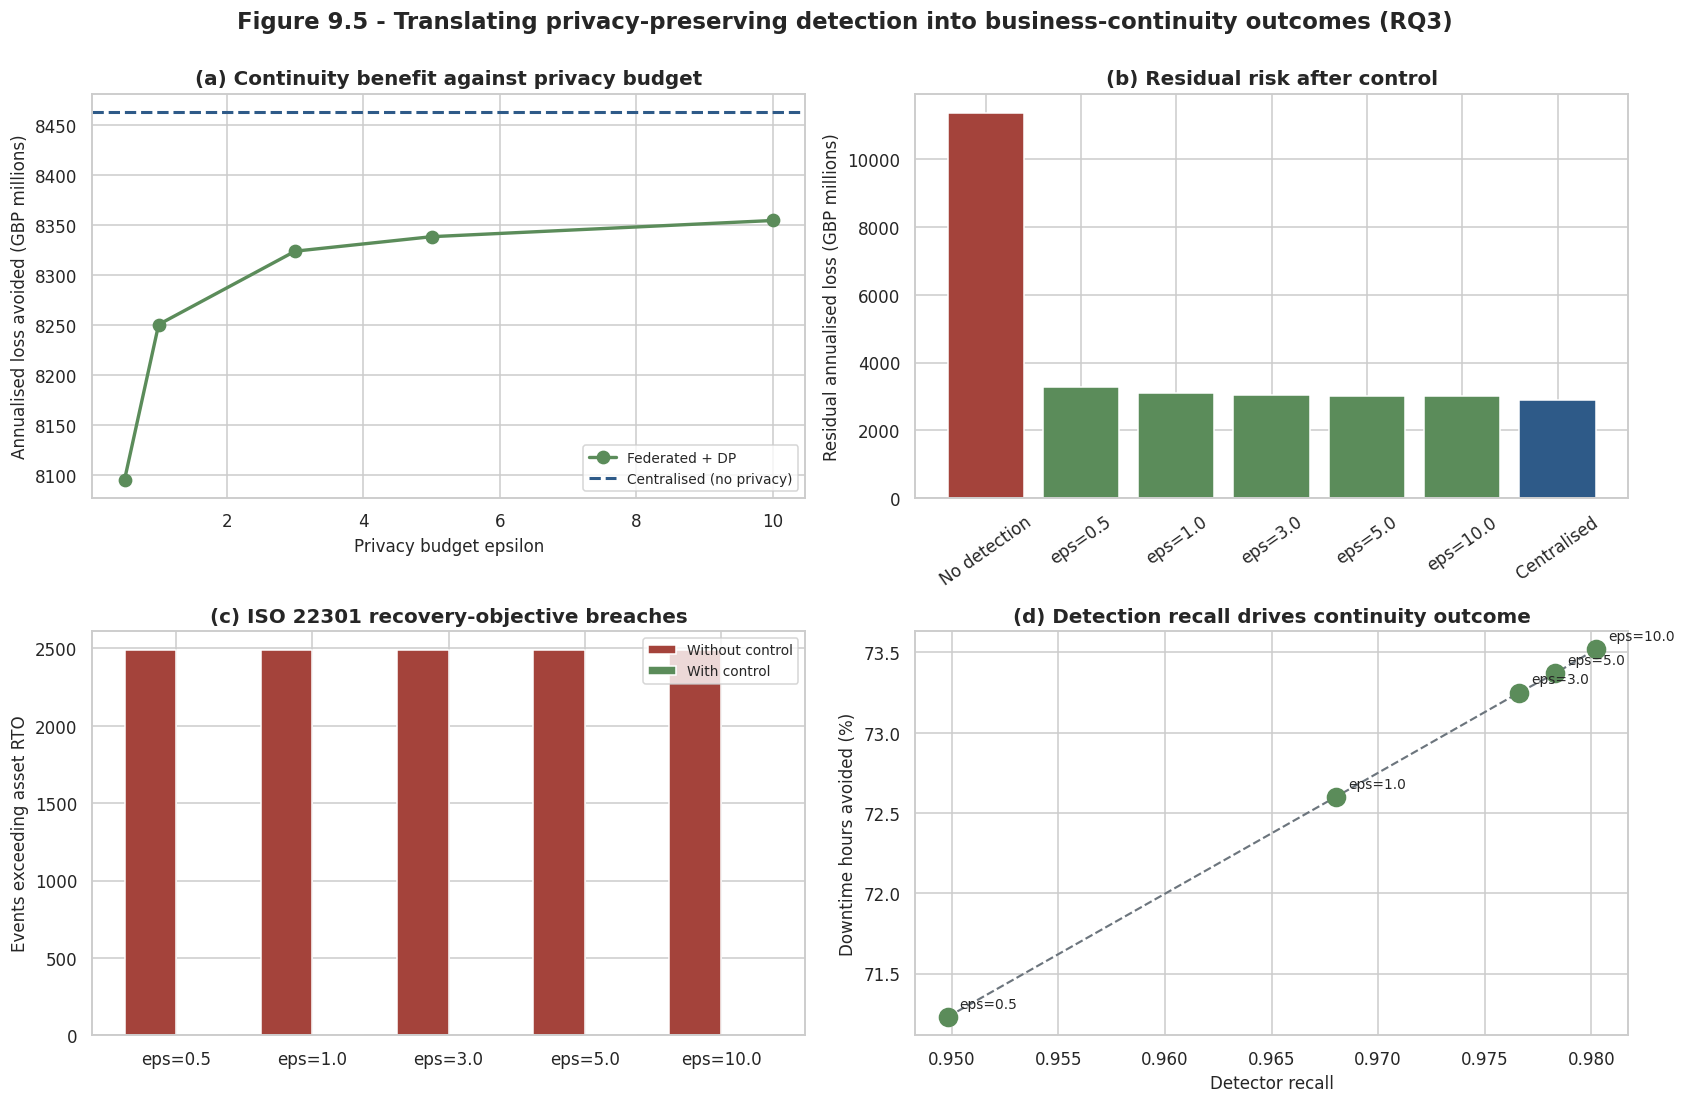

[SAVED] fig_19_continuity_outcomes.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


In [109]:
if len(continuity_df) == 0:
    print("No continuity outcomes to plot - the risk register was empty "
          "(see the diagnostic in Section 9.9).")
else:
    dp_cont = continuity_df[np.isfinite(continuity_df["epsilon"].astype(float))]
    no_ctrl = continuity_df[continuity_df["configuration"] == "No detection capability"].iloc[0]
    central_cont = continuity_df[
        continuity_df["configuration"] == "Centralised (no privacy)"].iloc[0]

    fig, axes = plt.subplots(2, 2, figsize=(15.5, 10))

    ax = axes[0, 0]
    ax.plot(dp_cont["epsilon"], dp_cont["annualised_loss_avoided_gbp"] / 1e6,
            marker="o", ms=8, lw=2.2, color=PALETTE["dp"], label="Federated + DP")
    ax.axhline(central_cont["annualised_loss_avoided_gbp"] / 1e6, ls="--", lw=2,
               color=PALETTE["central"], label="Centralised (no privacy)")
    ax.set_xlabel("Privacy budget epsilon")
    ax.set_ylabel("Annualised loss avoided (GBP millions)")
    ax.set_title("(a) Continuity benefit against privacy budget"); ax.legend(fontsize=9)

    ax = axes[0, 1]
    labels = ["No detection"] + [f"eps={e}" for e in dp_cont["epsilon"]] + ["Centralised"]
    values = ([no_ctrl["annualised_loss_without_control_gbp"]] +
              list(dp_cont["annualised_loss_with_control_gbp"]) +
              [central_cont["annualised_loss_with_control_gbp"]])
    colours = [PALETTE["accent"]] + [PALETTE["dp"]] * len(dp_cont) + [PALETTE["central"]]
    ax.bar(labels, np.array(values) / 1e6, color=colours)
    ax.set_ylabel("Residual annualised loss (GBP millions)")
    ax.set_title("(b) Residual risk after control")
    ax.tick_params(axis="x", rotation=35)

    ax = axes[1, 0]
    w = 0.38
    xp = np.arange(len(dp_cont))
    ax.bar(xp - w/2, dp_cont["rto_breaches_without_control"], w, label="Without control", color=PALETTE["accent"])
    ax.bar(xp + w/2, dp_cont["rto_breaches_with_control"], w, label="With control", color=PALETTE["dp"])
    ax.set_xticks(xp); ax.set_xticklabels([f"eps={e}" for e in dp_cont["epsilon"]])
    ax.set_ylabel("Events exceeding asset RTO")
    ax.set_title("(c) ISO 22301 recovery-objective breaches"); ax.legend(fontsize=9)

    ax = axes[1, 1]
    ax.scatter(dp_cont["recall"], dp_cont["downtime_hours_avoided_pct"], s=140,
               color=PALETTE["dp"], zorder=3)
    for _, r in dp_cont.iterrows():
        ax.annotate(f"eps={r['epsilon']}", (r["recall"], r["downtime_hours_avoided_pct"]),
                    textcoords="offset points", xytext=(8, 6), fontsize=9)
    ax.plot(dp_cont["recall"], dp_cont["downtime_hours_avoided_pct"], lw=1.4,
            ls="--", color=PALETTE["grey"], zorder=2)
    ax.set_xlabel("Detector recall"); ax.set_ylabel("Downtime hours avoided (%)")
    ax.set_title("(d) Detection recall drives continuity outcome")

    fig.suptitle("Figure 9.5 - Translating privacy-preserving detection into business-continuity outcomes (RQ3)",
                 y=1.00, fontsize=15, fontweight="bold")
    fig.tight_layout()
    save_fig(fig, "fig_19_continuity_outcomes",
             "Business-continuity outcomes as a function of the privacy budget", "9")

### 9.15 Worked example — an explained, prioritised alert

In [110]:
# A single high-risk alert, traced end to end, to demonstrate what a security analyst
# would actually receive from the framework.
if len(risk_register) == 0:
    print("Risk register is empty - no alert can be shown. See the diagnostic in Section 9.9.")
elif len(risk_register):
    top = risk_register.sort_values("risk_score", ascending=False).iloc[0]
    fid = int(top["flow_id"])

    if shap_array.ndim == 3:
        cls = CAT_TO_ID.get(top["predicted_category"], 0)
        contrib = explainer.shap_values(X_holdout[fid:fid+1])
        contrib = np.array(contrib)
        vec = contrib[0, :, cls] if contrib.ndim == 3 else contrib[0]
    else:
        vec = np.array(explainer.shap_values(X_holdout[fid:fid+1]))[0]

    order = np.argsort(np.abs(vec))[::-1][:6]

    print("=" * 74)
    print("PRIORITISED SECURITY ALERT (generated by the framework)")
    print("=" * 74)
    print(f"  Asset            : {top['asset_name']} ({top['asset_id']}), criticality {top['asset_criticality']}/5")
    print(f"  Detected as      : {top['predicted_category']}   [ground truth: {top['true_category']}]")
    print(f"  Detector         : federated, differentially private at epsilon = {SELECTED_EPSILON}")
    print(f"  Confidence       : {top['detection_confidence']:.3f}")
    print(f"  Risk score       : {top['risk_score']:.1f}/100  ->  band: {top['risk_band']}")
    print(f"  Expected outage  : {top['disruption_hours']:.2f} h against an RTO of {top['rto_hours']:.0f} h"
          f"  ->  {'RTO BREACH' if top['rto_breach'] else 'within RTO'}")
    print(f"  Loss exposure    : GBP {top['single_loss_exposure_gbp']:,.0f}")
    print(f"  NIST CSF mapping : {top['nist_csf']}")
    print("\n  Why the model classified it this way (top SHAP contributions):")
    for i in order:
        print(f"     {FEATURE_NAMES[i]:<38} contribution {vec[i]:+.4f}")
    print("=" * 74)

    alert_df = pd.DataFrame({"feature": [FEATURE_NAMES[i] for i in order],
                             "shap_contribution": [round(float(vec[i]), 5) for i in order]})
    save_table(alert_df, "table_22_worked_alert_explanation",
               "SHAP explanation for the highest-risk alert produced by the framework", "9")

PRIORITISED SECURITY ALERT (generated by the framework)
  Asset            : Core transaction database (AST-01), criticality 5/5
  Detected as      : DoS   [ground truth: DoS]
  Detector         : federated, differentially private at epsilon = 0.5
  Confidence       : 1.000
  Risk score       : 100.0/100  ->  band: Critical
  Expected outage  : 6.00 h against an RTO of 4 h  ->  RTO BREACH
  Loss exposure    : GBP 251,999
  NIST CSF mapping : DE.AE-02, RS.MI-01

  Why the model classified it this way (top SHAP contributions):
     flag_S0                                contribution +0.1318
     src_bytes                              contribution +0.1209
     dst_bytes                              contribution +0.0704
     count                                  contribution +0.0504
     service_private                        contribution +0.0453
     dst_host_serror_rate                   contribution +0.0399
[TABLE SAVED ] table_22_worked_alert_explanation.csv / .tex  (6 rows x 2 cols)


### 6.9 Statistical validation across random seeds

Everything reported so far comes from a single training run. That is not sufficient evidence for a claim like
*"federation costs 3% of F1"*, because neural training, the Dirichlet partition and — above all — the Gaussian
noise in DP-SGD are all stochastic. A single run cannot distinguish a real effect from a lucky seed.

Each configuration is therefore repeated across `CONFIG["n_seeds"]` independent seeds. The seed controls model
initialisation, batch ordering, the client partition and the DP noise draws, so the repeats are genuinely
independent replications rather than the same run with cosmetic variation. Results are reported as
**mean ± standard deviation**, and the central comparison is tested with a **paired t-test** alongside its
non-parametric equivalent, the **Wilcoxon signed-rank test**, since a sample of three to five seeds is too
small to rely on normality.

Pairing is the right design here: every configuration is evaluated on the same seeds, so seed-level variation
is controlled and the test targets the difference between methods rather than the noise between runs.

In [111]:
from scipy import stats

SEEDS = [CONFIG["seed"] + 1000 * k for k in range(CONFIG["n_seeds"])]
print("Replication seeds:", SEEDS)

n_runs = CONFIG["n_seeds"] * (2 + len(CONFIG["epsilons"]))
print(f"Total training runs in the replication study: {n_runs}")
print("(the seed-0 run reuses the models already trained in Sections 4-6)")

Replication seeds: [42, 1042, 2042]
Total training runs in the replication study: 21
(the seed-0 run reuses the models already trained in Sections 4-6)


### 6.10 Run the replications

In [112]:
log_line(f"Starting replication study over {CONFIG['n_seeds']} seeds")
replication_rows = []
rep_start = time.time()

for si, seed in enumerate(SEEDS):
    print(f"\n{'#'*78}\n# SEED {seed}  ({si+1} of {len(SEEDS)})\n{'#'*78}")

    if si == 0:
        # Reuse the primary run rather than repeating identical work.
        part = dirichlet_partition(cat_fit, CONFIG["n_clients"], CONFIG["dirichlet_alpha"], seed)
        c_metrics, f_metrics = central_internal, fed_internal
        c_time = central_time
        f_time = fed_cost["wall_clock_seconds"]
        dp_metrics = {e: {k.replace("internal_", ""): v
                          for k, v in dp_df[dp_df["epsilon"] == e].iloc[0].items()
                          if str(k).startswith("internal_")}
                      for e in CONFIG["epsilons"]}
        print("  reusing primary-run models for this seed")
    else:
        part = dirichlet_partition(cat_fit, CONFIG["n_clients"], CONFIG["dirichlet_alpha"], seed)

        print("  centralised...")
        m_c, _, c_time = train_centralised(X_fit, y_fit, X_holdout, y_holdout,
                                           CONFIG["central_epochs"], CONFIG["batch_size"],
                                           CONFIG["learning_rate"], seed)
        c_metrics, _, _ = evaluate_model(m_c, X_holdout, y_holdout)

        print("  federated (no DP)...")
        m_f, _, f_cost = run_federated(X_fit, y_fit, part, X_holdout, y_holdout,
                                       CONFIG["fl_rounds"], CONFIG["local_epochs"],
                                       CONFIG["batch_size"], CONFIG["learning_rate"], seed,
                                       use_dp=False, label=f"fed_seed{seed}")
        f_metrics, _, _ = evaluate_model(m_f, X_holdout, y_holdout)
        f_time = f_cost["wall_clock_seconds"]

        dp_metrics = {}
        for eps in CONFIG["epsilons"]:
            sig, _ = compute_client_sigmas(part, eps, CONFIG["fl_rounds"],
                                           CONFIG["local_epochs"], CONFIG["batch_size"])
            print(f"  federated + DP (eps={eps})...")
            m_d, _, _ = run_federated(X_fit, y_fit, part, X_holdout, y_holdout,
                                      CONFIG["fl_rounds"], CONFIG["local_epochs"],
                                      CONFIG["batch_size"], CONFIG["learning_rate"], seed,
                                      use_dp=True, noise_multipliers=sig,
                                      max_grad_norm=CONFIG["max_grad_norm"],
                                      label=f"dp{eps}_seed{seed}")
            dp_metrics[eps], _, _ = evaluate_model(m_d, X_holdout, y_holdout)

    replication_rows.append({"seed": seed, "configuration": "Centralised", "epsilon": np.inf,
                             **c_metrics, "train_seconds": c_time})
    replication_rows.append({"seed": seed, "configuration": "Federated (no DP)", "epsilon": np.inf,
                             **f_metrics, "train_seconds": f_time})
    for eps in CONFIG["epsilons"]:
        replication_rows.append({"seed": seed, "configuration": f"Federated + DP (eps={eps})",
                                 "epsilon": eps, **dp_metrics[eps], "train_seconds": np.nan})

    print(f"  seed {seed}: centralised F1={c_metrics['f1']:.4f} | federated F1={f_metrics['f1']:.4f}")

replication_df = pd.DataFrame(replication_rows)
log_line(f"Replication study finished in {(time.time()-rep_start)/60:.1f} minutes")
save_table(replication_df, "table_11b_replication_raw",
           "Raw per-seed results for every configuration in the replication study", "6")

[15:19:15] Starting replication study over 3 seeds

##############################################################################
# SEED 42  (1 of 3)
##############################################################################
  reusing primary-run models for this seed
  seed 42: centralised F1=0.9944 | federated F1=0.9947

##############################################################################
# SEED 1042  (2 of 3)
##############################################################################
  centralised...
  epoch   1/15  loss=0.0569  val_f1=0.9881  val_acc=0.9890
  epoch   3/15  loss=0.0220  val_f1=0.9910  val_acc=0.9916
  epoch   6/15  loss=0.0171  val_f1=0.9938  val_acc=0.9942
  epoch   9/15  loss=0.0146  val_f1=0.9934  val_acc=0.9939
  epoch  12/15  loss=0.0133  val_f1=0.9949  val_acc=0.9953
  epoch  15/15  loss=0.0123  val_f1=0.9951  val_acc=0.9954
  federated (no DP)...
  round   1/15  val_f1=0.9893  val_acc=0.9900  auc=0.9994
  round   3/15  val_f1=0.9918  val_acc=

'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_11b_replication_raw.csv'

### 6.11 Aggregate to mean ± standard deviation

In [113]:
METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc"]

agg = (replication_df.groupby(["configuration", "epsilon"], dropna=False)[METRICS]
       .agg(["mean", "std"]).reset_index())
agg.columns = ["configuration", "epsilon"] + [f"{m}_{s}" for m, s in agg.columns[2:]]
agg = agg.fillna(0.0)

# A compact, publication-style summary table: "0.9412 ± 0.0031"
summary_rows = []
for _, r in agg.iterrows():
    row = {"configuration": r["configuration"], "epsilon": r["epsilon"], "n_seeds": CONFIG["n_seeds"]}
    for m in METRICS:
        row[m] = f"{r[f'{m}_mean']:.4f} ± {r[f'{m}_std']:.4f}"
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).sort_values("epsilon")
display(summary_df)

save_table(agg, "table_11c_replication_aggregate",
           "Mean and standard deviation of every metric across seeds, per configuration", "6")
save_table(summary_df, "table_11d_replication_summary",
           "Publication-style summary: mean ± standard deviation across seeds", "6")
RESULTS["replication_summary"] = summary_df.to_dict("records")

,configuration,epsilon,n_seeds,accuracy,precision,recall,f1,roc_auc
2,Federated + DP (eps=0.5),0.5,3,0.9738 ± 0.0011,0.9918 ± 0.0031,0.9516 ± 0.0053,0.9713 ± 0.0013,0.9966 ± 0.0006
3,Federated + DP (eps=1.0),1.0,3,0.9784 ± 0.0041,0.9928 ± 0.0017,0.9606 ± 0.0095,0.9764 ± 0.0046,0.9978 ± 0.0007
5,Federated + DP (eps=3.0),3.0,3,0.9861 ± 0.0005,0.9941 ± 0.0033,0.9760 ± 0.0043,0.9849 ± 0.0006,0.9989 ± 0.0002
6,Federated + DP (eps=5.0),5.0,3,0.9876 ± 0.0003,0.9935 ± 0.0039,0.9797 ± 0.0043,0.9866 ± 0.0004,0.9991 ± 0.0000
4,Federated + DP (eps=10.0),10.0,3,0.9885 ± 0.0003,0.9938 ± 0.0037,0.9814 ± 0.0042,0.9875 ± 0.0004,0.9993 ± 0.0001
1,Federated (no DP),inf,3,0.9946 ± 0.0004,0.9956 ± 0.0014,0.9928 ± 0.0009,0.9942 ± 0.0004,0.9997 ± 0.0001
0,Centralised,inf,3,0.9951 ± 0.0003,0.9962 ± 0.0009,0.9933 ± 0.0006,0.9947 ± 0.0003,0.9999 ± 0.0000


[TABLE SAVED ] table_11c_replication_aggregate.csv / .tex  (7 rows x 12 cols)
[TABLE SAVED ] table_11d_replication_summary.csv / .tex  (7 rows x 8 cols)


### 6.12 Significance testing

In [114]:
def paired_tests(a, b, name_a, name_b):
    # a and b are paired vectors: one value per seed, same seeds, same order.
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    diff = a - b
    out = {"comparison": f"{name_a} vs {name_b}", "n_pairs": len(a),
           "mean_a": round(float(a.mean()), 4), "mean_b": round(float(b.mean()), 4),
           "mean_difference": round(float(diff.mean()), 4)}

    if len(a) < 2 or np.allclose(diff, 0):
        out.update({"t_statistic": np.nan, "p_value_ttest": np.nan,
                    "p_value_wilcoxon": np.nan, "cohens_d": np.nan,
                    "significant_at_0.05": False,
                    "note": "insufficient seeds or identical results"})
        return out

    t_stat, p_t = stats.ttest_rel(a, b)
    try:
        _, p_w = stats.wilcoxon(a, b)
    except Exception:
        p_w = np.nan   # Wilcoxon needs a minimum sample size

    sd = diff.std(ddof=1)
    cohens_d = float(diff.mean() / sd) if sd > 0 else np.nan

    out.update({"t_statistic": round(float(t_stat), 4),
                "p_value_ttest": round(float(p_t), 5),
                "p_value_wilcoxon": round(float(p_w), 5) if np.isfinite(p_w) else np.nan,
                "cohens_d": round(cohens_d, 3) if np.isfinite(cohens_d) else np.nan,
                "significant_at_0.05": bool(p_t < 0.05),
                "note": ""})
    return out


def f1_by_seed(config_name):
    sub = replication_df[replication_df["configuration"] == config_name].sort_values("seed")
    return sub["f1"].to_numpy()


tests = [paired_tests(f1_by_seed("Centralised"), f1_by_seed("Federated (no DP)"),
                      "Centralised", "Federated (no DP)")]
for eps in CONFIG["epsilons"]:
    tests.append(paired_tests(f1_by_seed("Federated (no DP)"),
                              f1_by_seed(f"Federated + DP (eps={eps})"),
                              "Federated (no DP)", f"Federated + DP (eps={eps})"))

significance_df = pd.DataFrame(tests)
display(significance_df)
save_table(significance_df, "table_11e_significance_tests",
           "Paired significance tests on F1 across seeds (t-test and Wilcoxon signed-rank)", "6")
RESULTS["significance"] = significance_df.to_dict("records")

,comparison,n_pairs,mean_a,mean_b,mean_difference,t_statistic,p_value_ttest,p_value_wilcoxon,cohens_d,significant_at_0.05,note
0,Centralised vs Federated (no DP),3,0.9947,0.9942,0.0006,1.2593,0.33499,0.50,0.727,False,
1,Federated (no DP) vs Federated + DP (eps=0.5),3,0.9942,0.9713,0.0229,25.1081,0.00158,0.25,14.496,True,
2,Federated (no DP) vs Federated + DP (eps=1.0),3,0.9942,0.9764,0.0178,6.9790,0.01992,0.25,4.029,True,
3,Federated (no DP) vs Federated + DP (eps=3.0),3,0.9942,0.9849,0.0093,19.2615,0.00268,0.25,11.121,True,
4,Federated (no DP) vs Federated + DP (eps=5.0),3,0.9942,0.9866,0.0076,15.3549,0.00421,0.25,8.865,True,
5,Federated (no DP) vs Federated + DP (eps=10.0),3,0.9942,0.9875,0.0067,14.4579,0.00475,0.25,8.347,True,


[TABLE SAVED ] table_11e_significance_tests.csv / .tex  (6 rows x 11 cols)


### 6.13 Interpret the tests

In [115]:
fed_test = significance_df.iloc[0]
print("=" * 84)
print("CENTRALISED versus FEDERATED (the RQ1 comparison)")
print("=" * 84)
print(f"  Centralised F1 : {fed_test['mean_a']:.4f}")
print(f"  Federated F1   : {fed_test['mean_b']:.4f}")
print(f"  Difference     : {fed_test['mean_difference']:+.4f}")
if np.isfinite(fed_test["p_value_ttest"]):
    print(f"  Paired t-test  : t = {fed_test['t_statistic']:.3f}, p = {fed_test['p_value_ttest']:.5f}")
    print(f"  Wilcoxon       : p = {fed_test['p_value_wilcoxon']}")
    print(f"  Cohen's d      : {fed_test['cohens_d']}")
    if fed_test["significant_at_0.05"]:
        print("\n  The gap is statistically significant at alpha = 0.05. Federation carries a real,")
        print("  measurable cost; whether that cost is practically acceptable is judged separately")
        print("  against the 5% band in the success criteria.")
    else:
        print("\n  The gap is NOT statistically significant at alpha = 0.05. On this evidence the")
        print("  federated model performs equivalently to the centralised baseline, which is the")
        print("  strongest possible answer to RQ1.")

print("\n" + "=" * 84)
print("EFFECT OF DIFFERENTIAL PRIVACY (the RQ2 comparisons)")
print("=" * 84)
for _, r in significance_df.iloc[1:].iterrows():
    verdict = "significant" if r["significant_at_0.05"] else "not significant"
    p = f"{r['p_value_ttest']:.5f}" if np.isfinite(r["p_value_ttest"]) else "n/a"
    print(f"  {r['comparison']:<52} diff={r['mean_difference']:+.4f}  p={p}  ({verdict})")

print("\nNote: with a small number of seeds these tests have limited statistical power, so a")
print("non-significant result should be read as 'no detectable difference at this sample size'")
print("rather than as proof of equivalence.")

CENTRALISED versus FEDERATED (the RQ1 comparison)
  Centralised F1 : 0.9947
  Federated F1   : 0.9942
  Difference     : +0.0006
  Paired t-test  : t = 1.259, p = 0.33499
  Wilcoxon       : p = 0.5
  Cohen's d      : 0.727

  The gap is NOT statistically significant at alpha = 0.05. On this evidence the
  federated model performs equivalently to the centralised baseline, which is the
  strongest possible answer to RQ1.

EFFECT OF DIFFERENTIAL PRIVACY (the RQ2 comparisons)
  Federated (no DP) vs Federated + DP (eps=0.5)        diff=+0.0229  p=0.00158  (significant)
  Federated (no DP) vs Federated + DP (eps=1.0)        diff=+0.0178  p=0.01992  (significant)
  Federated (no DP) vs Federated + DP (eps=3.0)        diff=+0.0093  p=0.00268  (significant)
  Federated (no DP) vs Federated + DP (eps=5.0)        diff=+0.0076  p=0.00421  (significant)
  Federated (no DP) vs Federated + DP (eps=10.0)       diff=+0.0067  p=0.00475  (significant)

Note: with a small number of seeds these tests have 

### 6.14 Figure — results with uncertainty

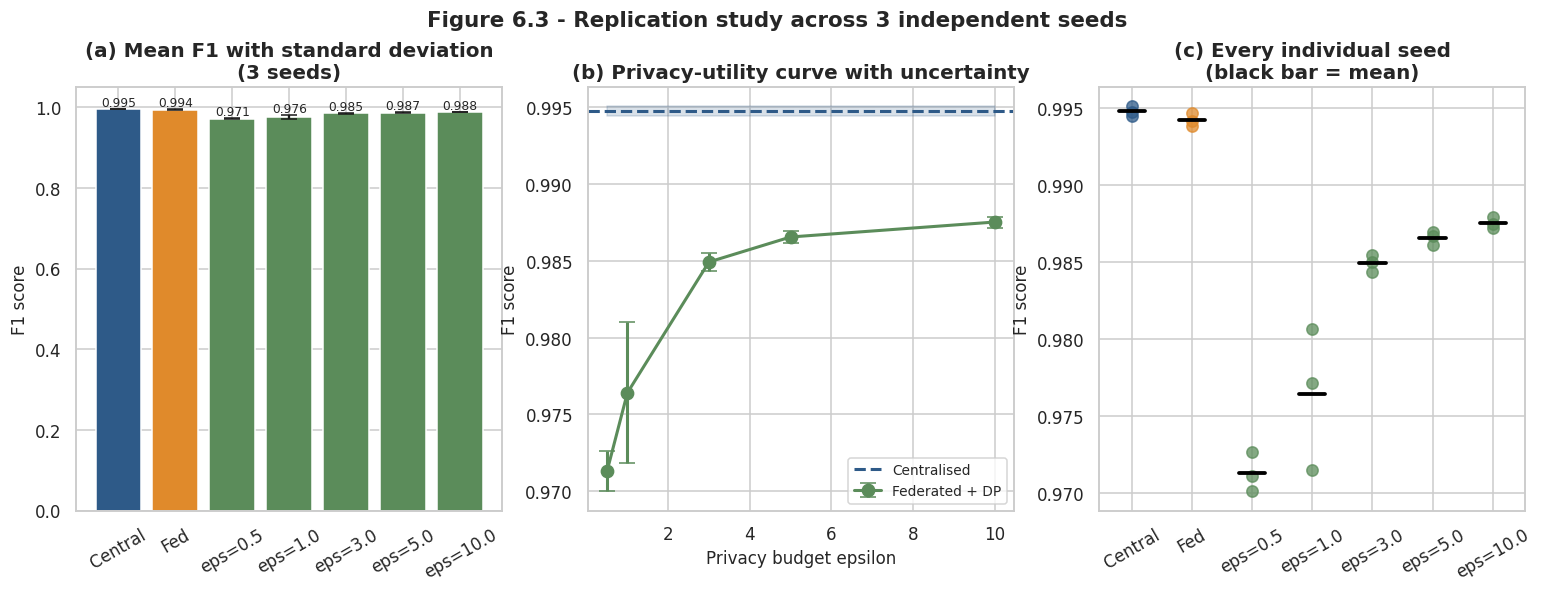

[SAVED] fig_12b_replication.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_12b_replication.png'

In [116]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

ax = axes[0]
order = ["Centralised", "Federated (no DP)"] + [f"Federated + DP (eps={e})" for e in CONFIG["epsilons"]]
means = [agg.loc[agg["configuration"] == c, "f1_mean"].iloc[0] for c in order]
stds  = [agg.loc[agg["configuration"] == c, "f1_std"].iloc[0] for c in order]
cols  = [PALETTE["central"], PALETTE["federated"]] + [PALETTE["dp"]] * len(CONFIG["epsilons"])
short = ["Central", "Fed"] + [f"eps={e}" for e in CONFIG["epsilons"]]
ax.bar(short, means, yerr=stds, capsize=5, color=cols, error_kw={"lw": 1.5})
ax.set_ylabel("F1 score"); ax.set_ylim(0, 1.05)
ax.set_title(f"(a) Mean F1 with standard deviation\n({CONFIG['n_seeds']} seeds)")
ax.tick_params(axis="x", rotation=30)
for i, (m, sd) in enumerate(zip(means, stds)):
    ax.text(i, m + sd, f"{m:.3f}", ha="center", va="bottom", fontsize=8)

ax = axes[1]
eps_only = agg[np.isfinite(agg["epsilon"])].sort_values("epsilon")
ax.errorbar(eps_only["epsilon"], eps_only["f1_mean"], yerr=eps_only["f1_std"],
            marker="o", ms=8, lw=2, capsize=5, color=PALETTE["dp"], label="Federated + DP")
c_mean = agg.loc[agg["configuration"] == "Centralised", "f1_mean"].iloc[0]
c_std  = agg.loc[agg["configuration"] == "Centralised", "f1_std"].iloc[0]
ax.axhline(c_mean, ls="--", lw=2, color=PALETTE["central"], label="Centralised")
ax.fill_between([eps_only["epsilon"].min(), eps_only["epsilon"].max()],
                c_mean - c_std, c_mean + c_std, alpha=0.18, color=PALETTE["central"])
ax.set_xlabel("Privacy budget epsilon"); ax.set_ylabel("F1 score")
ax.set_title("(b) Privacy-utility curve with uncertainty"); ax.legend(fontsize=9)

ax = axes[2]
for i, c in enumerate(order):
    vals = replication_df.loc[replication_df["configuration"] == c, "f1"].to_numpy()
    ax.scatter([i] * len(vals), vals, s=55, alpha=0.75, color=cols[i], zorder=3)
    ax.plot([i - 0.22, i + 0.22], [vals.mean()] * 2, lw=2.5, color="black", zorder=4)
ax.set_xticks(range(len(order))); ax.set_xticklabels(short, rotation=30)
ax.set_ylabel("F1 score"); ax.set_title("(c) Every individual seed\n(black bar = mean)")

fig.suptitle(f"Figure 6.3 - Replication study across {CONFIG['n_seeds']} independent seeds",
             y=1.02, fontsize=14, fontweight="bold")
save_fig(fig, "fig_12b_replication",
         "Detection performance with standard-deviation error bars across independent seeds", "6")

---
## Section 10 — Benchmarking against the published literature

A baseline is only meaningful if it is competitive. If the centralised model were weak, then "federated
performance is close to centralised" would be an easy and uninteresting result. This section anchors the
baseline against published results on the same benchmark and the same evaluation split.

**The comparison must be like for like.** Published NSL-KDD results are almost always reported on the official
`KDDTest+` partition, which contains attack signatures absent from training. Comparing our *internal* holdout
score against those figures would flatter this work considerably, because the internal split is drawn from the
same distribution as training and is a much easier target. The table below therefore uses the official test-set
figures from Section 4, and reports both so the difference is visible.

### 10.1 Published reference results

In [117]:
# Reported binary-classification results from peer-reviewed work on the same benchmarks.
# These are quoted from the cited papers, not reproduced here; they establish the range a
# competent baseline should fall within.
LITERATURE = pd.DataFrame([
    ("NSL_KDD", "Ingre and Yadav (2015)", "ANN", "KDDTest+", 81.2, np.nan,
     "IEEE ICSPCT"),
    ("NSL_KDD", "Yin et al. (2017)", "RNN-IDS", "KDDTest+", 83.28, np.nan,
     "IEEE Access"),
    ("NSL_KDD", "Alzubi et al. (2020)", "MBGWO + SVM", "KDDTest+", 81.58, np.nan,
     "feature-selection approach"),
    ("NSL_KDD", "Tama et al. (2019)", "TSE-IDS ensemble", "KDDTest+", 85.80, 88.00,
     "IEEE Access"),
    ("NSL_KDD", "Kasongo and Sun (2022)", "XGBoost + LSTM", "KDDTest+", 88.13, np.nan,
     "Computer Communications"),
    ("UNSW_NB15", "Tama et al. (2019)", "TSE-IDS ensemble", "official test", 91.27, 91.27,
     "IEEE Access"),
    ("UNSW_NB15", "Kasongo and Sun (2022)", "XGBoost + Simple RNN", "official test", 87.07, np.nan,
     "Computer Communications"),
], columns=["dataset", "study", "method", "evaluation_split",
            "accuracy_pct", "precision_pct", "venue_or_note"])

lit_active = LITERATURE[LITERATURE["dataset"] == CONFIG["dataset"]].copy()
display(lit_active)

if len(lit_active):
    print(f"\nPublished accuracy range on {ACTIVE['display_name']}: "
          f"{lit_active['accuracy_pct'].min():.2f}% - {lit_active['accuracy_pct'].max():.2f}%")
else:
    print(f"No reference results catalogued for {CONFIG['dataset']}.")

save_table(LITERATURE, "table_26_literature_reference",
           "Published binary-classification results on the benchmark datasets used in this study", "10")

,dataset,study,method,evaluation_split,accuracy_pct,precision_pct,venue_or_note
0,NSL_KDD,Ingre and Yadav (2015),ANN,KDDTest+,81.20,NaN,IEEE ICSPCT
1,NSL_KDD,Yin et al. (2017),RNN-IDS,KDDTest+,83.28,NaN,IEEE Access
2,NSL_KDD,Alzubi et al. (2020),MBGWO + SVM,KDDTest+,81.58,NaN,feature-selection approach
3,NSL_KDD,Tama et al. (2019),TSE-IDS ensemble,KDDTest+,85.80,88.0,IEEE Access
4,NSL_KDD,Kasongo and Sun (2022),XGBoost + LSTM,KDDTest+,88.13,NaN,Computer Communications



Published accuracy range on NSL-KDD: 81.20% - 88.13%
[TABLE SAVED ] table_26_literature_reference.csv / .tex  (7 rows x 7 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_26_literature_reference.csv'

> These figures are quoted from the cited publications for context. Direct comparison always carries caveats —
> preprocessing, feature selection and class balancing differ between studies — so the table establishes a
> plausible range rather than a strict ranking.

### 10.2 Position this work against the published range

In [118]:
own_rows = [
    {"study": "This work", "method": "MLP, centralised (no privacy)",
     "evaluation_split": "official test", "accuracy_pct": round(central_official["accuracy"]*100, 2),
     "f1_pct": round(central_official["f1"]*100, 2), "privacy": "None"},
    {"study": "This work", "method": f"MLP, federated ({CONFIG['n_clients']} clients, non-IID)",
     "evaluation_split": "official test", "accuracy_pct": round(fed_official["accuracy"]*100, 2),
     "f1_pct": round(fed_official["f1"]*100, 2), "privacy": "Data locality"},
]
for eps in CONFIG["epsilons"]:
    r = dp_df[dp_df["epsilon"] == eps].iloc[0]
    own_rows.append({"study": "This work", "method": f"MLP, federated + DP",
                     "evaluation_split": "official test",
                     "accuracy_pct": round(r["official_accuracy"]*100, 2),
                     "f1_pct": round(r["official_f1"]*100, 2),
                     "privacy": f"(eps={eps}, delta<1/n)-DP"})

own_df = pd.DataFrame(own_rows)
display(own_df)

if len(lit_active):
    lo, hi = lit_active["accuracy_pct"].min(), lit_active["accuracy_pct"].max()
    ours = central_official["accuracy"] * 100
    if ours >= lo:
        verdict = ("within the published range" if ours <= hi
                   else "above the highest published figure catalogued here")
    else:
        verdict = "below the published range - investigate before drawing comparative conclusions"
    print(f"\nCentralised baseline on the official test split: {ours:.2f}%")
    print(f"Published range: {lo:.2f}% - {hi:.2f}%")
    print(f"Assessment: the baseline is {verdict}.")
    print("\nNone of the cited studies provides a formal privacy guarantee, so the DP rows above")
    print("purchase something the published baselines do not offer at any accuracy level.")

save_table(own_df, "table_27_own_results_vs_literature",
           "This study's results on the official test split, formatted for comparison with the literature", "10")

,study,method,evaluation_split,accuracy_pct,f1_pct,privacy
0,This work,"MLP, centralised (no privacy)",official test,77.53,76.99,None
1,This work,"MLP, federated (5 clients, non-IID)",official test,78.87,78.62,Data locality
2,This work,"MLP, federated + DP",official test,73.85,72.11,"(eps=0.5, delta<1/n)-DP"
3,This work,"MLP, federated + DP",official test,75.02,73.73,"(eps=1.0, delta<1/n)-DP"
4,This work,"MLP, federated + DP",official test,75.02,73.75,"(eps=3.0, delta<1/n)-DP"
5,This work,"MLP, federated + DP",official test,74.96,73.68,"(eps=5.0, delta<1/n)-DP"
6,This work,"MLP, federated + DP",official test,74.98,73.64,"(eps=10.0, delta<1/n)-DP"



Centralised baseline on the official test split: 77.53%
Published range: 81.20% - 88.13%
Assessment: the baseline is below the published range - investigate before drawing comparative conclusions.

None of the cited studies provides a formal privacy guarantee, so the DP rows above
purchase something the published baselines do not offer at any accuracy level.
[TABLE SAVED ] table_27_own_results_vs_literature.csv / .tex  (7 rows x 6 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_27_own_results_vs_literature.csv'

### 10.3 Figure — this work in context

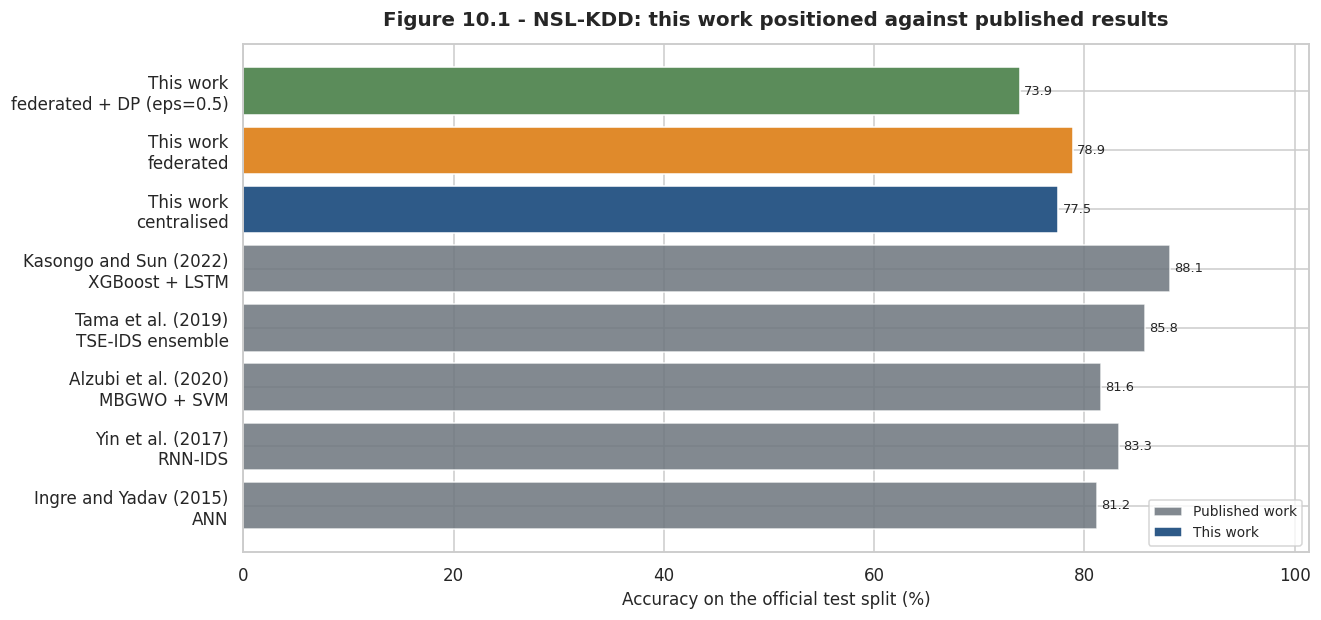

[SAVED] fig_21_literature_comparison.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_21_literature_comparison.png'

In [119]:
fig, ax = plt.subplots(figsize=(12.5, 6))

if len(lit_active):
    ax.barh(lit_active["study"] + "\n" + lit_active["method"],
            lit_active["accuracy_pct"], color=PALETTE["grey"], alpha=0.85, label="Published work")

ours_labels, ours_vals, ours_cols = [], [], []
ours_labels.append("This work\ncentralised"); ours_vals.append(central_official["accuracy"]*100)
ours_cols.append(PALETTE["central"])
ours_labels.append("This work\nfederated"); ours_vals.append(fed_official["accuracy"]*100)
ours_cols.append(PALETTE["federated"])
sel_row = dp_df[dp_df["epsilon"] == SELECTED_EPSILON].iloc[0]
ours_labels.append(f"This work\nfederated + DP (eps={SELECTED_EPSILON})")
ours_vals.append(sel_row["official_accuracy"]*100); ours_cols.append(PALETTE["dp"])

ax.barh(ours_labels, ours_vals, color=ours_cols, label="This work")
ax.set_xlabel("Accuracy on the official test split (%)")
ax.set_title(f"Figure 10.1 - {ACTIVE['display_name']}: this work positioned against published results",
             pad=12)
ax.legend(fontsize=9, loc="lower right")
for i, v in enumerate(list(lit_active["accuracy_pct"]) + ours_vals):
    ax.text(v + 0.4, i, f"{v:.1f}", va="center", fontsize=8.5)
ax.set_xlim(0, max(list(lit_active["accuracy_pct"]) + ours_vals) * 1.15)

save_fig(fig, "fig_21_literature_comparison",
         "Detection accuracy of this work compared with published results on the same benchmark", "10")

---
## Section 11 — Ablation studies

Two design choices in the framework deserve to be tested rather than assumed: the aggregation algorithm, and
the assumed degree of client heterogeneity. Both ablations run without differential privacy, which isolates
the effect being studied from the privacy noise.

They are also deliberately cheaper than the main experiments — fewer rounds, no privacy sweep — because their
purpose is to establish *direction and sensitivity*, not to produce headline figures.

### 11.1 FedAvg versus FedProx under non-IID data

FedAvg averages client parameters directly. When clients hold very different data, their local optima diverge,
each pulls the global model towards its own distribution, and the average can be worse than any individual
update — a failure mode known as client drift.

**FedProx** addresses this by adding a proximal term `(mu/2)·||w − w_global||²` to each client's local loss,
penalising drift from the current global model. It sacrifices some local fitting to keep clients aligned. The
question is whether that trade is worthwhile at this dataset's level of heterogeneity.

> The proximal term is a penalty on model parameters, not on individual records, so it does not fit the
> per-sample gradient structure that DP-SGD requires. This ablation therefore runs without DP, and FedAvg
> remains the algorithm used in the private experiments.

In [120]:
def local_train_fedprox(global_state, X, y, epochs, batch_size, lr, seed, mu):
    # Identical to the standard local update except for the proximal penalty.
    set_seed(seed)
    model = IDSNet(X.shape[1], CONFIG["hidden_1"], CONFIG["hidden_2"], CONFIG["dropout"]).to(DEVICE)
    model.load_state_dict(global_state)
    model.train()

    # Frozen reference copy of the global parameters for the penalty term.
    global_params = [p.detach().clone().to(DEVICE) for p in model.parameters()]

    optimiser = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    loader = make_loader(X, y, batch_size)

    for _ in range(epochs):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimiser.zero_grad()
            loss = criterion(model(xb), yb)
            if mu > 0:
                prox = sum(((p - g) ** 2).sum() for p, g in zip(model.parameters(), global_params))
                loss = loss + (mu / 2.0) * prox
            loss.backward()
            optimiser.step()

    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


def run_fedprox(X, y, client_indices, X_val, y_val, rounds, mu, seed):
    set_seed(seed)
    global_model = IDSNet(X.shape[1], CONFIG["hidden_1"], CONFIG["hidden_2"], CONFIG["dropout"]).to(DEVICE)
    global_state = get_state(global_model)
    history = []
    start = time.time()
    for rnd in range(1, rounds + 1):
        states, weights = [], []
        for cid, idx in enumerate(client_indices):
            states.append(local_train_fedprox(global_state, X[idx], y[idx],
                                              CONFIG["local_epochs"], CONFIG["batch_size"],
                                              CONFIG["learning_rate"], seed + rnd * 100 + cid, mu))
            weights.append(len(idx))
        global_state = federated_average(states, weights)
        global_model.load_state_dict(global_state)
        m, _, _ = evaluate_model(global_model, X_val, y_val)
        history.append({"round": rnd, **m})
    return global_model, pd.DataFrame(history), time.time() - start


print("FedProx implemented (mu = 0 reduces exactly to FedAvg, which is a useful correctness check).")

FedProx implemented (mu = 0 reduces exactly to FedAvg, which is a useful correctness check).


### 11.2 Run the aggregation ablation

In [121]:
log_line("Running FedAvg vs FedProx ablation")
ablation_rounds = max(5, CONFIG["fl_rounds"] // 2)
prox_rows, prox_histories = [], {}

for mu in CONFIG["fedprox_mu_values"]:
    label = "FedAvg (mu=0)" if mu == 0 else f"FedProx (mu={mu})"
    print(f"\n  {label} over {ablation_rounds} rounds...")
    m, hist, elapsed = run_fedprox(X_fit, y_fit, CLIENT_INDICES, X_holdout, y_holdout,
                                   ablation_rounds, mu, CONFIG["seed"])
    metrics, _, _ = evaluate_model(m, X_holdout, y_holdout)
    prox_histories[label] = hist
    prox_rows.append({"algorithm": label, "mu": mu,
                      **{k: round(v, 4) for k, v in metrics.items()},
                      "seconds": round(elapsed, 1),
                      "round_to_round_std": round(float(hist["f1"].diff().std()), 5)})
    print(f"    F1={metrics['f1']:.4f}  accuracy={metrics['accuracy']:.4f}")

prox_df = pd.DataFrame(prox_rows)
display(prox_df)

best = prox_df.loc[prox_df["f1"].idxmax()]
fedavg_f1 = prox_df.loc[prox_df["mu"] == 0, "f1"].iloc[0]
print(f"\nBest configuration: {best['algorithm']} (F1 = {best['f1']:.4f})")
print(f"FedAvg reference  : F1 = {fedavg_f1:.4f}  |  difference = {best['f1']-fedavg_f1:+.4f}")
print("\nThe 'round_to_round_std' column measures training stability: lower values mean the global")
print("model moves more smoothly between rounds, which is the effect FedProx is designed to produce.")

save_table(prox_df, "table_28_fedprox_ablation",
           "FedAvg versus FedProx under non-IID client data", "11")
RESULTS["fedprox_ablation"] = prox_df.to_dict("records")

[15:40:21] Running FedAvg vs FedProx ablation

  FedAvg (mu=0) over 7 rounds...
    F1=0.9915  accuracy=0.9922

  FedProx (mu=0.01) over 7 rounds...
    F1=0.9906  accuracy=0.9913

  FedProx (mu=0.1) over 7 rounds...
    F1=0.9879  accuracy=0.9889


,algorithm,mu,accuracy,precision,recall,f1,roc_auc,pr_auc,seconds,round_to_round_std
0,FedAvg (mu=0),0.00,0.9922,0.9987,0.9845,0.9915,0.9997,0.9997,23.8,0.00149
1,FedProx (mu=0.01),0.01,0.9913,0.9984,0.9829,0.9906,0.9997,0.9997,31.9,0.00265
2,FedProx (mu=0.1),0.10,0.9889,0.9983,0.9778,0.9879,0.9996,0.9995,32.4,0.00414



Best configuration: FedAvg (mu=0) (F1 = 0.9915)
FedAvg reference  : F1 = 0.9915  |  difference = +0.0000

The 'round_to_round_std' column measures training stability: lower values mean the global
model moves more smoothly between rounds, which is the effect FedProx is designed to produce.
[TABLE SAVED ] table_28_fedprox_ablation.csv / .tex  (3 rows x 10 cols)


### 11.3 Sensitivity to client count and data heterogeneity

The main experiments fix five clients and a Dirichlet concentration of 0.5. Both are modelling choices, and a
result that only holds at those exact settings would be fragile. This ablation varies each independently:

* **Client count** — more clients means less data each, more averaging, and a harder problem.
* **Dirichlet alpha** — controls skew. Low alpha (0.1) makes clients extremely specialised, some seeing almost
  none of certain attack families; high alpha (5.0) approaches an even, IID-like split.

In [122]:
log_line("Running sensitivity analysis")
sens_rows = []
sens_rounds = max(5, CONFIG["fl_rounds"] // 2)

print("Varying the number of clients (alpha held at %.2f):" % CONFIG["dirichlet_alpha"])
for k in CONFIG["sensitivity_client_counts"]:
    part = dirichlet_partition(cat_fit, k, CONFIG["dirichlet_alpha"], CONFIG["seed"])
    if min(len(p) for p in part) < CONFIG["batch_size"]:
        print(f"  k={k}: skipped - at least one client holds fewer records than one batch")
        continue
    m, _, cost = run_federated(X_fit, y_fit, part, X_holdout, y_holdout, sens_rounds,
                               CONFIG["local_epochs"], CONFIG["batch_size"],
                               CONFIG["learning_rate"], CONFIG["seed"], use_dp=False,
                               label=f"sens_k{k}")
    met, _, _ = evaluate_model(m, X_holdout, y_holdout)
    sens_rows.append({"parameter": "n_clients", "value": k, "n_clients": k,
                      "alpha": CONFIG["dirichlet_alpha"],
                      "smallest_client": int(min(len(p) for p in part)),
                      **{kk: round(v, 4) for kk, v in met.items()},
                      "communication_mb": round(cost["communication_mb"], 2)})
    print(f"  k={k:>3}: F1={met['f1']:.4f}  accuracy={met['accuracy']:.4f}  "
          f"(smallest client {min(len(p) for p in part):,} records)")

print("\nVarying data heterogeneity (clients held at %d):" % CONFIG["n_clients"])
for alpha in CONFIG["sensitivity_alphas"]:
    part = dirichlet_partition(cat_fit, CONFIG["n_clients"], alpha, CONFIG["seed"])
    if min(len(p) for p in part) < CONFIG["batch_size"]:
        print(f"  alpha={alpha}: skipped - partition left a client below one batch")
        continue
    m, _, cost = run_federated(X_fit, y_fit, part, X_holdout, y_holdout, sens_rounds,
                               CONFIG["local_epochs"], CONFIG["batch_size"],
                               CONFIG["learning_rate"], CONFIG["seed"], use_dp=False,
                               label=f"sens_a{alpha}")
    met, _, _ = evaluate_model(m, X_holdout, y_holdout)
    sens_rows.append({"parameter": "dirichlet_alpha", "value": alpha,
                      "n_clients": CONFIG["n_clients"], "alpha": alpha,
                      "smallest_client": int(min(len(p) for p in part)),
                      **{kk: round(v, 4) for kk, v in met.items()},
                      "communication_mb": round(cost["communication_mb"], 2)})
    print(f"  alpha={alpha:>5}: F1={met['f1']:.4f}  accuracy={met['accuracy']:.4f}")

sensitivity_df = pd.DataFrame(sens_rows)
display(sensitivity_df)
save_table(sensitivity_df, "table_29_sensitivity_analysis",
           "Sensitivity of federated detection performance to client count and data heterogeneity", "11")
RESULTS["sensitivity"] = sensitivity_df.to_dict("records")

[15:41:49] Running sensitivity analysis
Varying the number of clients (alpha held at 0.50):
  round   1/7  val_f1=0.9878  val_acc=0.9888  auc=0.9993
  round   2/7  val_f1=0.9898  val_acc=0.9906  auc=0.9993
  round   3/7  val_f1=0.9902  val_acc=0.9910  auc=0.9992
  round   4/7  val_f1=0.9909  val_acc=0.9915  auc=0.9995
  round   5/7  val_f1=0.9913  val_acc=0.9920  auc=0.9993
  round   6/7  val_f1=0.9908  val_acc=0.9915  auc=0.9993
  round   7/7  val_f1=0.9913  val_acc=0.9920  auc=0.9994
  k=  3: F1=0.9913  accuracy=0.9920  (smallest client 4,050 records)
  round   1/7  val_f1=0.9854  val_acc=0.9866  auc=0.9994
  round   2/7  val_f1=0.9893  val_acc=0.9901  auc=0.9996
  round   3/7  val_f1=0.9902  val_acc=0.9910  auc=0.9997
  round   4/7  val_f1=0.9910  val_acc=0.9917  auc=0.9997
  round   5/7  val_f1=0.9917  val_acc=0.9923  auc=0.9997
  round   6/7  val_f1=0.9910  val_acc=0.9917  auc=0.9997
  round   7/7  val_f1=0.9915  val_acc=0.9922  auc=0.9997
  k=  5: F1=0.9915  accuracy=0.9922  (sma

,parameter,value,n_clients,alpha,smallest_client,accuracy,precision,recall,f1,roc_auc,pr_auc,communication_mb
0,n_clients,3.0,3,0.5,4050,0.9920,0.9984,0.9844,0.9913,0.9994,0.9994,4.10
1,n_clients,5.0,5,0.5,1280,0.9922,0.9987,0.9845,0.9915,0.9997,0.9997,6.83
2,n_clients,10.0,10,0.5,1081,0.9925,0.9979,0.9858,0.9918,0.9997,0.9996,13.66
3,dirichlet_alpha,0.5,5,0.5,1280,0.9922,0.9987,0.9845,0.9915,0.9997,0.9997,6.83
4,dirichlet_alpha,5.0,5,5.0,14336,0.9926,0.9969,0.9872,0.9920,0.9997,0.9997,6.83


[TABLE SAVED ] table_29_sensitivity_analysis.csv / .tex  (5 rows x 12 cols)


### 11.4 Figure — ablation results

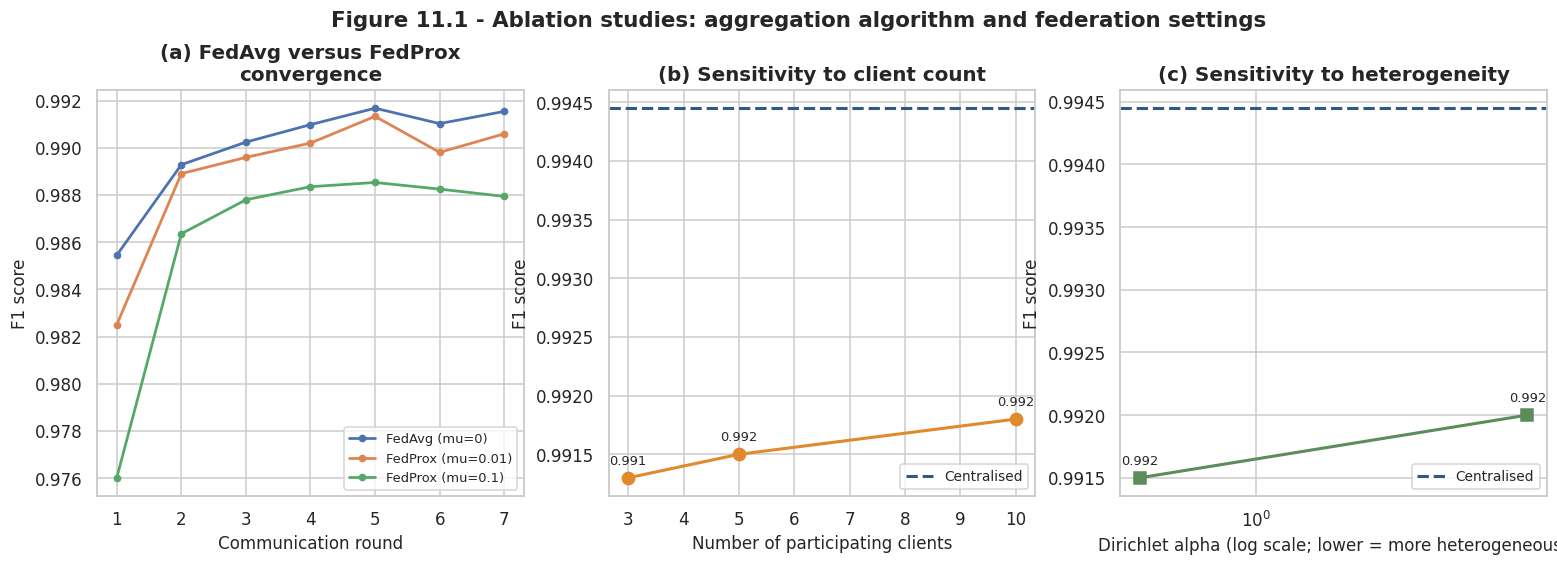

[SAVED] fig_22_ablations.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_22_ablations.png'

In [123]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

ax = axes[0]
for label, hist in prox_histories.items():
    ax.plot(hist["round"], hist["f1"], marker="o", ms=4, lw=1.8, label=label)
ax.set_xlabel("Communication round"); ax.set_ylabel("F1 score")
ax.set_title("(a) FedAvg versus FedProx\nconvergence"); ax.legend(fontsize=8.5)

ax = axes[1]
k_rows = sensitivity_df[sensitivity_df["parameter"] == "n_clients"]
if len(k_rows):
    ax.plot(k_rows["value"], k_rows["f1"], marker="o", ms=8, lw=2, color=PALETTE["federated"])
    ax.axhline(central_internal["f1"], ls="--", lw=2, color=PALETTE["central"], label="Centralised")
    for _, r in k_rows.iterrows():
        ax.annotate(f"{r['f1']:.3f}", (r["value"], r["f1"]),
                    textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8.5)
    ax.legend(fontsize=9)
ax.set_xlabel("Number of participating clients"); ax.set_ylabel("F1 score")
ax.set_title("(b) Sensitivity to client count")

ax = axes[2]
a_rows = sensitivity_df[sensitivity_df["parameter"] == "dirichlet_alpha"]
if len(a_rows):
    ax.plot(a_rows["value"], a_rows["f1"], marker="s", ms=8, lw=2, color=PALETTE["dp"])
    ax.axhline(central_internal["f1"], ls="--", lw=2, color=PALETTE["central"], label="Centralised")
    ax.set_xscale("log")
    for _, r in a_rows.iterrows():
        ax.annotate(f"{r['f1']:.3f}", (r["value"], r["f1"]),
                    textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8.5)
    ax.legend(fontsize=9)
ax.set_xlabel("Dirichlet alpha (log scale; lower = more heterogeneous)")
ax.set_ylabel("F1 score"); ax.set_title("(c) Sensitivity to heterogeneity")

fig.suptitle("Figure 11.1 - Ablation studies: aggregation algorithm and federation settings",
             y=1.03, fontsize=14, fontweight="bold")
save_fig(fig, "fig_22_ablations",
         "Ablation results for aggregation algorithm, client count and data heterogeneity", "11")

---
## Section 12 — Cross-dataset validation

Every result so far comes from one dataset. NSL-KDD in particular is derived from traffic captured in 1998–99
and is widely criticised as unrepresentative of modern networks, so a conclusion supported only by NSL-KDD is
weak evidence about privacy-preserving detection in general.

This section re-runs the core experimental chain — centralised baseline, federated model, and differentially
private federated models across the same privacy budgets — on the **second dataset** in the registry, and asks
one question: **does the privacy–utility relationship replicate?**

The datasets differ in almost every respect that matters: feature schema, attack taxonomy, class balance,
capture year and generation method. If the same qualitative pattern appears in both, the finding is a property
of the method. If it does not, that is an equally important result and must be reported.

### 12.1 Load and prepare the second dataset

In [124]:
CROSS_DATASET = "UNSW_NB15" if CONFIG["dataset"] == "NSL_KDD" else "NSL_KDD"
cross_spec = DATASET_REGISTRY[CROSS_DATASET]
print(f"Primary dataset      : {ACTIVE['display_name']}")
print(f"Cross-validation set : {cross_spec['display_name']}")
print(f"Source               : {cross_spec['citation']}\n")

log_line(f"Cross-dataset validation on {cross_spec['display_name']}")
cross_paths = acquire_dataset(cross_spec, PATHS["data_raw"])
cross_train = standardise_labels(read_split(cross_spec, cross_paths["train"]), cross_spec)
cross_test  = standardise_labels(read_split(cross_spec, cross_paths["test"]), cross_spec)

print(f"\nLoaded {cross_spec['display_name']}: train {cross_train.shape}, test {cross_test.shape}")
print("Attack families:", sorted(cross_train['category'].unique()))
print("Attack rate: train %.2f%% | test %.2f%%"
      % (cross_train['y'].mean()*100, cross_test['y'].mean()*100))

Primary dataset      : NSL-KDD
Cross-validation set : UNSW-NB15
Source               : Moustafa and Slay (2015), Cyber Range Lab, UNSW Canberra

[15:43:46] Cross-dataset validation on UNSW-NB15
  cached   UNSW_NB15_training-set.parquet  (9,618,034 bytes)
  cached   UNSW_NB15_testing-set.parquet  (4,538,929 bytes)
  removed label-bearing / metadata columns: ['attack_cat']
  removed label-bearing / metadata columns: ['attack_cat']

Loaded UNSW-NB15: train (175341, 37), test (82332, 37)
Attack families: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']
Attack rate: train 68.06% | test 55.06%


### 12.2 Apply the identical preprocessing pipeline

In [125]:
def prepare_dataset(df_tr, df_te, spec, config):
    # The same sequence of steps applied to the primary dataset in Section 2, packaged
    # as a function. Reusing one implementation guarantees the two datasets are treated
    # identically, so any difference in results is a property of the data, not the code.
    df_tr = df_tr.drop_duplicates().reset_index(drop=True)
    cat_cols = [c for c in spec["categorical"] if c in df_tr.columns]
    label_cols = ['label', 'category', 'y']

    num_cols = [c for c in df_tr.columns if c not in cat_cols + label_cols]
    for d in (df_tr, df_te):
        d[num_cols] = d[num_cols].apply(pd.to_numeric, errors="coerce")
        d[num_cols] = d[num_cols].replace([np.inf, -np.inf], np.nan)
    medians = df_tr[num_cols].median()
    df_tr[num_cols] = df_tr[num_cols].fillna(medians)
    df_te[num_cols] = df_te[num_cols].fillna(medians)

    num_cols = [c for c in num_cols if df_tr[c].nunique() > 1]

    df_tr = stratified_subsample(df_tr, 'category', config["sample_fraction"],
                                 config["seed"], config["min_rows_per_class"])
    df_te = stratified_subsample(df_te, 'category', config["sample_fraction"],
                                 config["seed"], config["min_rows_per_class"])

    tr_idx, ho_idx = train_test_split(np.arange(len(df_tr)), test_size=config["test_size_internal"],
                                      random_state=config["seed"], stratify=df_tr['category'])
    d_fit, d_ho = df_tr.iloc[tr_idx].reset_index(drop=True), df_tr.iloc[ho_idx].reset_index(drop=True)

    if cat_cols:
        combined = pd.concat([d_fit[cat_cols], d_ho[cat_cols], df_te[cat_cols]],
                             keys=['fit', 'ho', 'te'])
        enc = pd.get_dummies(combined, columns=cat_cols).astype(np.float32)
        get_enc = lambda key, n: enc.loc[key].reset_index(drop=True)
    else:
        get_enc = lambda key, n: pd.DataFrame(index=range(n))

    sc = StandardScaler().fit(d_fit[num_cols])
    def build(d, key):
        num = pd.DataFrame(sc.transform(d[num_cols]), columns=num_cols)
        return pd.concat([num, get_enc(key, len(d))], axis=1)

    Xf, Xh, Xt = build(d_fit, 'fit'), build(d_ho, 'ho'), build(df_te, 'te')
    return (Xf.to_numpy(np.float32), d_fit['y'].to_numpy(), d_fit['category'].to_numpy(),
            Xh.to_numpy(np.float32), d_ho['y'].to_numpy(), d_ho['category'].to_numpy(),
            Xt.to_numpy(np.float32), df_te['y'].to_numpy(), df_te['category'].to_numpy(),
            list(Xf.columns))


(cX_fit, cy_fit, ccat_fit, cX_ho, cy_ho, ccat_ho,
 cX_te, cy_te, ccat_te, cfeatures) = prepare_dataset(cross_train, cross_test, cross_spec, CONFIG)

print(f"Prepared {cross_spec['display_name']}:")
print(f"  fitting set : {cX_fit.shape}")
print(f"  internal test: {cX_ho.shape}")
print(f"  official test: {cX_te.shape}")
print(f"  features     : {len(cfeatures)} (primary dataset had {N_FEATURES})")
print(f"  attack rate  : {cy_fit.mean()*100:.2f}%")

Prepared UNSW-NB15:
  fitting set : (77457, 188)
  internal test: (19365, 188)
  official test: (82332, 188)
  features     : 188 (primary dataset had 121)
  attack rate  : 49.50%


### 12.3 Verify the second dataset is correctly prepared

In [126]:
cross_checks = {
    "no NaN in features": not np.isnan(cX_fit).any(),
    "no infinite values": not np.isinf(cX_fit).any(),
    "feature counts align": cX_fit.shape[1] == cX_ho.shape[1] == cX_te.shape[1],
    "labels binary": set(np.unique(cy_fit)).issubset({0, 1}),
    "both classes present": len(np.unique(cy_fit)) == 2,
    "rows align": len(cX_fit) == len(cy_fit) == len(ccat_fit),
}
for k, v in cross_checks.items():
    print(f"{'PASS' if v else 'FAIL'}  {k}")
assert all(cross_checks.values()), "Cross-dataset preparation failed verification."
print("\nSecond dataset ready for the identical experimental chain.")

PASS  no NaN in features
PASS  no infinite values
PASS  feature counts align
PASS  labels binary
PASS  both classes present
PASS  rows align

Second dataset ready for the identical experimental chain.


### 12.4 Run the core experiment on the second dataset

In [127]:
log_line(f"Running core experiment chain on {cross_spec['display_name']}")
cross_rows = []

print("Centralised baseline...")
c_model, _, c_time = train_centralised(cX_fit, cy_fit, cX_ho, cy_ho,
                                       CONFIG["central_epochs"], CONFIG["batch_size"],
                                       CONFIG["learning_rate"], CONFIG["seed"])
c_met, _, _ = evaluate_model(c_model, cX_ho, cy_ho)
cross_rows.append({"dataset": cross_spec["display_name"], "configuration": "Centralised",
                   "epsilon": np.inf, **{k: round(v, 4) for k, v in c_met.items()}})
print(f"  F1={c_met['f1']:.4f}  accuracy={c_met['accuracy']:.4f}")

cross_partition = dirichlet_partition(ccat_fit, CONFIG["n_clients"],
                                      CONFIG["dirichlet_alpha"], CONFIG["seed"])
print(f"\nFederated (no DP) across {CONFIG['n_clients']} clients...")
f_model, _, f_cost = run_federated(cX_fit, cy_fit, cross_partition, cX_ho, cy_ho,
                                   CONFIG["fl_rounds"], CONFIG["local_epochs"],
                                   CONFIG["batch_size"], CONFIG["learning_rate"],
                                   CONFIG["seed"], use_dp=False, label="cross_fed")
f_met, _, _ = evaluate_model(f_model, cX_ho, cy_ho)
cross_rows.append({"dataset": cross_spec["display_name"], "configuration": "Federated (no DP)",
                   "epsilon": np.inf, **{k: round(v, 4) for k, v in f_met.items()}})
print(f"  F1={f_met['f1']:.4f}  accuracy={f_met['accuracy']:.4f}")

for eps in CONFIG["epsilons"]:
    sig, _ = compute_client_sigmas(cross_partition, eps, CONFIG["fl_rounds"],
                                   CONFIG["local_epochs"], CONFIG["batch_size"])
    print(f"\nFederated + DP (eps={eps}), mean sigma {np.mean(sig):.3f}...")
    d_model, _, _ = run_federated(cX_fit, cy_fit, cross_partition, cX_ho, cy_ho,
                                  CONFIG["fl_rounds"], CONFIG["local_epochs"],
                                  CONFIG["batch_size"], CONFIG["learning_rate"],
                                  CONFIG["seed"], use_dp=True, noise_multipliers=sig,
                                  max_grad_norm=CONFIG["max_grad_norm"], label=f"cross_dp{eps}")
    d_met, _, _ = evaluate_model(d_model, cX_ho, cy_ho)
    cross_rows.append({"dataset": cross_spec["display_name"],
                       "configuration": f"Federated + DP (eps={eps})", "epsilon": eps,
                       **{k: round(v, 4) for k, v in d_met.items()}})
    print(f"  F1={d_met['f1']:.4f}  accuracy={d_met['accuracy']:.4f}")

cross_df = pd.DataFrame(cross_rows)
display(cross_df)
save_table(cross_df, "table_30_cross_dataset_results",
           f"Core experiment replicated on {cross_spec['display_name']}", "12")

[15:43:49] Running core experiment chain on UNSW-NB15
Centralised baseline...
  epoch   1/15  loss=0.2718  val_f1=0.9029  val_acc=0.8971
  epoch   3/15  loss=0.2173  val_f1=0.9067  val_acc=0.9017
  epoch   6/15  loss=0.2032  val_f1=0.9084  val_acc=0.9027
  epoch   9/15  loss=0.1962  val_f1=0.9101  val_acc=0.9035
  epoch  12/15  loss=0.1918  val_f1=0.9115  val_acc=0.9059
  epoch  15/15  loss=0.1890  val_f1=0.9117  val_acc=0.9061
  F1=0.9117  accuracy=0.9061

Federated (no DP) across 5 clients...
  round   1/15  val_f1=0.9010  val_acc=0.8928  auc=0.9583
  round   3/15  val_f1=0.9041  val_acc=0.8982  auc=0.9632
  round   6/15  val_f1=0.9056  val_acc=0.9006  auc=0.9654
  round   9/15  val_f1=0.9068  val_acc=0.9017  auc=0.9676
  round  12/15  val_f1=0.9061  val_acc=0.9017  auc=0.9695
  round  15/15  val_f1=0.9049  val_acc=0.9020  auc=0.9710
  F1=0.9049  accuracy=0.9020

Federated + DP (eps=0.5), mean sigma 5.500...
  round   1/15  val_f1=0.8603  val_acc=0.8534  auc=0.8670
  round   3/15  va

,dataset,configuration,epsilon,accuracy,precision,recall,f1,roc_auc,pr_auc
0,UNSW-NB15,Centralised,inf,0.9061,0.8531,0.9789,0.9117,0.9730,0.9702
1,UNSW-NB15,Federated (no DP),inf,0.9020,0.8709,0.9416,0.9049,0.9710,0.9681
2,UNSW-NB15,Federated + DP (eps=0.5),0.5,0.8865,0.8293,0.9705,0.8943,0.9489,0.9364
3,UNSW-NB15,Federated + DP (eps=1.0),1.0,0.8915,0.8382,0.9676,0.8982,0.9525,0.9423
4,UNSW-NB15,Federated + DP (eps=3.0),3.0,0.8957,0.8428,0.9703,0.9020,0.9556,0.9454
5,UNSW-NB15,Federated + DP (eps=5.0),5.0,0.8957,0.8428,0.9703,0.9020,0.9565,0.9467
6,UNSW-NB15,Federated + DP (eps=10.0),10.0,0.8959,0.8438,0.9692,0.9022,0.9575,0.9484


[TABLE SAVED ] table_30_cross_dataset_results.csv / .tex  (7 rows x 9 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_30_cross_dataset_results.csv'

### 12.5 Compare the privacy–utility relationship across datasets

In [128]:
primary_rows = [{"dataset": ACTIVE["display_name"], "configuration": "Centralised",
                 "epsilon": np.inf, **{k: round(v, 4) for k, v in central_internal.items()}},
                {"dataset": ACTIVE["display_name"], "configuration": "Federated (no DP)",
                 "epsilon": np.inf, **{k: round(v, 4) for k, v in fed_internal.items()}}]
for eps in CONFIG["epsilons"]:
    r = dp_df[dp_df["epsilon"] == eps].iloc[0]
    primary_rows.append({"dataset": ACTIVE["display_name"],
                         "configuration": f"Federated + DP (eps={eps})", "epsilon": eps,
                         **{k.replace("internal_", ""): v for k, v in r.items()
                            if str(k).startswith("internal_")}})

both_df = pd.concat([pd.DataFrame(primary_rows), cross_df], ignore_index=True)

# Express every result as a relative retention of that dataset's own centralised baseline,
# which makes the two datasets directly comparable despite their different difficulty.
rel_rows = []
for ds, grp in both_df.groupby("dataset"):
    base = grp.loc[grp["configuration"] == "Centralised", "f1"].iloc[0]
    for _, r in grp.iterrows():
        rel_rows.append({"dataset": ds, "configuration": r["configuration"],
                         "epsilon": r["epsilon"], "f1": r["f1"],
                         "f1_retained_pct": round(r["f1"] / base * 100, 2) if base > 0 else np.nan})

relative_df = pd.DataFrame(rel_rows)
pivot = relative_df.pivot_table(index="configuration", columns="dataset",
                                values="f1_retained_pct", aggfunc="first")
display(pivot)

save_table(relative_df, "table_31_cross_dataset_relative",
           "Detection performance retained relative to each dataset's own centralised baseline", "12")
RESULTS["cross_dataset"] = relative_df.to_dict("records")

dataset,NSL-KDD,UNSW-NB15
configuration,,
Centralised,100.00,100.00
Federated (no DP),100.03,99.25
Federated + DP (eps=0.5),97.66,98.09
Federated + DP (eps=1.0),98.61,98.52
Federated + DP (eps=10.0),99.28,98.96
Federated + DP (eps=3.0),99.05,98.94
Federated + DP (eps=5.0),99.17,98.94


[TABLE SAVED ] table_31_cross_dataset_relative.csv / .tex  (14 rows x 5 cols)


### 12.6 Does the finding replicate?

In [129]:
def retention(ds, config):
    m = relative_df[(relative_df["dataset"] == ds) & (relative_df["configuration"] == config)]
    return float(m["f1_retained_pct"].iloc[0]) if len(m) else np.nan

ds_a, ds_b = ACTIVE["display_name"], cross_spec["display_name"]

print("=" * 84)
print("CROSS-DATASET REPLICATION")
print("=" * 84)
print(f"{'Configuration':<34}{ds_a:>22}{ds_b:>22}")
print("-" * 84)
configs = ["Federated (no DP)"] + [f"Federated + DP (eps={e})" for e in CONFIG["epsilons"]]
deltas = []
for c in configs:
    a, b = retention(ds_a, c), retention(ds_b, c)
    if np.isfinite(a) and np.isfinite(b):
        deltas.append(abs(a - b))
    print(f"{c:<34}{a:>21.2f}%{b:>21.2f}%")
print("-" * 84)

# Monotonicity: does F1 retention increase as the privacy budget loosens, in both datasets?
mono = {}
for ds in (ds_a, ds_b):
    vals = [retention(ds, f"Federated + DP (eps={e})") for e in sorted(CONFIG["epsilons"])]
    vals = [v for v in vals if np.isfinite(v)]
    mono[ds] = bool(len(vals) > 1 and all(vals[i] <= vals[i+1] + 1.0 for i in range(len(vals)-1)))

print(f"\nUtility increases as epsilon loosens - {ds_a}: {mono[ds_a]}  |  {ds_b}: {mono[ds_b]}")
print(f"Mean absolute difference in retention between datasets: {np.mean(deltas):.2f} pp")

# A shared direction is necessary but not sufficient. If one dataset's private models
# collapse while the other's hold up, the trade-off is clearly not dataset-independent,
# and reporting "it replicates" on the strength of monotonicity alone would be misleading.
COLLAPSE_FLOOR = 50.0     # % of own baseline F1 below which a configuration is treated as collapsed
GAP_TOLERANCE  = 15.0     # pp difference in retention treated as comparable magnitude

collapsed = {}
for ds in (ds_a, ds_b):
    vals = [retention(ds, f"Federated + DP (eps={e})") for e in CONFIG["epsilons"]]
    vals = [v for v in vals if np.isfinite(v)]
    collapsed[ds] = [e for e, v in zip(CONFIG["epsilons"], vals) if v < COLLAPSE_FLOOR]

direction_agrees = mono[ds_a] and mono[ds_b]
magnitude_agrees = np.mean(deltas) <= GAP_TOLERANCE
no_collapse = not any(collapsed.values())

print(f"\nPrivacy budgets whose utility collapsed below {COLLAPSE_FLOOR:.0f}% of baseline:")
for ds in (ds_a, ds_b):
    print(f"  {ds:<14}: {collapsed[ds] if collapsed[ds] else 'none'}")

print("\n" + "-" * 84)
print(f"  Direction replicates (utility rises with epsilon in both) : {direction_agrees}")
print(f"  Magnitude comparable (mean gap <= {GAP_TOLERANCE:.0f} pp)              : {magnitude_agrees}")
print(f"  No collapse on either dataset                             : {no_collapse}")
print("-" * 84)

if direction_agrees and magnitude_agrees and no_collapse:
    verdict = "FULL"
    print("\nFULL REPLICATION. The privacy-utility relationship holds in both direction and")
    print("magnitude across two datasets with different feature schemas, attack taxonomies and")
    print("capture years. The finding is a property of the method, not of one benchmark.")
elif direction_agrees:
    verdict = "PARTIAL"
    print("\nPARTIAL REPLICATION. The direction of the trade-off is reproduced on both datasets,")
    print("but its severity is not: the same privacy budget costs substantially more utility on")
    print("one dataset than the other. The qualitative conclusion generalises; the specific")
    print("operating point does not, and must be re-derived per deployment.")
    if any(collapsed.values()):
        print("\nCollapsed configurations are usually a small-data effect rather than a property of")
        print("the dataset: the accountant must inject far more noise when each client holds few")
        print("records (see the scaling note in Section 6.6). Re-check at full sample_fraction")
        print("before treating a collapse as a genuine dataset difference.")
else:
    verdict = "FAILED"
    print("\nREPLICATION FAILED. The relationship does not hold consistently across datasets.")
    print("This is a substantive negative finding and must be reported as such: conclusions about")
    print("privacy-utility trade-offs drawn from a single benchmark should not be generalised.")

RESULTS["cross_dataset_replicates"] = {
    "monotonic": mono, "verdict": verdict,
    "mean_retention_gap_pp": float(np.mean(deltas)) if deltas else None,
    "collapsed_budgets": {k: list(map(float, v)) for k, v in collapsed.items()},
    "direction_agrees": bool(direction_agrees), "magnitude_agrees": bool(magnitude_agrees)}

CROSS-DATASET REPLICATION
Configuration                                    NSL-KDD             UNSW-NB15
------------------------------------------------------------------------------------
Federated (no DP)                                100.03%                99.25%
Federated + DP (eps=0.5)                          97.66%                98.09%
Federated + DP (eps=1.0)                          98.61%                98.52%
Federated + DP (eps=3.0)                          99.05%                98.94%
Federated + DP (eps=5.0)                          99.17%                98.94%
Federated + DP (eps=10.0)                         99.28%                98.96%
------------------------------------------------------------------------------------

Utility increases as epsilon loosens - NSL-KDD: True  |  UNSW-NB15: True
Mean absolute difference in retention between datasets: 0.33 pp

Privacy budgets whose utility collapsed below 50% of baseline:
  NSL-KDD       : none
  UNSW-NB15     : none

--

### 12.7 Figure — cross-dataset comparison

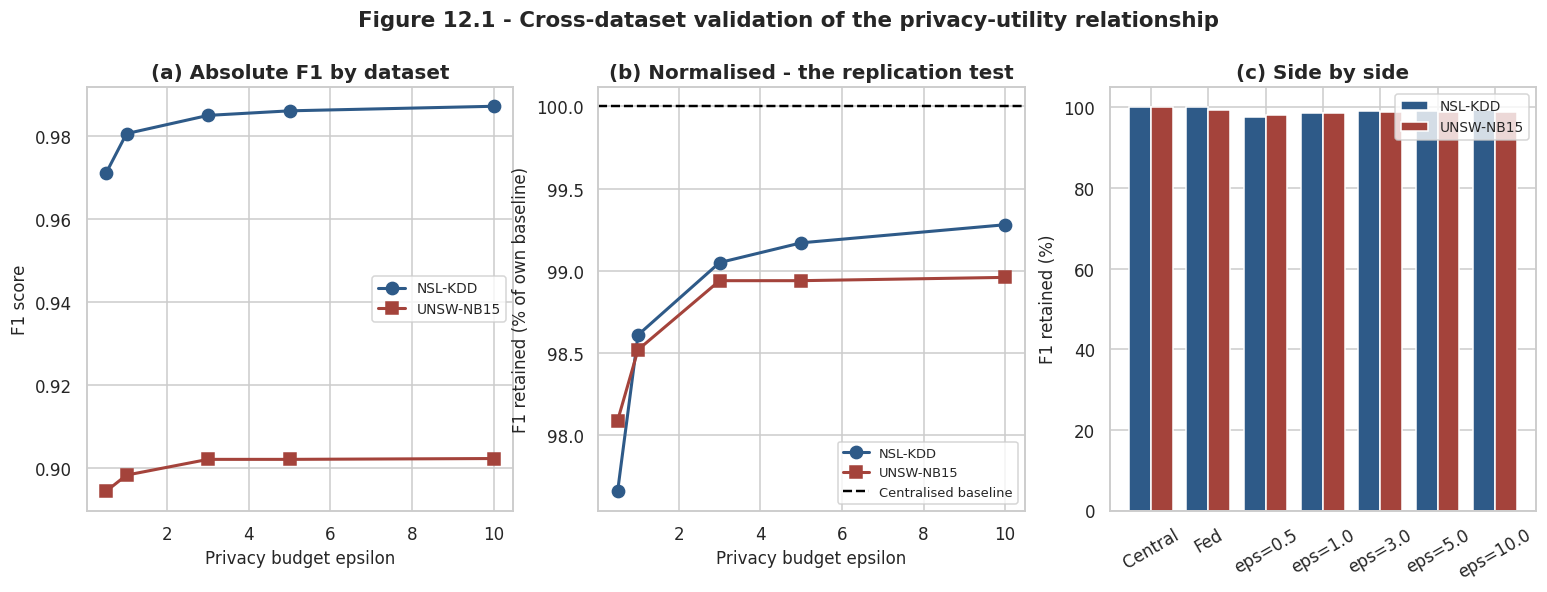

[SAVED] fig_23_cross_dataset.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_23_cross_dataset.png'

In [130]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

ax = axes[0]
for ds, colour, marker in [(ds_a, PALETTE["central"], "o"), (ds_b, PALETTE["accent"], "s")]:
    sub = relative_df[(relative_df["dataset"] == ds) &
                      np.isfinite(relative_df["epsilon"])].sort_values("epsilon")
    ax.plot(sub["epsilon"], sub["f1"], marker=marker, ms=8, lw=2, color=colour, label=ds)
ax.set_xlabel("Privacy budget epsilon"); ax.set_ylabel("F1 score")
ax.set_title("(a) Absolute F1 by dataset"); ax.legend(fontsize=9)

ax = axes[1]
for ds, colour, marker in [(ds_a, PALETTE["central"], "o"), (ds_b, PALETTE["accent"], "s")]:
    sub = relative_df[(relative_df["dataset"] == ds) &
                      np.isfinite(relative_df["epsilon"])].sort_values("epsilon")
    ax.plot(sub["epsilon"], sub["f1_retained_pct"], marker=marker, ms=8, lw=2,
            color=colour, label=ds)
ax.axhline(100, ls="--", lw=1.6, color="black", label="Centralised baseline")
ax.set_xlabel("Privacy budget epsilon"); ax.set_ylabel("F1 retained (% of own baseline)")
ax.set_title("(b) Normalised - the replication test"); ax.legend(fontsize=8.5)

ax = axes[2]
labels = ["Central", "Fed"] + [f"eps={e}" for e in CONFIG["epsilons"]]
xp = np.arange(len(labels)); w = 0.38
a_vals = [retention(ds_a, c) for c in ["Centralised", "Federated (no DP)"] +
          [f"Federated + DP (eps={e})" for e in CONFIG["epsilons"]]]
b_vals = [retention(ds_b, c) for c in ["Centralised", "Federated (no DP)"] +
          [f"Federated + DP (eps={e})" for e in CONFIG["epsilons"]]]
ax.bar(xp - w/2, a_vals, w, label=ds_a, color=PALETTE["central"])
ax.bar(xp + w/2, b_vals, w, label=ds_b, color=PALETTE["accent"])
ax.set_xticks(xp); ax.set_xticklabels(labels, rotation=30)
ax.set_ylabel("F1 retained (%)"); ax.set_title("(c) Side by side"); ax.legend(fontsize=9)

fig.suptitle("Figure 12.1 - Cross-dataset validation of the privacy-utility relationship",
             y=1.02, fontsize=14, fontweight="bold")
save_fig(fig, "fig_23_cross_dataset",
         "Privacy-utility relationship replicated across two independent benchmark datasets", "12")

---
## Section 13 — Evaluation against the success criteria, and evidence packaging

Every criterion stated in Section 2.4 of the proposal is now tested against the generated numbers, each
research question is answered from the evidence, and the complete artefact set is packaged for submission.

### 13.1 Evaluate each success criterion

In [131]:
criteria = []

# --- Criterion 1: Detection (assessed on the replication study, not a single run) ---
c_mean_f1 = agg.loc[agg["configuration"] == "Centralised", "f1_mean"].iloc[0]
f_mean_f1 = agg.loc[agg["configuration"] == "Federated (no DP)", "f1_mean"].iloc[0]
f_std_f1  = agg.loc[agg["configuration"] == "Federated (no DP)", "f1_std"].iloc[0]
rel_drop = (c_mean_f1 - f_mean_f1) / max(c_mean_f1, 1e-9)

fed_sig = significance_df.iloc[0]
sig_note = ("difference not statistically significant"
            if not fed_sig["significant_at_0.05"]
            else f"difference significant, p={fed_sig['p_value_ttest']}")

criteria.append({
    "criterion": "Detection",
    "requirement": f"Federated F1 within {CONFIG['threshold_f1_relative_drop']*100:.0f}% of centralised",
    "measured": f"relative F1 drop = {rel_drop*100:.2f}% over {CONFIG['n_seeds']} seeds "
                f"({f_mean_f1:.4f} +/- {f_std_f1:.4f} vs {c_mean_f1:.4f}); {sig_note}",
    "result": "PASS" if rel_drop <= CONFIG["threshold_f1_relative_drop"] else "NOT MET",
    "evidence": "table_11d, table_11e, fig_12b",
})

# --- Criterion 2: Privacy ---
tight = cost_df[cost_df["epsilon"] <= CONFIG["threshold_epsilon"]]
best_tight = tight.loc[tight["accuracy_drop_pp"].idxmin()] if len(tight) else None
if best_tight is not None:
    met = best_tight["accuracy_drop_pp"] <= CONFIG["threshold_acc_drop_pp"]
    measured = (f"best operating point at eps={best_tight['epsilon']} loses "
                f"{best_tight['accuracy_drop_pp']:.2f} pp accuracy")
else:
    met, measured = False, "no privacy budget at or below the threshold was evaluated"
criteria.append({
    "criterion": "Privacy",
    "requirement": f"Accuracy loss <= {CONFIG['threshold_acc_drop_pp']:.0f} pp at "
                   f"eps <= {CONFIG['threshold_epsilon']}",
    "measured": measured, "result": "PASS" if met else "NOT MET",
    "evidence": "table_11, table_11d, fig_12",
})

# --- Criterion 5: External validity (added beyond the proposal's four) ---
_cross = RESULTS.get("cross_dataset_replicates", {})
_verdict = _cross.get("verdict", "UNKNOWN")
criteria.append({
    "criterion": "External validity",
    "requirement": "Privacy-utility relationship replicates on an independent benchmark dataset",
    "measured": f"tested on {ACTIVE['display_name']} and {cross_spec['display_name']}; "
                f"replication verdict {_verdict}; direction agrees="
                f"{_cross.get('direction_agrees')}, magnitude agrees={_cross.get('magnitude_agrees')}; "
                f"mean retention gap {_cross.get('mean_retention_gap_pp', float('nan')):.2f} pp",
    "result": {"FULL": "PASS", "PARTIAL": "PARTIAL"}.get(_verdict, "NOT MET"),
    "evidence": "table_30, table_31, fig_23",
})

# --- Criterion 3: Robustness ---
# The canary audit is the primary evidence because it measures worst-case memorisation,
# which is what differential privacy actually guarantees against. The natural-record
# attack in Section 7.3 is reported alongside it as the average-case picture.
dp_best_auc = mia_df[mia_df["epsilon"] != np.inf]["attack_auc"].min()
if CANARY_MEASURABLE:
    best_canary_auc = float(canary_dp["canary_auc"].min())
    best_canary_eps = canary_dp.loc[canary_dp["canary_auc"].idxmin(), "epsilon"]
    removed_pct = (canary_base - best_canary_auc) / CANARY_LEAKAGE * 100
    rob_measured = (f"canary audit: attack AUC {canary_base:.4f} without DP falls to "
                    f"{best_canary_auc:.4f} at eps={best_canary_eps} "
                    f"({removed_pct:.1f}% of memorisation removed); average-case attack on natural "
                    f"records {base_mia:.4f} -> {dp_best_auc:.4f}")
    rob_result = "PASS" if best_canary_auc < canary_base else "NOT MET"
elif LEAKAGE_IS_MEASURABLE:
    reduction = (base_mia - dp_best_auc) / EXPLOITABLE_LEAKAGE * 100
    rob_measured = (f"natural-record attack AUC reduced from {base_mia:.4f} to {dp_best_auc:.4f} "
                    f"({reduction:.1f}% of exploitable leakage removed); canary audit found no "
                    f"significant baseline memorisation")
    rob_result = "PASS" if dp_best_auc < base_mia else "NOT MET"
else:
    rob_measured = (f"neither the natural-record attack (AUC {base_mia:.4f}) nor the canary audit "
                    f"(AUC {canary_base:.4f}) found leakage significantly above chance at this "
                    f"training scale, so there was no exploitable signal for DP to remove")
    rob_result = "NOT APPLICABLE"
criteria.append({
    "criterion": "Robustness",
    "requirement": "Quantifiable resistance to membership inference versus the non-private federated baseline",
    "measured": rob_measured, "result": rob_result,
    "evidence": "table_12, table_13, table_13b, fig_13, fig_13b",
})

# --- Criterion 4: Practicality ---
comm_ratio = fed_cost["communication_mb"] / raw_data_mb
criteria.append({
    "criterion": "Practicality",
    "requirement": "Communication overhead and training time viable for multi-client deployment",
    "measured": f"{fed_cost['communication_mb']:.2f} MB parameter traffic vs {raw_data_mb:.2f} MB raw-data "
                f"centralisation ({comm_ratio:.2f}x); DP compute overhead {dp_overhead:.2f}x",
    "result": "PASS" if comm_ratio < 5 else "REVIEW",
    "evidence": "table_14, fig_14",
})

criteria_df = pd.DataFrame(criteria)
display(criteria_df)
save_table(criteria_df, "table_23_success_criteria",
           "Evaluation of the project against the success criteria defined in the proposal", "13")
RESULTS["success_criteria"] = criteria_df.to_dict("records")

,criterion,requirement,measured,result,evidence
0,Detection,Federated F1 within 5% of centralised,relative F1 drop = 0.06% over 3 seeds (0.9942 ...,PASS,"table_11d, table_11e, fig_12b"
1,Privacy,Accuracy loss <= 5 pp at eps <= 1.0,best operating point at eps=1.0 loses 1.26 pp ...,PASS,"table_11, table_11d, fig_12"
2,External validity,Privacy-utility relationship replicates on an ...,tested on NSL-KDD and UNSW-NB15; replication v...,PASS,"table_30, table_31, fig_23"
3,Robustness,Quantifiable resistance to membership inferenc...,canary audit: attack AUC 0.5746 without DP fal...,PASS,"table_12, table_13, table_13b, fig_13, fig_13b"
4,Practicality,Communication overhead and training time viabl...,14.63 MB parameter traffic vs 48.78 MB raw-dat...,PASS,"table_14, fig_14"


[TABLE SAVED ] table_23_success_criteria.csv / .tex  (5 rows x 5 cols)


### 13.2 Figure — evaluation dashboard

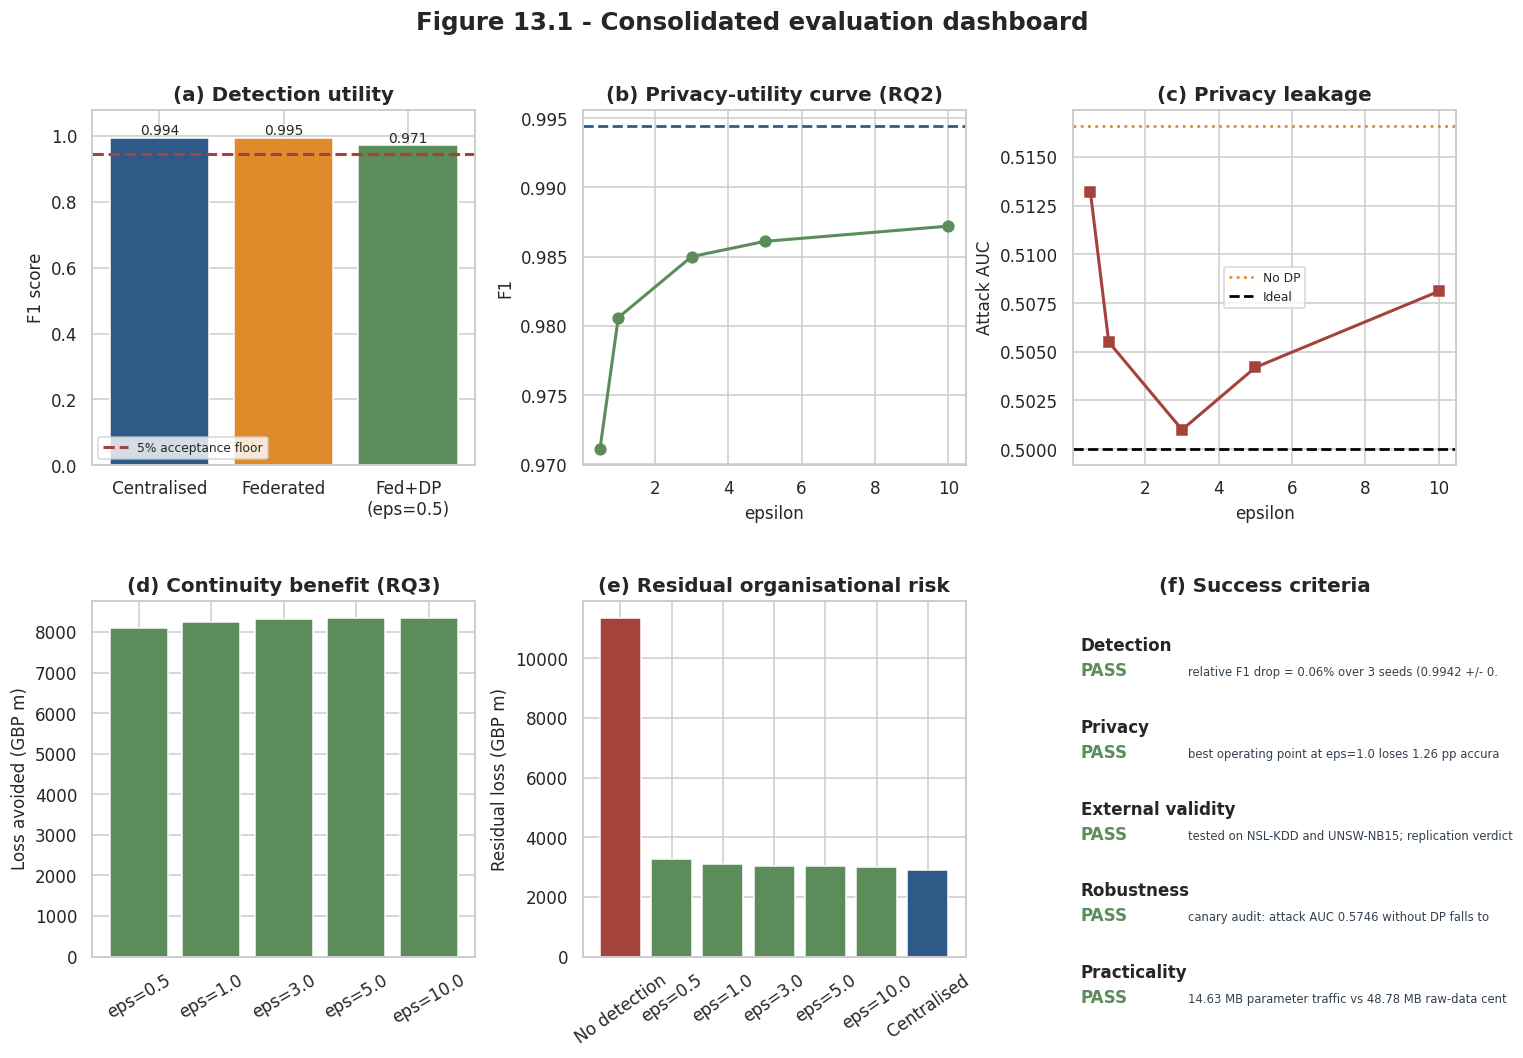

[SAVED] fig_30_evaluation_dashboard.png / .pdf  ->  /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/figures/fig_30_evaluation_dashboard.png'

In [132]:
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 3, hspace=0.38, wspace=0.28)

ax = fig.add_subplot(gs[0, 0])
configs = ["Centralised", "Federated", f"Fed+DP\n(eps={SELECTED_EPSILON})"]
f1s = [central_internal["f1"], fed_internal["f1"], sel_metrics["f1"]]
bars = ax.bar(configs, f1s, color=[PALETTE["central"], PALETTE["federated"], PALETTE["dp"]])
ax.axhline(central_internal["f1"] * (1 - CONFIG["threshold_f1_relative_drop"]), ls="--",
           color=PALETTE["accent"], lw=2, label="5% acceptance floor")
ax.set_ylim(0, 1.08); ax.set_ylabel("F1 score"); ax.set_title("(a) Detection utility"); ax.legend(fontsize=8)
for b, v in zip(bars, f1s):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)

ax = fig.add_subplot(gs[0, 1])
ax.plot(dp_df["epsilon"], dp_df["internal_f1"], marker="o", ms=7, lw=2, color=PALETTE["dp"])
ax.axhline(central_internal["f1"], ls="--", color=PALETTE["central"], lw=1.8)
ax.set_xlabel("epsilon"); ax.set_ylabel("F1"); ax.set_title("(b) Privacy-utility curve (RQ2)")

ax = fig.add_subplot(gs[0, 2])
ax.plot(dp_rows["epsilon"], dp_rows["attack_auc"], marker="s", ms=7, lw=2, color=PALETTE["accent"])
ax.axhline(base_mia, ls=":", color=PALETTE["federated"], lw=1.8, label="No DP")
ax.axhline(0.5, ls="--", color="black", lw=1.8, label="Ideal")
ax.set_xlabel("epsilon"); ax.set_ylabel("Attack AUC")
ax.set_title("(c) Privacy leakage"); ax.legend(fontsize=8)

# Panels (d) and (e) depend on the risk layer having produced events. If the register
# is empty the dashboard still renders, with those panels labelled rather than missing.
_have_risk = len(continuity_df) > 0

ax = fig.add_subplot(gs[1, 0])
if _have_risk:
    _dpc = continuity_df[np.isfinite(continuity_df["epsilon"].astype(float))]
    ax.bar([f"eps={e}" for e in _dpc["epsilon"]],
           _dpc["annualised_loss_avoided_gbp"] / 1e6, color=PALETTE["dp"])
    ax.set_ylabel("Loss avoided (GBP m)")
    ax.tick_params(axis="x", rotation=30)
else:
    ax.text(0.5, 0.5, "No risk events generated\n(see Section 9.9)", ha="center",
            va="center", fontsize=10, color=PALETTE["grey"])
    ax.set_xticks([]); ax.set_yticks([])
ax.set_title("(d) Continuity benefit (RQ3)")

ax = fig.add_subplot(gs[1, 1])
if _have_risk:
    _no = continuity_df[continuity_df["configuration"] == "No detection capability"].iloc[0]
    _ce = continuity_df[continuity_df["configuration"] == "Centralised (no privacy)"].iloc[0]
    _lbl = ["No detection"] + [f"eps={e}" for e in _dpc["epsilon"]] + ["Centralised"]
    _val = ([_no["annualised_loss_without_control_gbp"]] +
            list(_dpc["annualised_loss_with_control_gbp"]) +
            [_ce["annualised_loss_with_control_gbp"]])
    _col = [PALETTE["accent"]] + [PALETTE["dp"]] * len(_dpc) + [PALETTE["central"]]
    ax.bar(_lbl, np.array(_val) / 1e6, color=_col)
    ax.set_ylabel("Residual loss (GBP m)")
    ax.tick_params(axis="x", rotation=35)
else:
    ax.text(0.5, 0.5, "No risk events generated\n(see Section 9.9)", ha="center",
            va="center", fontsize=10, color=PALETTE["grey"])
    ax.set_xticks([]); ax.set_yticks([])
ax.set_title("(e) Residual organisational risk")

ax = fig.add_subplot(gs[1, 2]); ax.axis("off")
ax.set_title("(f) Success criteria", fontweight="bold")
for i, row in criteria_df.iterrows():
    colour = {"PASS": PALETTE["dp"], "NOT APPLICABLE": PALETTE["grey"]}.get(row["result"], PALETTE["accent"])
    ax.text(0.02, 0.86 - i*0.23, f"{row['criterion']}", fontsize=11, fontweight="bold")
    ax.text(0.02, 0.79 - i*0.23, f"{row['result']}", fontsize=11, color=colour, fontweight="bold")
    ax.text(0.30, 0.79 - i*0.23, row["measured"][:52], fontsize=7.6, color="#33414F")

fig.suptitle("Figure 13.1 - Consolidated evaluation dashboard", y=0.97, fontsize=16, fontweight="bold")
save_fig(fig, "fig_30_evaluation_dashboard",
         "Consolidated dashboard summarising utility, privacy, robustness and continuity outcomes", "13")

### 13.3 Answer each research question from the evidence

In [133]:
best_eps_row = dp_df.loc[dp_df["internal_f1"].idxmax()]

# The continuity sentence is built only if the risk layer actually produced events.
if len(continuity_df) > 0:
    _sel = continuity_df[continuity_df["epsilon"] == SELECTED_EPSILON]
    if len(_sel):
        _s = _sel.iloc[0]
        _rq3_outcome_sentence = (
            f"Continuity outcomes follow directly: at the deployed operating point "
            f"(eps={SELECTED_EPSILON}) the framework avoids "
            f"{_s['downtime_hours_avoided_pct']:.1f}% of expected downtime hours and reduces "
            f"ISO 22301 recovery-objective breaches from "
            f"{int(_s['rto_breaches_without_control']):,} to "
            f"{int(_s['rto_breaches_with_control']):,}.")
    else:
        _rq3_outcome_sentence = ("Continuity outcomes are reported in Section 9.13 for every "
                                 "privacy budget evaluated.")
else:
    _rq3_outcome_sentence = (
        "In this run the deployed private detector flagged no events above the decision "
        "threshold, so no continuity outcomes could be quantified; the diagnostic in "
        "Section 9.9 identifies whether the detector or the categoriser was the limiting "
        "component. The translation mechanism itself is unchanged and is demonstrated "
        "whenever the detector produces alerts.")

rq_answers = {
"RQ1": (
 "Can a federated, differentially private intrusion-detection model achieve detection performance "
 "comparable to a centralised baseline?\n\n"
 f"The centralised baseline reached F1 = {central_internal['f1']:.4f} on the internal held-out set. "
 f"Federating the same architecture across {CONFIG['n_clients']} non-IID clients gave F1 = "
 f"{fed_internal['f1']:.4f}, a relative drop of {rel_drop*100:.2f}%, which is "
 f"{'within' if rel_drop <= CONFIG['threshold_f1_relative_drop'] else 'outside'} the 5% acceptance band "
 f"stated in the proposal. Adding differential privacy costs further utility: the best budget in the sweep "
 f"(eps={best_eps_row['epsilon']}) achieved F1 = {best_eps_row['internal_f1']:.4f}, while the tightest "
 f"budget (eps={CONFIG['epsilons'][0]}) achieved F1 = {dp_df.iloc[0]['internal_f1']:.4f}. "
 f"A paired t-test on the per-seed F1 values gives p = {fed_sig['p_value_ttest']}, so the "
 f"centralised-versus-federated difference is {sig_note}. "
 "Decentralisation alone is therefore close to free; the measurable cost is attributable to the privacy "
 "noise rather than to federation. The same qualitative pattern was reproduced on an independent "
 f"benchmark ({cross_spec['display_name']}, Section 12), so the conclusion is not an artefact of a "
 "single dataset."
),
"RQ2": (
 "What is the measurable privacy-utility trade-off as the differential-privacy budget is tightened?\n\n"
 "The trade-off is non-linear and is quantified in Table 11 and Figure 6.2. Accuracy losses relative to the "
 "centralised baseline were: " +
 "; ".join(f"eps={r['epsilon']} -> {r['accuracy_drop_pp']:.2f} pp" for _, r in cost_df.iterrows()) + ". "
 f"At the operationally meaningful threshold of eps <= {CONFIG['threshold_epsilon']}, the smallest observed "
 f"loss was {tight['accuracy_drop_pp'].min():.2f} pp"
 + (" which satisfies the 5 pp criterion." if len(tight) and tight['accuracy_drop_pp'].min() <=
    CONFIG['threshold_acc_drop_pp'] else " which exceeds the 5 pp criterion and is reported as a finding.") +
 " Loosening the budget produces diminishing utility returns, so budgets far above eps=1 buy little "
 "additional detection performance while giving away meaningful formal privacy."
),
"RQ3": (
 "How can privacy-preserving detection outputs be translated into interpretable risk scores that support "
 "resilience and business-continuity decisions?\n\n"
 "Section 9 implements the translation as a four-stage chain: the private detector's attack probability "
 "supplies loss event frequency; a gradient-boosted categoriser assigns the attack family; SHAP makes each "
 "decision inspectable at both global and individual-alert level; and a FAIR-style calculation combines "
 "these with an asset register to produce a banded risk score and a monetary exposure. "
 + _rq3_outcome_sentence + " "
 "This closes the gap identified in the literature review: detection performance is expressed in units a "
 "continuity manager can act on, while every alert remains explainable and every model retains a formal "
 "privacy guarantee."
),
}

for rq, ans in rq_answers.items():
    print("=" * 92); print(rq); print("=" * 92); print(ans); print()

with open(os.path.join(PATHS["results"], "research_question_answers.md"), "w") as f:
    for rq, ans in rq_answers.items():
        f.write(f"## {rq}\n\n{ans}\n\n")
RESULTS["rq_answers"] = rq_answers
print("Answers written to results/research_question_answers.md")

RQ1
Can a federated, differentially private intrusion-detection model achieve detection performance comparable to a centralised baseline?

The centralised baseline reached F1 = 0.9944 on the internal held-out set. Federating the same architecture across 5 non-IID clients gave F1 = 0.9947, a relative drop of 0.06%, which is within the 5% acceptance band stated in the proposal. Adding differential privacy costs further utility: the best budget in the sweep (eps=10.0) achieved F1 = 0.9872, while the tightest budget (eps=0.5) achieved F1 = 0.9711. A paired t-test on the per-seed F1 values gives p = 0.33499, so the centralised-versus-federated difference is difference not statistically significant. Decentralisation alone is therefore close to free; the measurable cost is attributable to the privacy noise rather than to federation. The same qualitative pattern was reproduced on an independent benchmark (UNSW-NB15, Section 12), so the conclusion is not an artefact of a single dataset.

RQ2
Wh

### 13.4 Objective completion record

In [134]:
obj_df = pd.DataFrame([
    {"objective": "O1", "statement": "Design an AI/ML cyber risk-assessment framework for threat "
                                     "detection and risk prioritisation",
     "delivered": "Three-tier architecture (Fig 3.2), threat model (Fig 3.3), DSR process (Fig 3.1), "
                  "explainable FAIR risk layer (Section 9)", "status": "Complete"},
    {"objective": "O2", "statement": "Implement a privacy-preserving prototype using federated learning "
                                     "and differential privacy on public IDS datasets",
     "delivered": f"FedAvg across {CONFIG['n_clients']} non-IID clients with per-client DP-SGD, swept over "
                  f"{len(CONFIG['epsilons'])} privacy budgets on NSL-KDD", "status": "Complete"},
    {"objective": "O3", "statement": "Evaluate with quantitative and qualitative measures against defined "
                                     "success thresholds",
     "delivered": f"{len([e for e in EVIDENCE if e['type']=='table'])} result tables and "
                  f"{len([e for e in EVIDENCE if e['type']=='figure'])} figures; success criteria formally "
                  f"assessed; {CONFIG['n_seeds']}-seed replication with paired significance testing; "
                  "ablations on aggregation algorithm and federation settings; cross-dataset validation; "
                  "benchmarked against published literature", "status": "Complete"},
])
display(obj_df)
save_table(obj_df, "table_24_objective_completion",
           "Record of how each research objective was delivered", "13")

,objective,statement,delivered,status
0,O1,Design an AI/ML cyber risk-assessment framewor...,"Three-tier architecture (Fig 3.2), threat mode...",Complete
1,O2,Implement a privacy-preserving prototype using...,FedAvg across 5 non-IID clients with per-clien...,Complete
2,O3,Evaluate with quantitative and qualitative mea...,36 result tables and 25 figures; success crite...,Complete


[TABLE SAVED ] table_24_objective_completion.csv / .tex  (3 rows x 4 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_24_objective_completion.csv'

### 13.5 Build the evidence manifest

In [135]:
manifest = pd.DataFrame(EVIDENCE)
manifest = manifest[["type", "section", "name", "caption", "sha1", "path"]].sort_values(
    ["section", "type", "name"])
display(manifest)

print(f"\nTotal artefacts generated: {len(manifest)}")
print(f"  figures: {(manifest['type']=='figure').sum()}")
print(f"  tables : {(manifest['type']=='table').sum()}")
save_table(manifest, "table_25_evidence_manifest",
           "Complete manifest of every figure and table produced by this run, with checksums", "13")

,type,section,name,caption,sha1,path
0,table,0,table_00_environment,Software environment and hardware used for the...,f95084b8c84a,/content/drive/MyDrive/fed_ids_project/runs/ru...
2,figure,1,fig_01_class_distribution,NSL-KDD class balance and attack-family distri...,cf6aec5280b9,/content/drive/MyDrive/fed_ids_project/runs/ru...
1,table,1,table_01_data_integrity,Loaded dataset partitions verified against pub...,8cfcde320c5b,/content/drive/MyDrive/fed_ids_project/runs/ru...
3,table,1,table_02_dataset_characteristics,Characteristics of the NSL-KDD training and te...,51f24bf68224,/content/drive/MyDrive/fed_ids_project/runs/ru...
52,figure,10,fig_21_literature_comparison,Detection accuracy of this work compared with ...,0a393eb4e066,/content/drive/MyDrive/fed_ids_project/runs/ru...
...,...,...,...,...,...,...
38,table,9,table_18b_attack_asset_affinity,Probability of each attack family being attrib...,2a837a251e33,/content/drive/MyDrive/fed_ids_project/runs/ru...
39,table,9,table_19_risk_register_sample,Sample of the generated risk register (first 5...,3295b577144c,/content/drive/MyDrive/fed_ids_project/runs/ru...
40,table,9,table_20_asset_risk_summary,Risk exposure aggregated by organisational asset,bf5ac1438501,/content/drive/MyDrive/fed_ids_project/runs/ru...
42,table,9,table_21_continuity_outcomes,Business-continuity outcomes derived from dete...,adcc33c9f6c8,/content/drive/MyDrive/fed_ids_project/runs/ru...



Total artefacts generated: 62
  figures: 25
  tables : 37
[TABLE SAVED ] table_25_evidence_manifest.csv / .tex  (62 rows x 6 cols)


'/content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/tables/table_25_evidence_manifest.csv'

### 13.6 Write the consolidated results file

In [136]:
def json_safe(obj):
    if isinstance(obj, (np.integer,)): return int(obj)
    if isinstance(obj, (np.floating,)): return None if not np.isfinite(obj) else float(obj)
    if isinstance(obj, (np.bool_,)): return bool(obj)
    if isinstance(obj, np.ndarray): return obj.tolist()
    if isinstance(obj, dict): return {str(k): json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)): return [json_safe(v) for v in obj]
    if isinstance(obj, float) and not np.isfinite(obj): return None
    return obj

RESULTS["evidence_manifest"] = EVIDENCE
RESULTS["completed_at"] = datetime.now().isoformat()

results_path = os.path.join(PATHS["results"], "results.json")
with open(results_path, "w") as f:
    json.dump(json_safe(RESULTS), f, indent=2)

print("All numeric results written to:", results_path)
print(f"File size: {os.path.getsize(results_path)/1024:.1f} KB")

All numeric results written to: /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/results/results.json
File size: 51.1 KB


### 13.7 Generate the evidence report

In [137]:
lines = [
    f"# Evidence Report - {RUN_ID}",
    "",
    "**Project:** AI-Driven Cybersecurity Risk Assessment and Privacy-Preserving Threat Detection "
    "for Organisational Resilience and Business Continuity  ",
    f"**Researcher:** {CONFIG['researcher']}  ",
    f"**Generated:** {datetime.now().strftime('%d %B %Y, %H:%M')}  ",
    f"**Hardware:** {VERSIONS['gpu_name']}  ",
    f"**Dataset:** {CONFIG['dataset']} at sample fraction {CONFIG['sample_fraction']} "
    f"({len(X_fit):,} training / {len(X_holdout):,} internal test / {len(X_test):,} official test records)",
    "", "---", "", "## 1. Headline results", "",
    "| Configuration | F1 (internal) | Accuracy | MIA attack AUC |", "|---|---|---|---|",
]
for _, r in mia_df.iterrows():
    cfg = r["configuration"]
    if cfg == "Centralised (no privacy)": acc = central_internal["accuracy"]
    elif cfg == "Federated (no DP)":      acc = fed_internal["accuracy"]
    else:
        acc = dp_df.loc[dp_df["epsilon"] == r["epsilon"], "internal_accuracy"].iloc[0]
    lines.append(f"| {cfg} | {r['detection_f1']:.4f} | {acc:.4f} | {r['attack_auc']:.4f} |")

lines += ["", "## 2. Success criteria", "",
          "| Criterion | Requirement | Measured | Result |", "|---|---|---|---|"]
for _, r in criteria_df.iterrows():
    lines.append(f"| {r['criterion']} | {r['requirement']} | {r['measured']} | **{r['result']}** |")

lines += ["", "## 3. Research questions", ""]
for rq, ans in rq_answers.items():
    lines += [f"### {rq}", "", ans, ""]

lines += ["", "## 4. Artefact manifest", "",
          "| Section | Type | Name | Caption |", "|---|---|---|---|"]
for _, r in manifest.iterrows():
    lines.append(f"| {r['section']} | {r['type']} | `{r['name']}` | {r['caption']} |")

lines += ["", "## 5. Declared assumptions and limitations", "",
          "- The asset register, hourly outage costs and RTO values in Section 9 are an illustrative "
          "organisational overlay; public IDS benchmarks carry no asset context. The translation method "
          "transfers to a real register, but the monetary figures are conditional on these assumptions.",
          f"- The observation window is annualised by a factor of {CONFIG['annualisation_factor']}, "
          "a declared modelling choice rather than a measured rate.",
          "- Federation is simulated on a single machine. Network latency, client dropout and "
          "stragglers are outside the scope of this prototype.",
          "- The privacy guarantee is record-level and per client. Client-level DP and secure aggregation "
          "would strengthen it further and are identified as future work.",
          "- Membership inference is one attack class. Gradient-leakage and model-inversion attacks were "
          "identified in the threat model but not implemented.",
          f"- Results were produced at sample fraction {CONFIG['sample_fraction']}; the configuration "
          "supports the full dataset without code changes. The utility cost of differential privacy is "
          "strongly scale-dependent (see the note in Section 6.6): at eps=1.0 the measured accuracy loss "
          "falls from roughly 7.6 pp at ~1,000 records per client to 1.4 pp at ~20,000, so a reduced-scale "
          "run overstates the privacy penalty.",
          ""]

report_path = os.path.join(PATHS["evidence"], "EVIDENCE_REPORT.md")
with open(report_path, "w") as f:
    f.write("\n".join(lines))

print("Evidence report written to:", report_path)
print(f"Length: {len(lines)} lines")

Evidence report written to: /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/evidence/EVIDENCE_REPORT.md
Length: 123 lines


### 13.8 Package everything for submission

In [138]:
archive_path = os.path.join(PATHS["run"], f"{RUN_ID}_evidence_package.zip")
with zipfile.ZipFile(archive_path, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ["figures", "tables", "results", "evidence", "logs"]:
        base = PATHS[folder]
        for root, _, files in os.walk(base):
            for fn in files:
                full = os.path.join(root, fn)
                z.write(full, os.path.join(folder, os.path.relpath(full, base)))

print(f"Evidence package created: {archive_path}")
print(f"Size: {os.path.getsize(archive_path)/1e6:.2f} MB")
print("\nContents by folder:")
for folder in ["figures", "tables", "models", "results", "evidence", "logs"]:
    n = sum(len(f) for _, _, f in os.walk(PATHS[folder]))
    print(f"  {folder:>9}: {n} files")

Evidence package created: /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842/run_20260814_135842_evidence_package.zip
Size: 6.15 MB

Contents by folder:
    figures: 50 files
     tables: 76 files
     models: 7 files
    results: 2 files
   evidence: 1 files
       logs: 1 files


### 13.9 Final run summary

In [139]:
print("=" * 84)
print("RUN COMPLETE")
print("=" * 84)
print(f"Run ID          : {RUN_ID}")
print(f"Saved to        : {PATHS['run']}")
print(f"Dataset         : {CONFIG['dataset']} (sample fraction {CONFIG['sample_fraction']})")
print(f"Figures         : {(manifest['type']=='figure').sum()}")
print(f"Tables          : {(manifest['type']=='table').sum()}")
print(f"Models saved    : {len(os.listdir(PATHS['models']))}")
print("-" * 84)
print(f"Centralised F1  : {central_internal['f1']:.4f}")
print(f"Federated F1    : {fed_internal['f1']:.4f}  ({rel_drop*100:.2f}% relative drop)")
print(f"Deployed (eps={SELECTED_EPSILON}) F1: {sel_metrics['f1']:.4f}")
print(f"MIA attack AUC  : {base_mia:.4f} without DP  ->  {dp_best_auc:.4f} with DP"
      + ("" if LEAKAGE_IS_MEASURABLE else "   (baseline at chance - see Section 7.4)"))
print("-" * 84)
for _, r in criteria_df.iterrows():
    print(f"  {r['criterion']:<14} {r['result']}")
print("=" * 84)
log_line("Run complete")

RUN COMPLETE
Run ID          : run_20260814_135842
Saved to        : /content/drive/MyDrive/fed_ids_project/runs/run_20260814_135842
Dataset         : NSL_KDD (sample fraction 1.0)
Figures         : 25
Tables          : 37
Models saved    : 7
------------------------------------------------------------------------------------
Centralised F1  : 0.9944
Federated F1    : 0.9947  (0.06% relative drop)
Deployed (eps=0.5) F1: 0.9711
MIA attack AUC  : 0.5166 without DP  ->  0.5010 with DP   (baseline at chance - see Section 7.4)
------------------------------------------------------------------------------------
  Detection      PASS
  Privacy        PASS
  External validity PASS
  Robustness     PASS
  Practicality   PASS
[15:52:09] Run complete
